# **🚴‍♀️ Проект спринта: Нелинейные модели против сочинской погоды**

Компания **BikeSochi**, оператор городского велопроката в Сочи, обратилась за помощью в улучшении системы прогнозирования почасового спроса на велосипеды.

До этого аналитики компании использовали простую линейную регрессию — одну из самых базовых моделей машинного обучения.

Однако её прогнозы часто ошибались:



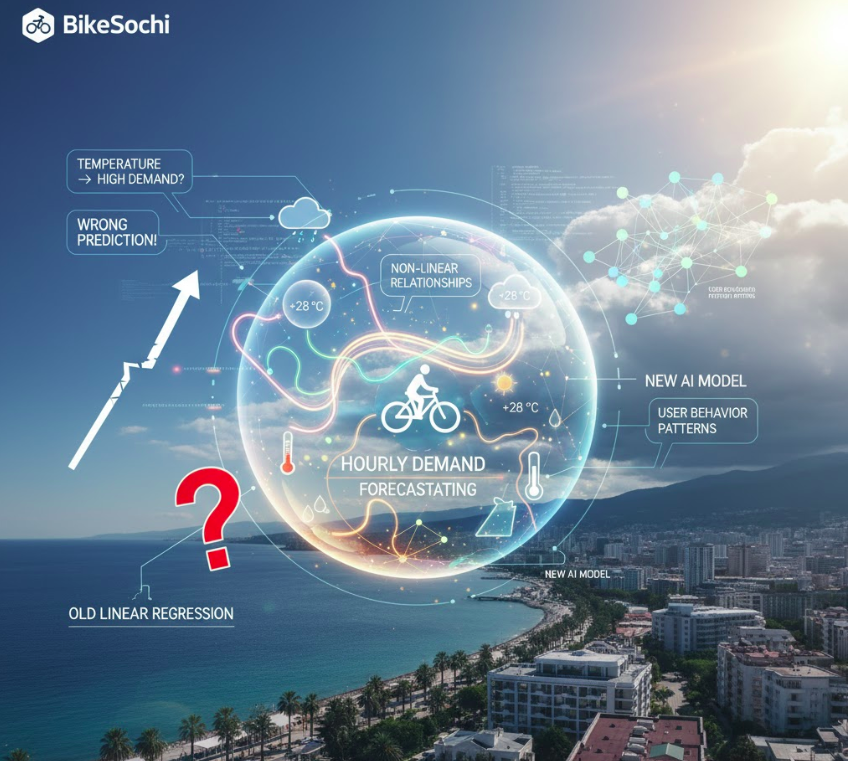

> «Модель видела, что температура выросла — и сразу предсказывала высокий спрос.
Но не понимала, что +28 °C под палящим солнцем и +28 °C после дождя — это две совсем разные ситуации.»

Погода в Сочи меняется быстро, и влияние факторов — нелинейное: температура, влажность, солнечная радиация, осадки влияют на поведение людей не по простым прямым зависимостям.



---



В рамках этого проекта вы выступаете в роли аналитиков компании **BikeSochi, которые должны предложить новую, более гибкую модель прогнозирования.**

**В этом проекте вы:**

1. Изучите предоставленную компанией baseline-модель (линейную регрессию);

2. Обучите новые модели — K-ближайших соседей (KNN) и решающее дерево (Decision Tree);

3. Проведёте подбор гиперпараметров с помощью библиотеки Optuna;

4. Сравните результаты всех подходов, выберете наилучший и аргументируете свой выбор.

Дополнительно: Реализуете собственный класс-трансформер и интегрируете его в пайплайн.


**К концу проекта у вас будет:**

— улучшенная модель прогноза почасового спроса на велосипеды в Сочи;

— отчёт с метриками и сравнением подходов;

— сохранённый пайплайн лучшей модели.



---



# **Часть 1: Базовая модель**

В этой части вы познакомитесь с тем, как работает baseline-модель, которую использовала компания BikeSochi до внедрения улучшенной версии.

Компания предоставила вам:

— baseline_linear_regression_pipeline.pkl — готовый обученный пайплайн (без исходного кода);

— краткое описание того, как он был устроен;

— тренировочную и тестовую выборки, которые можно использовать для оценки модели.

Это значит, что вам не нужно обучать эту модель заново — вы просто загружаете её и проверяете качество (например, на метриках RMSE, MAE, R²).

**Совет:**
1. Убедитесь, что у вас есть baseline_linear_regression_pipeline.pkl и train_data.csv и test_data.csv.

2. Разделите тестовый набор на признаки (X) и целевую переменную Rented Bike Count.

3. Загрузите .pkl файл — это готовый пайплайн, который сам обрабатывает данные и делает предсказания. Модель автоматически применяет трансформации и возвращает прогнозы.

4. Посчитайте RMSE, MAE и R², эти результаты нужны для оценки ваших улучшенных моделей в дальнейшей работе.

# **Часть 2: Улучшение модели — KNN и Decision Tree**

Ваша задача — предложить более гибкую модель прогноза спроса на велосипеды, которая учитывает нюансы сочинской погоды и поведение клиентов.

Вы будете экспериментировать с K-ближайшими соседями (KNN) и решающим деревом (Decision Tree), использовать подбор гиперпараметров с Optuna и внедрять кастомные трансформеры для новых признаков.

**Шаг 1: Изучение постановки задачи:**

Проведите EDA (Exploratory Data Analysis):
1. Посмотрите на распределение целевой переменной Rented Bike Count. Есть ли выбросы или сильные сезонные колебания?
2. Постройте графики зависимости спроса от температуры, осадков, солнечной радиации.
3. Сравните спрос в разные сезоны и праздничные дни.
4. Проверьте корреляции между признаками и целевой переменной.

**Совет:**

Не нужно сразу всё усложнять. Начните с базовых графиков и описательной статистики.



---



**Шаг 2: Разделение данных на тренировочную и валидационную выборки**

> У вас есть доступ к тренировочной и тестовой выборкам.

Тестовый набор используется для финальной оценки модели после тренировки и подбора гиперпараметров.

Вы тренируетесь на тренировочных данных и оцениваете качество через валидацию.

---



**Шаг 3: Обучение новых моделей**

> Теперь пора «проверить, насколько далеко уедут модели» — KNN и Decision Tree могут уловить нелинейные зависимости, недоступные линейной регрессии.

Что нужно сделать:
1. Подготовьте пайплайн для каждой модели:
    * Предобработка данных.
    * Модель (KNN или Decision Tree).
4. Настройте базовые параметры моделей (например, n_neighbors для KNN, max_depth для дерева).

**Совет:**

Начинайте с базовых параметров, чтобы убедиться, что пайплайн работает. Оптимизацию параметров делаем на следующем шаге.

---



**Шаг 4: Подбор гиперпараметров с Optuna**

> Компания хочет точную модель. Optuna поможет найти лучшие параметры для KNN и дерева, чтобы снизить ошибки прогноза.

Что нужно сделать:
1. Определите функцию цели для Optuna.

2. Настройте диапазоны гиперпараметров.

3. Запустите оптимизацию и сохраните лучшие параметры.

**Совет:**

Не бойтесь экспериментировать с небольшими диапазонами сначала, а потом расширять, если модель «не уловила» зависимости.

---



**Шаг 5: Кросс-валидация новых моделей**

Что нужно сделать:
1. Проведите кросс-валидацию для KNN и Decision Tree с оптимальными гиперпараметрами.
2. Сравните метрики с baseline-моделью.
3. Определите, какая модель показывает лучшие результаты на тренировочной выборке.

**Совет:**

Используйте визуализации (bar plot, box plot), чтобы увидеть разброс метрик и стабильность моделей.


---



**Шаг 6: Составление отчёта по моделям**

Что нужно сделать:
1. Составьте таблицу с метриками: baseline, KNN, Decision Tree.
2. Добавьте визуализацию, если необходимо: bar plot или box plot по RMSE/MAE.

Подготовьте выводы:
1. Какая модель лучше справляется с прогнозом?
2. Какие признаки, по вашему мнению, особенно важны?


**Совет:**

Старайтесь объяснить результаты в бизнес-контексте: «Эта модель лучше реагирует на дождь», «Температура и влажность сильно влияют на спрос в пиковые часы».

---



**Шаг 7: Сохранение модели и отчёта**

Что нужно сделать:
1. Выберите финальную, наилучшую модель и оцените её качество на тестовой выборке, чтобы понять, насколько она прогнозирует реальные данные.
2. Подготовьте ноутбук с кодом и комментариями: включите результаты всех экспериментов, метрики моделей, визуализации, а также обоснование выбора финальной модели.

**Совет:**

Документируйте каждый шаг: почему выбраны те или иные гиперпараметры и подходы. В реальной бизнес-задаче это помогает коллегам и руководству понимать решения и доверять модели.

---



**Опционально: Реализация кастомного трансформера**

> Простые признаки вроде температуры или влажности не всегда отражают реальную ситуацию.
Чтобы модель могла лучше прогнозировать спрос на велосипеды, можно создавать новые признаки, которые учитывают особенности погоды или взаимодействия факторов.

Что нужно сделать:
1. Реализуйте класс с методами fit и transform.
2. Вставьте его в пайплайн перед моделью.
3. Проверьте, что трансформер корректно работает с тренировочными данными.

**Совет:**
Если вы решите реализовать трансформер, начинайте с простых комбинаций признаков, чтобы не усложнять модель слишком рано.


---



# **Авторское решение**

# **Проект спринта: Нелинейные модели против сочинской погоды¶**

- Автор: Колодий Светлана Петровна
- Дата: 22.09.2026

Цель и задачи проекта.

Цель проекта - разработать более гибкую нелинейную модель прогнозирования почасового спроса на аренду велосипедов для компании BikeSochi, которая учитывает нюансы сочинской погоды и поведение клиентов.

Описание проекта: Модель нелинейная регрессия при обучении с учителем. Целевой переменной является количество велосипедов, арендованных пользователями за конкретный час. Для оценки используем метрики RMSE, MAE, R2, основная - RMSE. Условие внедрение модели - основная метрика должна иметь значение юольше чем базовая линейная модель.

Задачи проекта:
1. анализ baseline-модели:
- подготовка среды и библиотек
- загрузить пайплайн и оценить качество линейной регрессии на обучающей и тестовой выборках по метрикам RMSE, MAE, R²
2. исследовательский анализ данных:
- изучить датасет: типы данных, пропуски, уникальные значения,
- проанализировать распределение целевой переменной,
- построить графики зависимости показателей,
- оценить корреляции признаков с целевой переменной
3. подготовка данных:
- разделить тренировочную выборку тренировочную и валидационную,
- собрать Pipeline с масштабированием числовых признаков и кодированием категориальных.
4. обучение нелинейных моделей:
- обучить kNN Regressor с базовыми параметрами
- обучить Decision Tree Regressor с базовыми параметрами.
- проверить работают ли они корректно
5. подбор гиперпараметров с Optuna:
- для каждой модели определить функцию-цель (objective) для Optuna,
- поиск гиперпараметров,
- использовать единую схему кросс-валидации (на 5 фолдах) для всех моделей.
- целевая метрики оптимизации RMSЕ,
- запустить оптимизацию и сохранить лучшие параметры для каждой модели.
6. Сравнение моделей:
- провести кросс-валидацию лучших kNN и дерева с оптимальными гиперпараметрами 
- провести сравнение метрик с baseline-моделью: свести результаты в таблицу,  визуализировать bar plot или box plot.
- выбрать лучшую модель
7. Составление отчёта по моделям:
- создать таблицу с метриками: baseline, KNN, Decision Tree,
-  визуализировать bar plot или box plot по RMSE/MAE
- выбрать лучшую модель
8. Сохранение модели и отчёта
- обучить лучшую модель на всей тренировочной выборке,
- провести однократную проверку на отложенной тестовой выборке,
- сравнить метрики с baseline на отложенной тестовой выборке.
- проверить, что разработанная модель превосходит линейную регрессию.
- Оценить важность признаков, проанализировать, какие факторы сильнее всего влияют на спрос (температура, солнечная радиация, осадки, время суток, сезон).
- сформулировать выводы в бизнес-контексте для BikeSochi.
- сохранить финальный пайплайн лучшей модели,
- формить Jupyter-тетрадку с полным кодом, комментариями, визуализациями и выводами, 
- проверить работоспособность.


Практическая цель проекта - повысить точность прогноза спроса на аренду велосипедов для компании BikeSochi, заменив линейную регрессию на нелинейную модель, чтобы оптимизировать распределение велосипедов между станциями и снизить потери обусловленные дефицитом и простоем велосипедов.

Описание данных: 
1. В проекте будут использованы данные ds_s14_train_data.csv. с данными для обучения и валидации модели и ds_s14_test_data.csv. для для финальной проверки модели. Датасеты содержат одинаковые признаки и описание.
2. Описание датасетов: 
- Temperature - температура воздуха в градусах Цельсия
- Humidity - относительная влажность в %
- Windspeed - скорость ветра в м/с
- Visibility - видимость десятки метров
- Dew Point Temperature - точка росы в градусах Цельсия
- Solar Radiation - солнечная радиация в мегалжоулях на квадратный метр
- Rainfall - количество осадков в мм
- Snowfall - количество снега в см
- Seasons - время года
- Holiday - выходной или праздник Holiday и No Holiday
- Functioning Day - работала ли станция в этот час
- Time_Period_Night	- ночной период 00:00–05:59
- Time_Period_Morning - утренний период 06:00–09:59
- Time_Period_Daytime - дневной период 10:00–15:59
- Time_Period_Evening - вечерний период 16:00–19:59
- Time_Period_Late Evening - Поздний вечер (ночь) 20:00–23:59
- Целевая переменная - Rented Bike Count это количество велосипедов, арендованных за час в елиницах (шт)

ЧАСТЬ 1. БАЗОВАЯ МОДЕЛЬ

Подготовка среды и библиотек. Создание requirements.txt. Установим необходимые библиотеки, импортируем библиотеки, сохраним.

In [1]:
# Установка библиотек
!pip install -q \
numpy==1.26.4 \
pandas==2.2.3 \
scipy==1.13.1 \
scikit-learn==1.6.1 \
matplotlib==3.9.0 \
seaborn==0.13.2 \
pyarrow==18.1.0 \
phik==0.12.4 \
joblib==1.4.2 \
numba==0.60.0 \
optuna 

In [2]:
# Импорт библиотек
import os
import sys
import random
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import joblib
import optuna
import phik

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import json

from phik.report import plot_correlation_matrix

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import (KFold, cross_val_score, cross_validate)
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
from scipy.stats import normaltest, ks_2samp
from datetime import datetime
from optuna.visualization import matplotlib as opt_mpl

In [3]:
# сохранение библиотек
!pip freeze > requirements.txt

In [4]:
# Настройка отображения
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.4f}'.format)

# Настройка стилей графиков
try:
    if 'seaborn-v0_8-whitegrid' in plt.style.available:
        plt.style.use('seaborn-v0_8-whitegrid')
    elif 'seaborn-whitegrid' in plt.style.available:
        plt.style.use('seaborn-whitegrid')
    else:
        plt.style.use('default')
except Exception as e:
    plt.style.use('default')

sns.set_palette("husl")
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=sns.color_palette('husl'))
sns.set_context("notebook")

# Параметры отображения matplotlib
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# Размер шрифта заголовков и меток
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

# Разрешение графиков для Jupyter (retina)
%config InlineBackend.figure_format = 'retina'

# Фиксация констант
RANDOM_STATE = 42
CV_SPLITS = 5
N_JOBS = -1

print(f"RANDOM_STATE = {RANDOM_STATE}")
print('Настройки отображения успешно применены')

RANDOM_STATE = 42
Настройки отображения успешно применены


В этой части посмотрим как работает baseline-модель, которую использовала компания BikeSochi до внедрения улучшенной версии.

Компания предоставила:
- baseline_linear_regression_pipeline.pkl - готовый обученный пайплайн (без исходного кода);
- краткое описание того, как он был устроен;
- тренировочную и тестовую выборки, которые можно использовать для оценки модели.

Необходимо загрузить её и проверяете качество (на метриках RMSE, MAE, R²).

In [5]:
# Загрузка датасетов
train_dt = pd.read_csv('/datasets/ds_s14_train_data.csv')
test_dt = pd.read_csv('/datasets/ds_s14_test_data.csv')

display(train_dt.head())
test_dt.head()

,Temperature,Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature,Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day,Time_Period_Evening,Time_Period_Late Evening,Time_Period_Morning,Time_Period_Night,Rented Bike Count
0,20.3000,35.0000,2.4000,2000.0000,4.3000,0.4600,0.0000,0.0000,Autumn,Holiday,Yes,True,False,False,False,1237
1,25.4000,55.0000,3.2000,2000.0000,15.6000,0.1500,0.0000,0.0000,Autumn,No Holiday,Yes,True,False,False,False,2468
2,-6.9000,39.0000,1.6000,2000.0000,-18.5000,0.0000,0.0000,0.0000,Winter,No Holiday,Yes,False,True,False,False,186
3,-5.2000,37.0000,2.2000,2000.0000,-17.6000,0.0000,0.0000,0.0000,Winter,No Holiday,Yes,False,False,False,True,254
4,23.4000,34.0000,2.1000,2000.0000,6.6000,2.8400,0.0000,0.0000,Autumn,No Holiday,Yes,False,False,False,False,1686


,Temperature,Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature,Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day,Time_Period_Evening,Time_Period_Late Evening,Time_Period_Morning,Time_Period_Night,Rented Bike Count
0,6.7000,48.0000,0.8000,817.0000,-3.5000,0.3900,0.0000,0.0000,Winter,No Holiday,Yes,False,False,False,False,402
1,-5.3000,90.0000,1.1000,311.0000,-6.6000,0.0000,0.0000,2.2000,Winter,No Holiday,Yes,False,False,True,False,178
2,2.9000,66.0000,1.2000,173.0000,-2.8000,0.0000,0.0000,0.0000,Winter,No Holiday,Yes,False,True,False,False,219
3,23.1000,63.0000,2.6000,949.0000,15.6000,1.6800,0.0000,0.0000,Spring,No Holiday,Yes,False,False,False,False,949
4,23.3000,43.0000,1.2000,1257.0000,10.0000,1.9100,0.0000,0.0000,Summer,No Holiday,Yes,False,False,True,False,1005


Есть готовый pipeline с линейной регрессией. Загрузим его с помощью joblib.

In [6]:
baseline_pipeline = joblib.load('/datasets/baseline_linear_regression_pipeline.pkl')
print("baseline_pipeline:", type(baseline_pipeline).__name__)

baseline_pipeline: Pipeline


Подготовим данные для baseline

In [7]:
# Наименование целевого признака
TARGET = 'Rented Bike Count'

#Разделение обучающей и тестовой выборки
X_train, y_train = train_dt.drop(columns=[TARGET]), train_dt[TARGET]
X_test,  y_test  = test_dt.drop(columns=[TARGET]),  test_dt[TARGET]

Проверим качество модели: посмотрим предсказания baseline-модели и оценим качество с помощью метрик RMSE, MAE и R².

In [8]:
# Предсказания baseline модели
baseline_predictions = baseline_pipeline.predict(X_test)

baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_mae  = mean_absolute_error(y_test, baseline_predictions)
baseline_r2   = r2_score(y_test, baseline_predictions)

# Сводная таблица метрик baseline модели
baseline_metrics_df = pd.DataFrame({
    'Метрика': ['RMSE', 'MAE', 'R²'],
    'Значение': [
        f'{baseline_rmse:.2f}',
        f'{baseline_mae:.2f}',
        f'{baseline_r2:.2f}']
})

display(baseline_metrics_df)

,Метрика,Значение
0,RMSE,411.56
1,MAE,312.60
2,R²,0.59


Промежуточный вывод: 
- проведена оценка использования базовой модели линейной регрессии (в виде обученного пайплайна baseline_linear_regression_pipeline.pkl), предоставленной компанией BikeSochi. 
- Линейная регрессия обеспечивает базовый уровень прогноза, который будет служить точкой отсчёта. 
- Модель показывает среднее качество прогнозирования. 
- Высокое значение RMSE указывает, что модель допускает ошибки при прогнозировании спроса на велосипеды, что приводит к неправильному распределению веловипелов на станциях. Простой велосипедов на станциях с низким спросом, когда прогноз завышен. Это увеличивает операционные расходы на перераспределение и обслуживание неиспользуемого транспорта. 
- ожидаемый результат, поскольку линейная регрессия плохо работает со сложными нелинейными зависимостями между погодными условиями и спросом. Модель не может полноценно учитывать влияние сочетаний признаков, например таких как температура, влажности и колличество осадков одновременно. 
- Значение метрик RMSE 411.56, MAE 312.6 и R² 0.59 указывают на необходимость перехода к нелинейным моделям - kNN и дерево решений, способным улавливать взаимодействия признаков и нелинейные зависимости. Далее проведем исследования по более гибким моделям.

# **Часть 2: Улучшение модели — KNN и Decision Tree**

2.1 Исследовательский анализ данных EDA (Exploratory Data Analysis):
Сначала посмотрим датасет: структуру данных, типы признаком
Посмотрим согласуются ли между собой тренировочная и тестовая выборки.
Далее анализ будем осуществлять только на тренировочной выборке.
Посмотрим на распределение целевой переменной Rented Bike Count. Есть ли выбросы или сильные сезонные колебания?
Построим графики зависимости спроса от температуры, осадков, солнечной радиации.
Сравним спрос в разные сезоны и праздничные дни.
Проверим корреляции между признаками и целевой переменной.

In [9]:
train_dt.info()
train_dt.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7008 entries, 0 to 7007
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Temperature               7008 non-null   float64
 1   Humidity(%)               6758 non-null   float64
 2   Wind speed (m/s)          6798 non-null   float64
 3   Visibility (10m)          6749 non-null   float64
 4   Dew point temperature     7008 non-null   float64
 5   Solar Radiation (MJ/m2)   6798 non-null   float64
 6   Rainfall(mm)              6746 non-null   float64
 7   Snowfall (cm)             6745 non-null   float64
 8   Seasons                   7008 non-null   object 
 9   Holiday                   7008 non-null   object 
 10  Functioning Day           7008 non-null   object 
 11  Time_Period_Evening       7008 non-null   bool   
 12  Time_Period_Late Evening  7008 non-null   bool   
 13  Time_Period_Morning       7008 non-null   bool   
 14  Time_Per

,Temperature,Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature,Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day,Time_Period_Evening,Time_Period_Late Evening,Time_Period_Morning,Time_Period_Night,Rented Bike Count
0,20.3000,35.0000,2.4000,2000.0000,4.3000,0.4600,0.0000,0.0000,Autumn,Holiday,Yes,True,False,False,False,1237
1,25.4000,55.0000,3.2000,2000.0000,15.6000,0.1500,0.0000,0.0000,Autumn,No Holiday,Yes,True,False,False,False,2468
2,-6.9000,39.0000,1.6000,2000.0000,-18.5000,0.0000,0.0000,0.0000,Winter,No Holiday,Yes,False,True,False,False,186
3,-5.2000,37.0000,2.2000,2000.0000,-17.6000,0.0000,0.0000,0.0000,Winter,No Holiday,Yes,False,False,False,True,254
4,23.4000,34.0000,2.1000,2000.0000,6.6000,2.8400,0.0000,0.0000,Autumn,No Holiday,Yes,False,False,False,False,1686


In [10]:
train_dt.describe()

,Temperature,Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature,Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Rented Bike Count
count,7008.0000,6758.0000,6798.0000,6749.0000,7008.0000,6798.0000,6746.0000,6745.0000,7008.0000
mean,12.8129,58.2005,1.7252,1435.1568,4.0215,0.5699,0.1469,0.0748,705.6060
std,11.9247,20.3403,1.0430,607.2910,13.0334,0.8661,1.1641,0.4382,646.3118
min,-17.5000,0.0000,0.0000,27.0000,-30.6000,0.0000,0.0000,0.0000,0.0000
25%,3.3000,42.0000,0.9000,936.0000,-4.7000,0.0000,0.0000,0.0000,190.7500
50%,13.5000,57.0000,1.5000,1691.0000,5.0000,0.0100,0.0000,0.0000,504.5000
75%,22.4000,74.0000,2.3000,2000.0000,14.8000,0.9400,0.0000,0.0000,1070.0000
max,39.4000,98.0000,7.4000,2000.0000,26.8000,3.5200,35.0000,8.8000,3556.0000


В результате анализа структуры датасета установлено, что:
- содержит 7008 наблюдений и 16 признаков: 
- 8 числовых (температура, влажность, скорость ветра, видимость, точка росы, солнечная радиация, осадки, снег)
- 3 категориальных (Seasons, Holiday, Functioning Day) 
- 4 булевых (Time_Period).
- пропуски присутствуют в шести числовых признаках: Humidity(%) (250), Wind speed (m/s) (210), Visibility (10m) (259), Solar Radiation (MJ/m2) (210), Rainfall(mm) (262), Snowfall (cm) (263).Это примерно 4% от общего колличества данных их в дальнейшем необходимо обработать. 
По полученным статистическим показателям можно предположить, что присуствуют выбросы в значениях температуры, осадкам и колличеству снега.

Посмотрим есть ли дубликаты.

In [11]:
# Явные - полные дубликаты
n_full_dup = train_dt.duplicated().sum()
print(f"Полных дубликатов в train: {n_full_dup}")

# Неявные все признаки (кроме целевой переменной)
feature_cols = train_dt.drop(columns=['Rented Bike Count']).columns.tolist()
n_feat_dup = train_dt.duplicated(subset=feature_cols).sum()
print(f"Дубликатов по признакам: {n_feat_dup}")

# Неявные по ключевым погодным и календарным признакам
key_cols = ['Temperature', 'Humidity(%)', 'Wind speed (m/s)',
            'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)',
            'Seasons', 'Holiday', 'Functioning Day',
            'Time_Period_Morning', 'Time_Period_Evening',
            'Time_Period_Night', 'Time_Period_Late Evening']
n_key_dup = train_dt.duplicated(subset=key_cols).sum()
print(f"Дубликатов по ключевым признакам: {n_key_dup}")

Полных дубликатов в train: 0
Дубликатов по признакам: 0
Дубликатов по ключевым признакам: 3


In [12]:
# посмотрим на дубликаты
dups_key = train_dt[train_dt.duplicated(subset=key_cols, keep=False)].sort_values(by=key_cols)
display(dups_key)

,Temperature,Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature,Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day,Time_Period_Evening,Time_Period_Late Evening,Time_Period_Morning,Time_Period_Night,Rented Bike Count
771,-5.3000,53.0000,1.1000,1411.0000,-13.4000,0.0000,0.0000,0.0000,Winter,No Holiday,Yes,False,False,True,False,122
5235,-5.3000,53.0000,1.1000,1300.0000,-13.4000,0.0000,0.0000,0.0000,Winter,No Holiday,Yes,False,False,True,False,327
1039,22.7000,87.0000,0.5000,1072.0000,20.4000,0.0000,0.0000,0.0000,Summer,No Holiday,Yes,False,False,False,True,740
5138,22.7000,87.0000,0.5000,1187.0000,20.4000,0.0000,0.0000,0.0000,Summer,No Holiday,Yes,False,False,False,True,586
6537,28.3000,83.0000,1.7000,814.0000,25.1000,0.0000,0.0000,0.0000,Summer,No Holiday,Yes,False,False,False,True,340
6618,28.3000,83.0000,1.7000,969.0000,25.1000,0.0000,0.0000,0.0000,Summer,No Holiday,Yes,False,False,False,True,258


Строки различаются по Visibility, поэтому не являются дубликатами. 
Данные чистые. Дополнительная обработка дубликатов не требуется.
Далее посмотрим на пропуски.

In [13]:
# фцнкция для оценки
def missing_report(dataframe):
    """
    Возвращает таблицу с информацией о пропусках:
    - NaN, пустые строки, пробелы,
    - текстовые артефакты ('nan', 'none', 'None', 'NaN').
    """
    missing_stats = {}

    for column in dataframe.columns:
        missing_count = dataframe[column].isna().sum()

        # Дополнительные проверки для object-типа
        if dataframe[column].dtype == 'object':
            column_as_string = dataframe[column].astype(str)
            missing_count += (column_as_string == '').sum()
            missing_count += column_as_string.str.isspace().sum()
            missing_count += (
                column_as_string.str.lower().isin(['nan', 'none'])
            ).sum()

        if missing_count > 0:
            missing_stats[column] = {
                'missing_count': missing_count,
                'missing_percent': round(missing_count / len(dataframe) * 100, 2)
            }

    if not missing_stats:
        print('Пропусков не обнаружено')
    else:
        missing_df = pd.DataFrame(missing_stats).T
        display(
            missing_df.sort_values(by='missing_count', ascending=False)
        )
# смотрим на пропуски
missing_report(train_dt)

,missing_count,missing_percent
Snowfall (cm),263.0000,3.7500
Rainfall(mm),262.0000,3.7400
Visibility (10m),259.0000,3.7000
Humidity(%),250.0000,3.5700
Wind speed (m/s),210.0000,3.0000
Solar Radiation (MJ/m2),210.0000,3.0000


В результате исследования установлено, что пропусков в данных немного около 4% в шести метеопоказателях и носят случайный характер. 
Планируемая обработка: медиана для метеопараметров, 0 для осадков - будет реализована внутри Pipeline с SimpleImputer, что обеспечит корректность эксперимента и отсутствие утечки данных.

Смотрим уникальные значения.

In [14]:
unique_summary = pd.DataFrame({
    'unique_count': train_dt.nunique(),
    'dtype': train_dt.dtypes
})

display(
    unique_summary.sort_values(
        by='unique_count',
        ascending=True
    )
)

,unique_count,dtype
Time_Period_Late Evening,2,bool
Time_Period_Evening,2,bool
Time_Period_Morning,2,bool
Time_Period_Night,2,bool
Functioning Day,2,object
Holiday,2,object
Seasons,4,object
Snowfall (cm),47,float64
Rainfall(mm),53,float64
Wind speed (m/s),64,float64


Далее посмотрим на числовые признаки.

FEATURE ANALYSIS: Temperature

Stats for 'Temperature':


,count,mean,std,min,25%,50%,75%,max
Temperature,7008.0000,12.8129,11.9247,-17.5000,3.3000,13.5000,22.4000,39.4000



Additional stats:
  IQR: 19.1000
  Outlier bounds: [-25.3500, 51.0500]
  Outliers: 0 (0.00%)
  Skewness: -0.1865
  Kurtosis: -0.8440


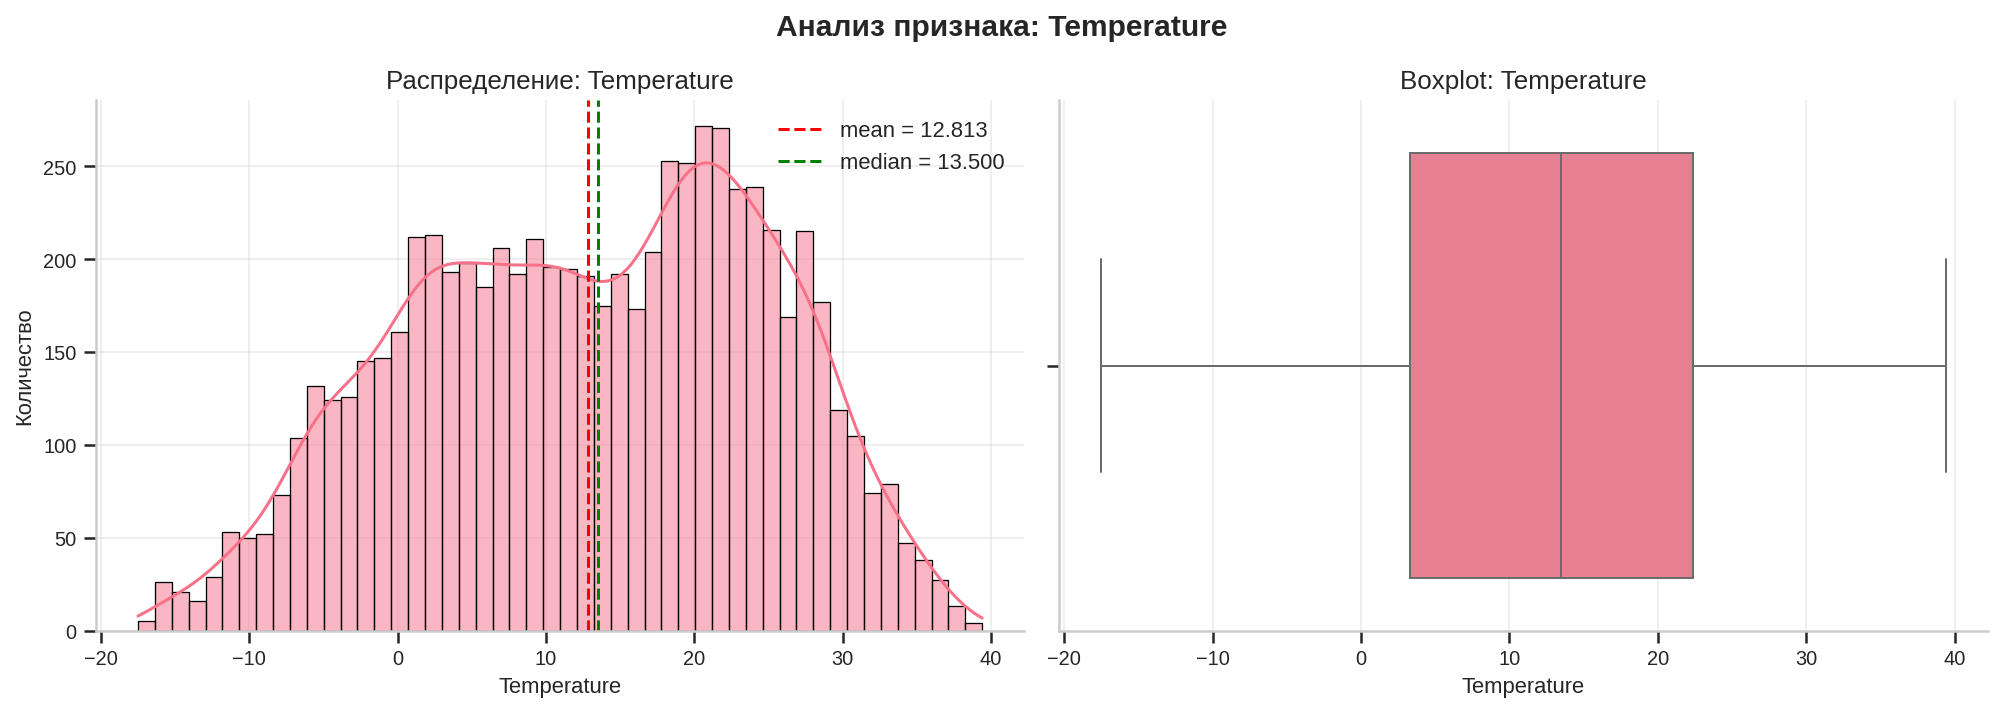

FEATURE ANALYSIS: Humidity(%)

Stats for 'Humidity(%)':


,count,mean,std,min,25%,50%,75%,max
Humidity(%),6758.0000,58.2005,20.3403,0.0000,42.0000,57.0000,74.0000,98.0000



Additional stats:
  IQR: 32.0000
  Outlier bounds: [-6.0000, 122.0000]
  Outliers: 0 (0.00%)
  Skewness: 0.0520
  Kurtosis: -0.7814


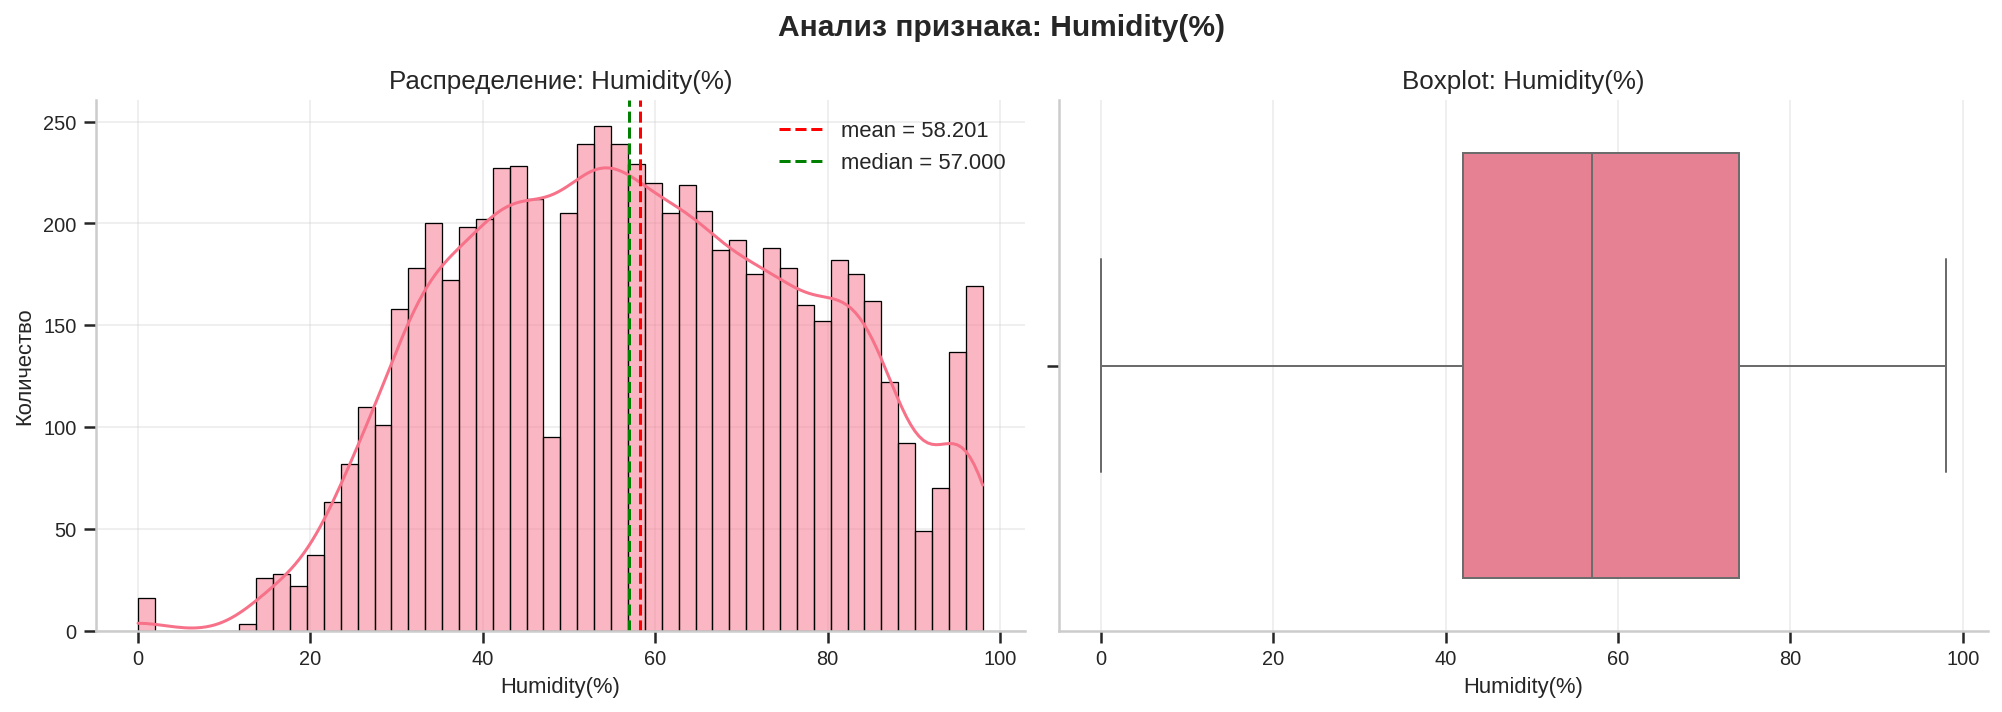

FEATURE ANALYSIS: Wind speed (m/s)

Stats for 'Wind speed (m/s)':


,count,mean,std,min,25%,50%,75%,max
Wind speed (m/s),6798.0000,1.7252,1.0430,0.0000,0.9000,1.5000,2.3000,7.4000



Additional stats:
  IQR: 1.4000
  Outlier bounds: [-1.2000, 4.4000]
  Outliers: 127 (1.81%)
  Skewness: 0.8958
  Kurtosis: 0.7369


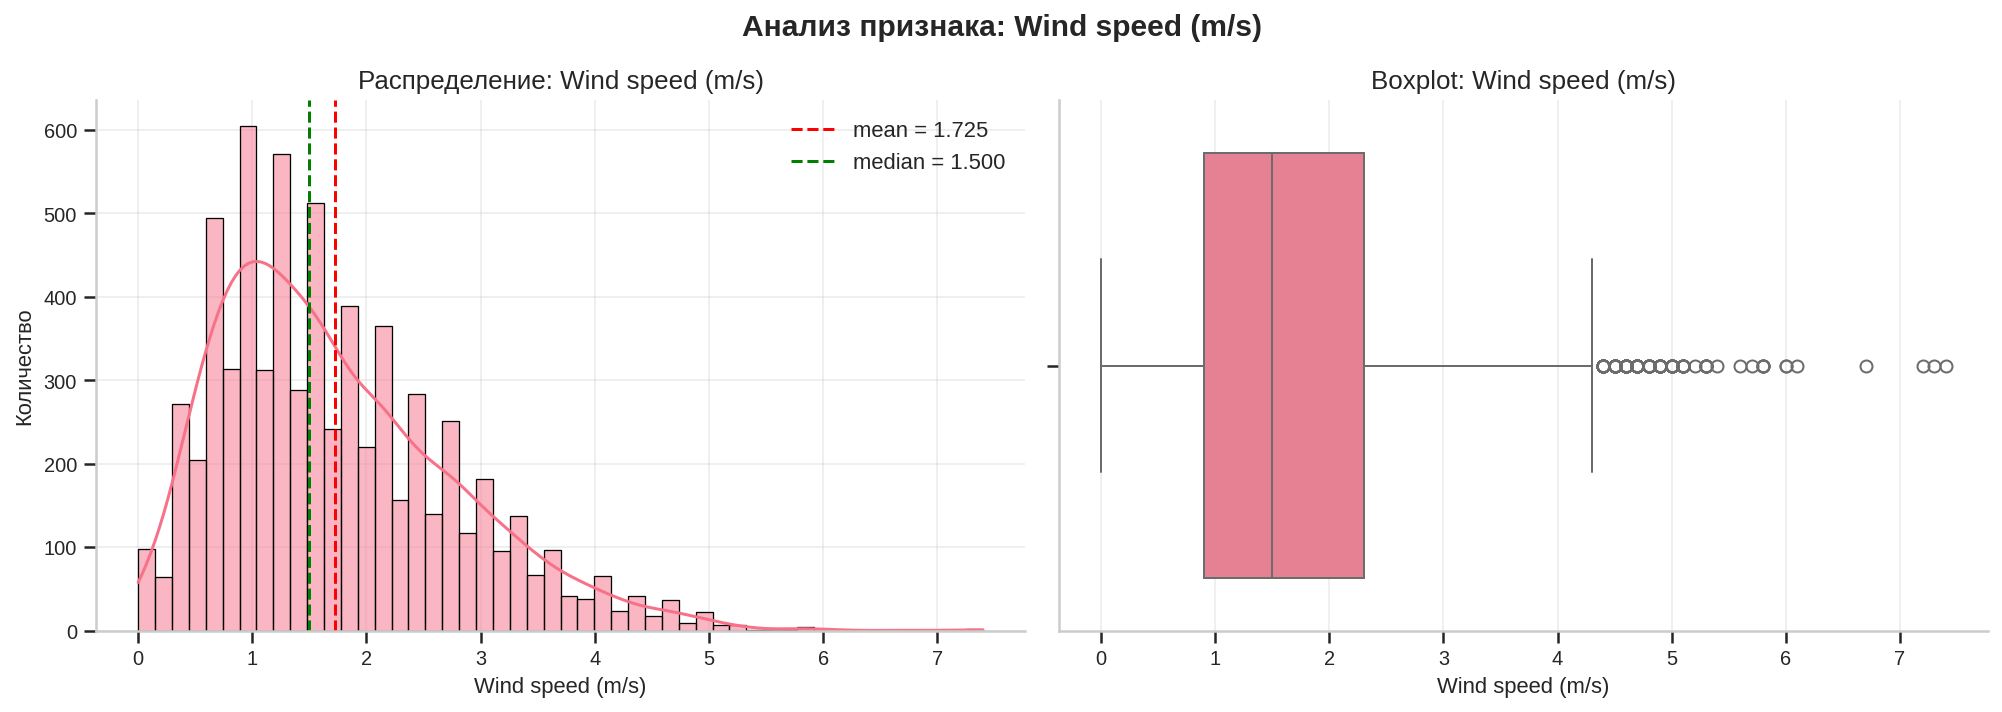

FEATURE ANALYSIS: Visibility (10m)

Stats for 'Visibility (10m)':


,count,mean,std,min,25%,50%,75%,max
Visibility (10m),6749.0000,1435.1568,607.2910,27.0000,936.0000,1691.0000,2000.0000,2000.0000



Additional stats:
  IQR: 1064.0000
  Outlier bounds: [-660.0000, 3596.0000]
  Outliers: 0 (0.00%)
  Skewness: -0.6955
  Kurtosis: -0.9692


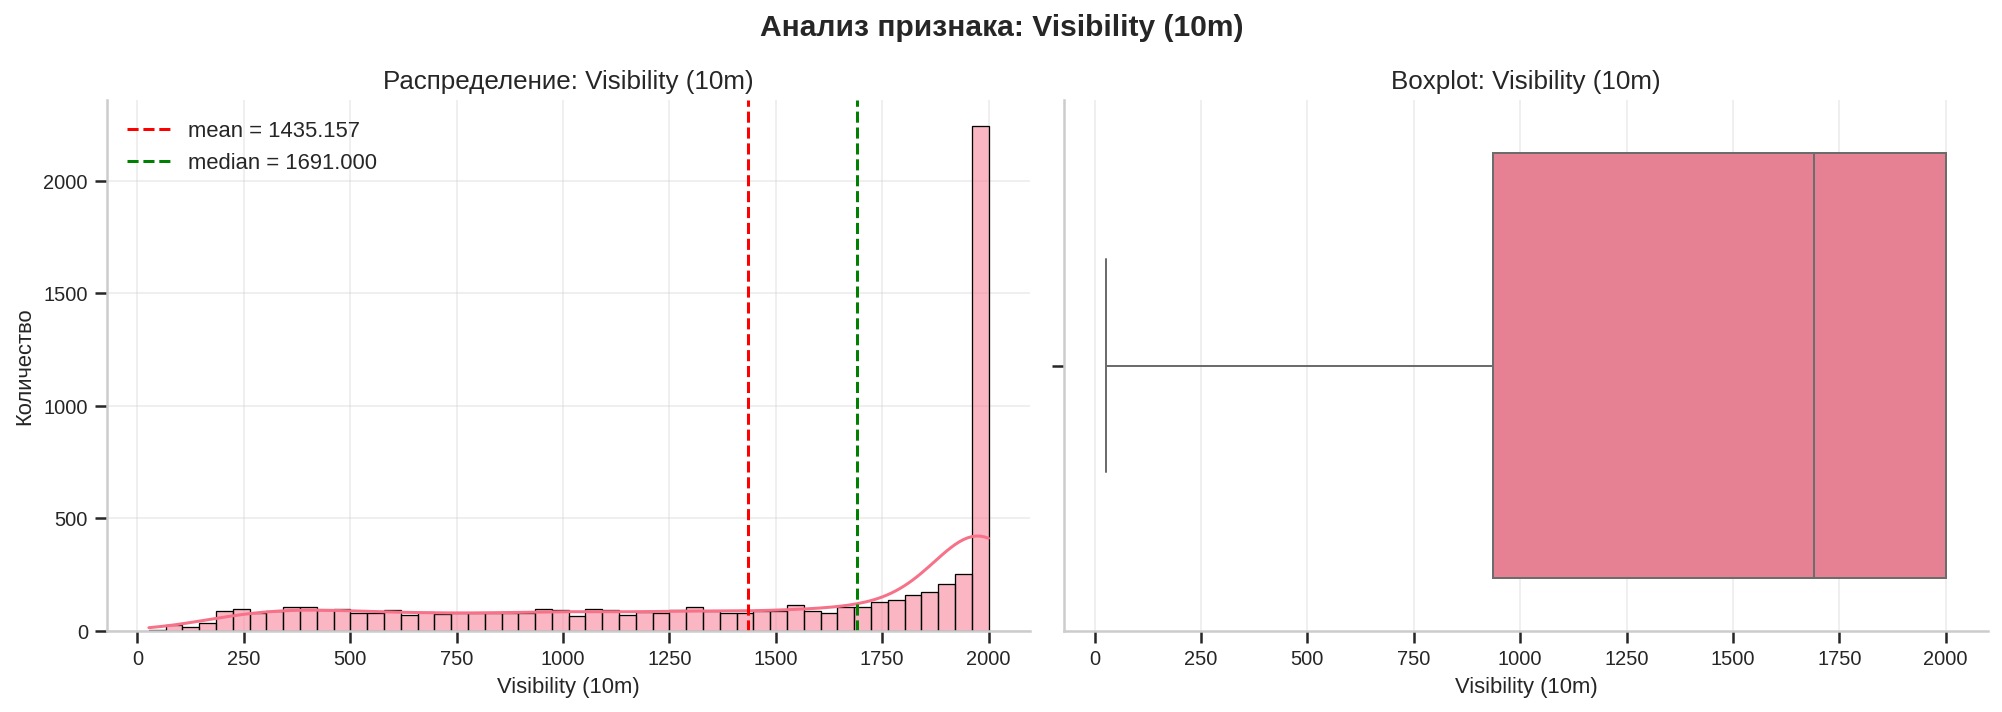

FEATURE ANALYSIS: Dew point temperature

Stats for 'Dew point temperature':


,count,mean,std,min,25%,50%,75%,max
Dew point temperature,7008.0000,4.0215,13.0334,-30.6000,-4.7000,5.0000,14.8000,26.8000



Additional stats:
  IQR: 19.5000
  Outlier bounds: [-33.9500, 44.0500]
  Outliers: 0 (0.00%)
  Skewness: -0.3581
  Kurtosis: -0.7522


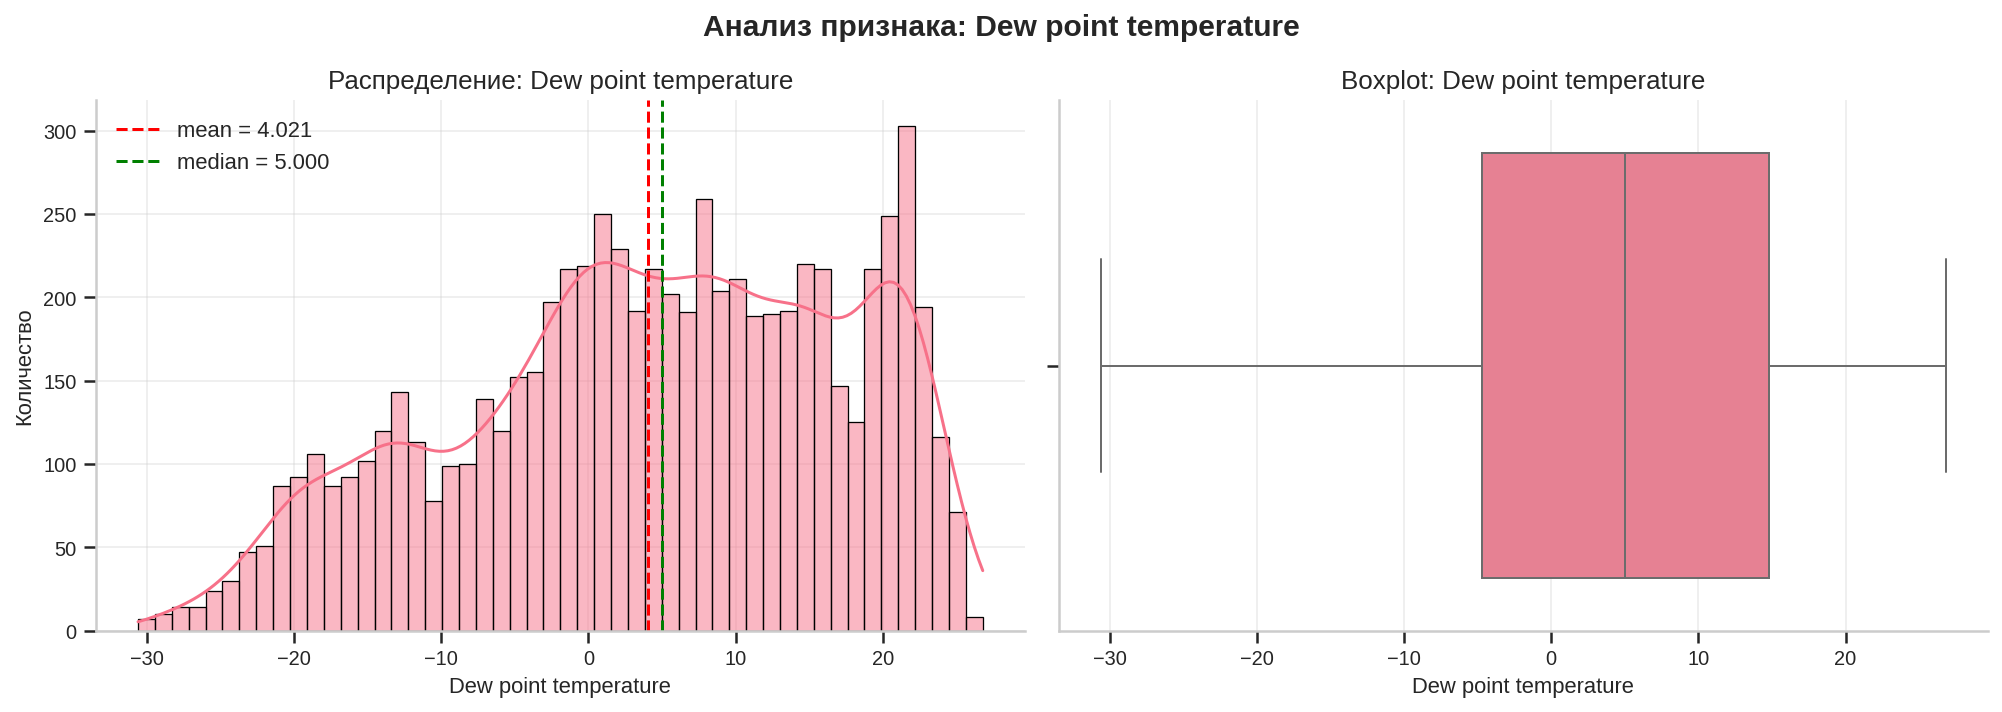

FEATURE ANALYSIS: Solar Radiation (MJ/m2)

Stats for 'Solar Radiation (MJ/m2)':


,count,mean,std,min,25%,50%,75%,max
Solar Radiation (MJ/m2),6798.0000,0.5699,0.8661,0.0000,0.0000,0.0100,0.9400,3.5200



Additional stats:
  IQR: 0.9400
  Outlier bounds: [-1.4100, 2.3500]
  Outliers: 473 (6.75%)
  Skewness: 1.4891
  Kurtosis: 1.0815


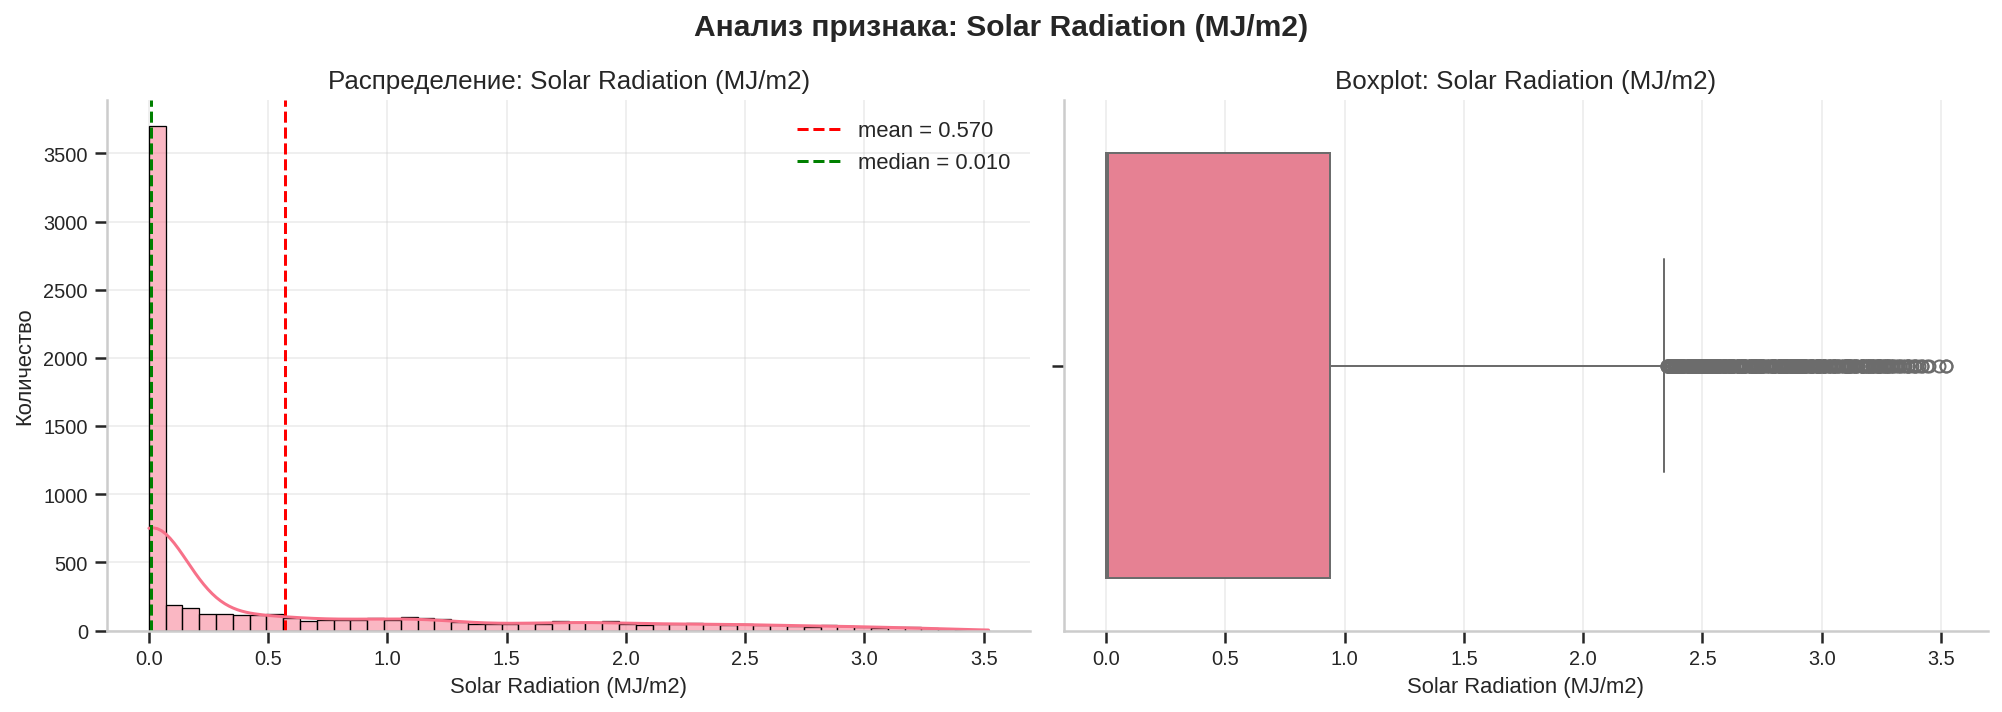

FEATURE ANALYSIS: Rainfall(mm)

Stats for 'Rainfall(mm)':


,count,mean,std,min,25%,50%,75%,max
Rainfall(mm),6746.0000,0.1469,1.1641,0.0000,0.0000,0.0000,0.0000,35.0000



Additional stats:
  IQR: 0.0000
  Outlier bounds: [0.0000, 0.0000]
  Outliers: 385 (5.49%)
  Skewness: 15.2120
  Kurtosis: 305.8539


In [ ]:
# Определяем числовые признаки (кроме целевой)
numeric_cols = train_dt.select_dtypes(include=[np.number]).columns.tolist()
numeric_cols.remove('Rented Bike Count')

for col in numeric_cols:
    print(f"FEATURE ANALYSIS: {col}")
    
    # Статистика
    print(f"\nStats for '{col}':")
    display(train_dt[col].describe().to_frame().T)
    
    # IQR и выбросы
    Q1 = train_dt[col].quantile(0.25)
    Q3 = train_dt[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = train_dt[(train_dt[col] < lower_bound) | (train_dt[col] > upper_bound)]
    
    print(f"\nAdditional stats:")
    print(f"  IQR: {IQR:.4f}")
    print(f"  Outlier bounds: [{lower_bound:.4f}, {upper_bound:.4f}]")
    print(f"  Outliers: {len(outliers)} ({len(outliers)/len(train_dt)*100:.2f}%)")
    print(f"  Skewness: {train_dt[col].skew():.4f}")
    print(f"  Kurtosis: {train_dt[col].kurtosis():.4f}")
    
    # Гистограмма
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Гистограмма
    sns.histplot(train_dt[col].dropna(), bins=50, kde=True, ax=axes[0])
    axes[0].set_title(f'Распределение: {col}')
    axes[0].set_xlabel(col)
    axes[0].set_ylabel('Количество')
    axes[0].axvline(train_dt[col].mean(), color='red', linestyle='--',
                    label=f'mean = {train_dt[col].mean():.3f}')
    axes[0].axvline(train_dt[col].median(), color='green', linestyle='--',
                    label=f'median = {train_dt[col].median():.3f}')
    axes[0].legend()
    
    # Boxplot
    sns.boxplot(x=train_dt[col].dropna(), ax=axes[1])
    axes[1].set_title(f'Boxplot: {col}')
    axes[1].set_xlabel(col)
    
    plt.suptitle(f'Анализ признака: {col}', fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.show()

В результате анализа числовых признаков установлено, что:
1. Temperature (температура): содержит 7008 наблюдений без пропусков, средняя температура - 12.81°C при стандартном отклонении 11.93°C - указывает, что данные охватывают зимние и летние месяцы. Диапозон значений от −17.5°C до +39.4°C. Медиана 13.5°C превышает среднее значение - указывает на незначительную левосторонней асимметрии (skew = −0.19). Эксцесс отрицательный (−0.84) - распределение без выраженных пиков. Выбросов нет.
2. Humidity (относительная влажность): содержит 6758 значений, пропущено 250 наблюдений (3.57%). Средняя влажность 58.20% при стандартном отклонении 20.34%. Минимум равен 0% - скорее всего сбой датчика. Выбросов нет.
3. Wind speed (скорость ветра): содержит 6798 значений, пропущено 210 (3.0%). Средняя скорость ветра 1.73 м/с при стандартном отклонении 1.04 м/с. Медиана 1.5 м/с ниже среднего указывает на правостороннюю асимметрию (skew = 0.90). Эксцесс положительный (0.74) распределение островершинное. Выбросы отражают реальные погодные явления.
4. Visibility (видимость): содержит 6749 значений, пропущено 259 (3.7%). Среднее значение 1435 при стандартном отклонении 607. Медиана 1691 ниже среднего, распределение левосторонне асимметрично (skew = −0.70). Эксцесс  отрицательный (−0.97).
5. Dew point temperature (точка росы): содержит 7008 значений без пропусков. Средняя точка росы  4.02°C при стандартном отклонении 13.03°C. Минимум −30.6°C (очень сухой холодный воздух), максимум +26.8°C (влажный жаркий воздух). Медиана 5.0°C близка к среднему. Распределение слегка левосторонне (skew = −0.36), эксцесс отрицательный (−0.75), почти нормальное.
6. Solar Radiation (солнечная радиация): содержит 6798 значений, пропущено 210 (3.0%). Среднее значение 0.57 при стандартном отклонении 0.87.Медиана 0.01 практически равна нулю половина наблюдений ночь. Распределение сильно правосторонне асимметрично (skew = 1.49) с положительным эксцессом (1.08).
7. Rainfall (осадки): содержит 6746 значений, пропущено 262 (3.74%). Среднее 0.15 мм при стандартном отклонении 1.16 -разброс превышает среднее в 8 раз.  Распределение экстремально асимметрично (skew = 15.21), эксцесс 305.85.
8. Snowfall (снег) содержит 6745 значений, пропущено 263 (3.75%). Среднее 0.07 см при стандартном отклонении 0.44 см. Медиана и квартили равны нулю: 75% значений  без снега. Распределение экстремально асимметрично (skew = 8.60), эксцесс 98.29.
Таким образом, признаки имеют разные масштабы и требуют масштабтрования. Выбросы зафиксированы в скорости ветра, солнечной радиации, осадках и снеге -отражают реальные погодные явления, удалять их нельзя. Многие признаки имеют значительное колличество нулевых значений. Для KNN - масштабирование признаков, для деревьев - обработка пропусков.

Далее посмотрим категориальные признаки

In [ ]:
display(
    train_dt.describe(include=['object']).T
)

Далее проведем анализ целевой переменной.

In [ ]:
TARGET = 'Rented Bike Count'

# Статистика
display(train_dt[TARGET].describe().to_frame().T)

# IQR и выбросы
Q1 = train_dt[TARGET].quantile(0.25)
Q3 = train_dt[TARGET].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = train_dt[(train_dt[TARGET] < lower_bound) | (train_dt[TARGET] > upper_bound)]

print(f"\nAdditional stats:")
print(f"  IQR: {IQR:.4f}")
print(f"  Outlier bounds: [{lower_bound:.4f}, {upper_bound:.4f}]")
print(f"  Outliers: {len(outliers)} ({len(outliers)/len(train_dt)*100:.2f}%)")
print(f"  Skewness: {train_dt[TARGET].skew():.4f}")
print(f"  Kurtosis: {train_dt[TARGET].kurtosis():.4f}")

# Графики
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram + KDE
sns.histplot(train_dt[TARGET], bins=50, kde=True, ax=axes[0])
axes[0].set_title('Распределение целевой переменной')
axes[0].set_xlabel('Количество арендованных велосипедов')
axes[0].set_ylabel('Количество наблюдений')
axes[0].axvline(train_dt[TARGET].mean(), color='red', linestyle='--',
                label=f'mean = {train_dt[TARGET].mean():.3f}')
axes[0].axvline(train_dt[TARGET].median(), color='green', linestyle='--',
                label=f'median = {train_dt[TARGET].median():.3f}')
axes[0].legend()

# Boxplot
sns.boxplot(x=train_dt[TARGET], ax=axes[1])
axes[1].set_title(f'Boxplot: {TARGET}')
axes[1].set_xlabel('Количество арендованных велосипедов')

plt.suptitle('Анализ целевой переменной', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

Установлено, что целевая переменная содержит 7008 наблюдений без пропусков. Средний спрос 705.6 велосипедов в час, медиана 504.5, стандартное отклонение 646.3. Распределение имеет выраженную правостороннюю асимметрию (skew = 1.16) и положительный эксцесс (0.87). Зафиксировано 121 наблюдение (1.73%) выше верхней границы IQR (2388.9). Распределение не является нормальным.
Далее посмотрим есть ли сильные сезонные колебания. Построим графики зависимости спроса от температуры, осадков, солнечной радиации. Сравним спрос в разные сезоны и праздничные дни.

In [ ]:
# Статистика
season_stats = train_dt.groupby('Seasons')['Rented Bike Count'].agg(
    count='count',
    mean='mean',
    median='median',
    std='std',
    min='min',
    q1=lambda x: x.quantile(0.25),
    q3=lambda x: x.quantile(0.75),
    max='max'
).round(2)

season_order = ['Winter', 'Spring', 'Summer', 'Autumn']
season_stats = season_stats.reindex(season_order)
display(season_stats)

season_colors = ['skyblue', 'mediumseagreen', 'gold', 'coral']

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Столбиковая — средний спрос
means = season_stats['mean'].reindex(season_order)
bars = axes[0].bar(means.index, means.values,
                   color=season_colors, edgecolor='black')
for bar, val in zip(bars, means.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, val + 20,
                 f'{val:.0f}', ha='center', fontweight='bold')
axes[0].set_title('Средний спрос по сезонам')
axes[0].set_xlabel('Сезон')
axes[0].set_ylabel('Среднее количество арендованных велосипедов')

# Boxplot — распределение
sns.boxplot(
    data=train_dt, x='Seasons', y='Rented Bike Count',
    order=season_order, palette=season_colors, ax=axes[1]
)
axes[1].set_title('Распределение спроса по сезонам')
axes[1].set_xlabel('Сезон')
axes[1].set_ylabel('Количество арендованных велосипедов')

plt.suptitle('Влияние сезона на спрос', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

Установлено, что:
- имеется ярко выраженная сезонность спроса на велосипеды. Средний спрос летом (1046 велосипедов в час) почти в 4,6 раза превышает зимний (226). Медиана демонстрирует ту же картину: 923 летом против 204 зимой (разница в 4,5 раза). Выявленная закономерность, не зависит от выбросов.
- распределение по сезонам: лето 1046, осень 821, весна 725, зима 226. 
- стандартное отклонение растёт от зимы (151) к лету (690), что говорит о большей вариативности показателей и менее предсказуемом поведении в тёплый сезон. 
- межквартильный размах летом почти в 5 раз шире, чем зимой составляет 922 и 196 велосипедов, соответсвенно. 
- максимальные значения спроса также приходятся на тёплые сезоны: летом пик достигает 3556 велосипедов в час, весной 3251, осенью 3298. А зимой максимум не превышает 937. Именно летом возникают часы экстремальной нагрузки, когда велосипедов может катастрофически не хватать.
- с точки зрения бизнеса, сезонность является ключевыи фактором для BikeSochi. Компания сталкивается с пятикратным ростом спроса от зимы к лету. Статичное планирование по среднегодовому значению (около 705 велосипедов) приведёт к тому, что зимой половина парка будет простаивать, а летом - не хватать.

Влияние праздничных дней на спрос велосипедов.

In [ ]:
# Статистика
holiday_stats = train_dt.groupby('Holiday')['Rented Bike Count'].agg(
    count='count',
    mean='mean'
).round(2)

holiday_stats['share_%'] = (holiday_stats['count'] / len(train_dt) * 100).round(2)
display(holiday_stats)

holiday_order = ['Holiday', 'No Holiday']
colors = ['orange', 'green']

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Столбиковая
means = holiday_stats['mean'].reindex(holiday_order)
x = np.arange(len(means))

bars = axes[0].bar(x, means.values, 0.5,
                   color=colors, edgecolor='black')

for bar in bars:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2, h + 15,
                 f'{h:.0f}', ha='center', fontsize=11, fontweight='bold')

axes[0].set_xticks(x)
axes[0].set_xticklabels(means.index)
axes[0].set_title('Средний спрос в праздничные и обычные дни',
                  fontsize=13, fontweight='bold')
axes[0].set_ylabel('Количество арендованных велосипедов')
axes[0].grid(alpha=0.3, axis='y')

# Boxplot
sns.boxplot(data=train_dt, x='Holiday', y='Rented Bike Count',
            order=holiday_order, palette=colors,
            ax=axes[1])
axes[1].set_title('Распределение спроса в праздничные и обычные дни',
                  fontsize=13, fontweight='bold')
axes[1].set_xlabel('Тип дня')
axes[1].set_ylabel('Количество арендованных велосипедов')
axes[1].grid(alpha=0.3, axis='y')

plt.suptitle('Влияние праздничных дней на спрос',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

Средний спрос в праздники ниже (494), чем в обычные дни (716), разница составляет около 31%. Boxplot подтверждает картину. В праздничные дни «ящик» смещён вниз и сжат и большинство значений лежит в диапазоне от 100 до 760 велосипедов. В обычные дни разброс шире от 200 до 1076. Максимальные пики в праздники ограничены 2400, тогда как в обычные дни достигают 3556.
Возможные причины: праздники приходятся в основном на холодные месяцы (январь, февраль, март, май). Средний спрос в эти месяцы связан с низкой температурой воздуха. Кроме того, праздники составляют около 5% наблюдений - это ограничивает влияние признака в модели.

посмотрим как влияет время суток и праздничный день

In [ ]:
# функция
def get_time_period(row):
    if row['Time_Period_Night']:        return 'Night'
    if row['Time_Period_Morning']:      return 'Morning'
    if row['Time_Period_Evening']:      return 'Evening'
    if row['Time_Period_Late Evening']: return 'Late Evening'
    return 'Daytime'

# создаём временный датафрейм
temp_df = train_dt.assign(
    time_period=train_dt.apply(get_time_period, axis=1)
)

time_order = ['Night', 'Morning', 'Daytime', 'Evening', 'Late Evening']

pivot_time = temp_df.pivot_table(
    values='Rented Bike Count',
    index='time_period',
    columns='Holiday',
    aggfunc='mean'
).round(1).reindex(time_order)

display(pivot_time)

# Визуализация
pivot_time.plot(kind='bar', figsize=(11, 5),
                color = ['orange', 'green'], edgecolor='black')
plt.title('Распределение спроса в зависимости от времени суток и типа дня',
          fontsize=13, fontweight='bold')
plt.xlabel('Период дня')
plt.ylabel('Среднее количество арендованных велосипедов')
plt.xticks(rotation=15)
plt.legend(title='Тип дня')
plt.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

В будние дни спрос выше почти во все периоды, кроме ночи. Утром высокий в будний день. В выходные утром спрос в 3 раза ниже. Час пик приходится на вечер (1200 в будни, 810 в выходные). Ночью спрос минимален и одинаков, независимо от типа дня.

Далее посмотрим как влияет температура воздуха на спрос. Для этого построим две диаграммы: диаграмму рассеявания (чтобы посмотреть разброс данных) и линейный график. При построении линейного графика используем данные по температуры в виде периодов (с делением в 4 °C ).

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter
axes[0].scatter(train_dt['Temperature'], train_dt['Rented Bike Count'],
                alpha=0.2, s=8, color='skyblue')
axes[0].set_xlabel('Температура, °C')
axes[0].set_ylabel('Количество арендованных велосипедов')
axes[0].set_title('Спрос в зависимости от температуры')

# Средний спрос по интервалам температуры
temp_bins = pd.cut(train_dt['Temperature'], bins=15)
mean_by_temp = train_dt.groupby(temp_bins, observed=True)['Rented Bike Count'].mean()

axes[1].plot(range(len(mean_by_temp)), mean_by_temp.values,
             marker='o', linewidth=2)
axes[1].set_xticks(range(len(mean_by_temp)))
axes[1].set_xticklabels(
    [f'{int(iv.left)}..{int(iv.right)}' for iv in mean_by_temp.index],
    rotation=45, ha='right'
)
axes[1].set_xlabel('Интервал температуры, °C')
axes[1].set_ylabel('Среднее количество арендованных велосипедов')
axes[1].set_title('Средний спрос по интервалам температуры')

plt.tight_layout()
plt.show()

Из графиков видно, что при повышении температуры спрос на велосипеды начинает расти с максимумом от + 24 до + 28 °C и составляет более 1200 велосипедов. В температуру выше 28 °C спрос уменьшается.
В условиях холодной погоды менее 0 °C - наблюдается наименьшие значения спроса на велосипеды. 

Далее посмотрим как влияет относительная влажность на спрос. Посмотрим как влияет дождь на спрос. 

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(train_dt['Rainfall(mm)'], train_dt['Rented Bike Count'],
                alpha=0.2, s=8, color='steelblue')
axes[0].set_xlabel('Количество осадков, мм')
axes[0].set_ylabel('Количество арендованных велосипедов')
axes[0].set_title('Зависимость спроса от количества выпывших осадков', fontsize=13, fontweight='bold')
axes[0].grid(alpha=0.3)

# Средний спрос в погоду (с дождем и без дождя )
rain_flag = train_dt['Rainfall(mm)'] > 0
rain_means = train_dt.groupby(rain_flag)['Rented Bike Count'].mean()
rain_means.index = ['Без дождя', 'С дождем']

bars = axes[1].bar(rain_means.index, rain_means.values,
                   color=['orange', 'green'], edgecolor='black')
for bar, val in zip(bars, rain_means.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 10,
                 f'{val:.0f}', ha='center', fontsize=11, fontweight='bold')
axes[1].set_title('Средний спрос на велосипеды в погоду с дождем и без дождя', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Среднее количество арендованных велосипедов')
axes[1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

Из графике видно, что основной спрос на велосипеды наблюдается при значении осадков равных нулю (в сухую погоду). Чем больше осадков тем меньше спрос. Как только начинается дождь (значения > 0), плотность точек резко падает, а максимальные значения спроса снижаются.
На втором графике наглядно продемонстрировано, что в сухую погоду (без дождя) спрос выше в 4,5 раза, чем в погоду, когда идет дождь со значениями 737 и 165 велосипедов в час. Данный фактор имеет важное значение при прогнозе. Но использовать его лучше как бинарный флаг is_rain (дождь и нет дождя), а не как числовую переменную.

Далее посмотрим как влияет солнечная радиация.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter — оранжевый (семантически подходит к «солнцу»)
axes[0].scatter(train_dt['Solar Radiation (MJ/m2)'], train_dt['Rented Bike Count'],
                alpha=0.2, s=8, color='orange')
axes[0].set_xlabel('Солнечная радиация, MJ/m²')
axes[0].set_ylabel('Количество арендованных велосипедов')
axes[0].set_title('Спрос в зависимости от солнечной радиации')

# Средний спрос по интервалам радиации
sol_bins = pd.cut(train_dt['Solar Radiation (MJ/m2)'], bins=10)
mean_by_sol = train_dt.groupby(sol_bins, observed=True)['Rented Bike Count'].mean()

axes[1].plot(range(len(mean_by_sol)), mean_by_sol.values,
             marker='o', color='darkorange', linewidth=2)
axes[1].set_xticks(range(len(mean_by_sol)))
axes[1].set_xticklabels(
    [f'{iv.left:.2f}..{iv.right:.2f}' for iv in mean_by_sol.index],
    rotation=45, ha='right'
)
axes[1].set_xlabel('Интервал радиации, MJ/m²')
axes[1].set_ylabel('Среднее количество арендованных велосипедов')
axes[1].set_title('Средний спрос по интервалам солнечной радиации')

plt.tight_layout()
plt.show()

Из графика видно, что зависимость спроса от солнечной радиации имеет нелинейный характер, . Как только появляется солнце (радиация больше 0), средний спрос вырастает примерно в 1,7 раза. При высоких значениях радиации разброс спроса больше, чем при нулевых. Это связано с тем, что солнечные часы приходятся на разные сезоны, дни недели и погодные комбинации. Прогноз погоды с бинарным флагом «солнечно или пасмурно» даст больше пользы, чем попытка измерить точное значение интенсивности солнечной радиации. Для модели этот признак значим, но его стоит использовать в комбинации с температурой и временем суток. Можно создать произведение Temperature × is_sunny, чтобы уловить взаимодействие «жарко и солнечно». 

Дополнительные признаки для EDA. Создаем бинарные флаги и смотрим распределение.

In [ ]:
# Создаём бинарные флаги на основе исходных признаков
train_dt['is_rain']  = (train_dt['Rainfall(mm)'] > 0).astype(int)
train_dt['is_snow']  = (train_dt['Snowfall (cm)'] > 0).astype(int)

# Проверка баланса классов
for flag in ['is_rain', 'is_snow']:
    counts = train_dt[flag].value_counts().sort_index()
    print(f"{flag}:")
    print(f"  0 = {counts.get(0, 0)}  ({counts.get(0, 0)/len(train_dt)*100:.1f}%)")
    print(f"  1 = {counts.get(1, 0)}  ({counts.get(1, 0)/len(train_dt)*100:.1f}%)")
    print()

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

flag_info = [
    ('is_rain',  'Дождь',    ['Без дождя', 'Дождь'],    ['mediumseagreen', 'dodgerblue']),
    ('is_snow',  'Снег',     ['Без снега', 'Снег'],     ['mediumseagreen', 'skyblue']),
]

for ax, (flag, title, labels, colors) in zip(axes, flag_info):
    means = train_dt.groupby(flag)['Rented Bike Count'].mean()
    bars = ax.bar(labels, means.values, color=colors, edgecolor='black')
    
    for bar, val in zip(bars, means.values):
        ax.text(bar.get_x() + bar.get_width()/2, val + 15,
                f'{val:.0f}', ha='center', fontweight='bold')
    
    ax.set_title(f'Средний спрос: {title}')
    ax.set_ylabel('Средний Rented Bike Count')

plt.suptitle('Влияние бинарных погодных флагов на спрос',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (flag, title, labels, colors) in zip(axes, flag_info):
    sns.boxplot(data=train_dt, x=flag, y='Rented Bike Count',
                palette=colors, ax=ax,
                flierprops=dict(marker='o', markerfacecolor='red',
                                markersize=4, alpha=0.5))
    ax.set_xticklabels(labels)
    ax.set_title(f'Распределение спроса от {title}', fontsize=13, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Количество арендованных велосипедов')
    ax.grid(alpha=0.3, axis='y')

plt.suptitle('Распределение спроса по бинарным флагам',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

Все три флага демонстрируют пороговый эффект-спрос меняется скачкообразно при переходе от 0 к 1. 
В распределениях при дожде и снеге видны редкие аномально высокие значения. Это может быть связано с кратковременными осадками в пиковые часы.

Сохранение списка непрерывных признаков

In [ ]:
continuous_features = [
    'Temperature',
    'Humidity(%)',
    'Wind speed (m/s)',
    'Visibility (10m)',
    'Dew point temperature',
    'Solar Radiation (MJ/m2)',
    'Rainfall(mm)',
    'Snowfall (cm)'
]

print(f"Непрерывных признаков: {len(continuous_features)}")
print(continuous_features)

Проверка нормальности (непрерывных признаков). Для выбора метода корреляционного анализа.

In [ ]:
normality_results = []

for col in continuous_features:
    data = train_dt[col].dropna()
    
    # D'Agostino's K² тест
    stat, p_value = normaltest(data)
    normal = "Да" if p_value > 0.05 else "Нет"
    
    # Степень отклонения от нормальности
    if p_value > 0.05:
        status = "Распределение нормальное"
    elif p_value > 0.01:
        status = "Небольшое отклонение от нормальности"
    else:
        status = "Распределение отличается от нормального"
    
    normality_results.append({
        'Признак': col,
        'p-value': p_value,
        'Нормальное': normal,
        'Статус': status
    })

# Сводная таблица
normality_df = pd.DataFrame(normality_results)
display(normality_df)

Ожидаемо, распределение отличается от нормального. Используем phik-корреляцию. Метод позволяет оценить числовые и категориальные признаки.

In [ ]:
# PhiK-корреляции с целевой переменной

# Подготовка копии данных
df_phik = train_dt.copy()

# Группы признаков
numeric_features = [
    'Temperature', 'Humidity(%)', 'Wind speed (m/s)',
    'Visibility (10m)', 'Dew point temperature',
    'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)'
]

categorical_features = ['Seasons', 'Holiday', 'Functioning Day']

print(f"Числовых признаков: {len(numeric_features)}")
print(f"Категориальных признаков: {len(categorical_features)}")

# Расчёт PhiK-матрицы
phik_corr = df_phik.phik_matrix(interval_cols=numeric_features + [TARGET])

# Корреляции с целевой переменной
target_corr = phik_corr[[TARGET]].sort_values(by=TARGET, ascending=False)
target_corr = target_corr[target_corr.index != TARGET]

# Таблица с типами признаков
target_table = target_corr.reset_index()
target_table.columns = ['Признак', 'phik-корреляция']

def get_feature_type(feature):
    if feature in numeric_features:
        return 'Числовой'
    return 'Категориальный'

target_table['Тип'] = target_table['Признак'].apply(get_feature_type)

display(target_table.round(3))

# Тепловая карта
plt.figure(figsize=(6, 10))
sns.heatmap(
    target_corr,
    annot=True,
    fmt='.3f',
    cmap='coolwarm',
    center=0,
    cbar_kws={'label': 'PhiK-корреляция'},
    linewidths=1
)
plt.title(f'Корреляция признаков с {TARGET} (PhiK)',
          fontsize=14, fontweight='bold')
plt.xlabel('Целевая переменная', fontsize=12)
plt.ylabel('Признаки', fontsize=12)
plt.tight_layout()
plt.show()

В результате анализа установлено, что:
- наиболее сильная связь обнаружена с признаком Temperature (0.603), что подтверждает его ключевую роль в формировании спроса. 
- высокие значения также получены для категориальных признаков Time_Period_Night (0.509), Seasons (0.491) и Time_Period_Evening (0.490), а также для числовых Dew point temperature (0.464) и Solar Radiation (0.457). Это свидетельствует о выраженном влиянии сезонности, времени суток и температурно-влажностных характеристик на целевую переменную.
- следует отметить, что бинарные признаки is_rain (0.293) и is_snow (0.288). Их корреляция с целевой переменной превышает аналогичные показатели для исходных числовых признаков Rainfall (0.033) и Snowfall (0.117). Это указывает на пороговый характер влияния осадков: сам факт наличия или отсутствия явления оказывается более информативным, чем его количественная мера. Данный результат согласуется с распределениями признаков, имеющими экстремальную асимметрию и большое число нулевых значений.
- умеренная связь наблюдается для Humidity(%) (0.309), Functioning Day (0.288), Visibility (0.241) и Wind speed (0.209). 
- слабые связи зафиксированы для Holiday (0.127), Snowfall (0.117), Time_Period_Morning (0.101) и Rainfall (0.033). Низкие значения для этих признаков не означают их полной бесполезности, однако их индивидуальный вклад в прогноз ограничен. Возможно, они могут проявиться во взаимодействиях с другими переменными.

Таким образом, наибольший прогностический потенциал имеют признаки, характеризующие температуру, сезон, время суток и наличие осадков. Для повышения качества модели рекомендуется использовать бинарные флаги погодных явлений.

In [ ]:
# ПОЛНАЯ PHIK-КОРРЕЛЯЦИОННАЯ МАТРИЦА
# Копия данных для анализа
df_phik = train_dt.copy()

# Группы признаков
numeric_features = continuous_features
categorical_features = ['Seasons', 'Holiday', 'Functioning Day']

binary_features = [
    'Time_Period_Morning', 'Time_Period_Evening',
    'Time_Period_Night', 'Time_Period_Late Evening'
]

# Все признаки для PhiK
interval_cols = numeric_features + [TARGET]

# Расчёт PhiK-матрицы
phik_corr = df_phik.phik_matrix(interval_cols=interval_cols)

print("Полная таблица PhiK-корреляций (все признаки):")
display(phik_corr.round(3))

# Тепловая карта (полная матрица)
plt.figure(figsize=(16, 14))
sns.heatmap(
    phik_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8}
)
plt.title('PhiK-корреляционная матрица (все признаки)',
          fontsize=15, fontweight='bold')
plt.xticks(rotation=90, fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

Анализ полной матрицы выявил несколько сильных межпризнаковых корреляций, которые необходимо учитывать при моделировании.

1. Temperature и Dew point temperature (0.893). Это физически обусловленная связь: точка росы напрямую зависит от температуры и влажности. Для нелинейных моделей, таких как решающее дерево, мультиколлинеарность не критична, однако для kNN она может вносить избыточность при расчёте расстояний. В связи с этим при построении kNN целесообразно рассмотреть исключение одного из этих признаков.

2. Temperature и Seasons (0.814). Сезон strongly коррелирует с температурой, что ожидаемо. При наличии обоих признаков модель может частично дублировать информацию. Для деревьев это не проблема, для kNN - может увеличить размерность без прироста информации.

3. Humidity и is_rain (0.757). Влажность и наличие дождя тесно связаны. Бинарный флаг is_rain частично дублирует информацию о влажности. Это следует учесть при отборе признаков.

4. Snowfall и is_snow (0.741). Аналогичная ситуация: флаг наличия снега почти полностью определяется количеством снега. Однако, как показано выше, для целевой переменной is_snow важнее, чем Snowfall.

5. Time_Period_ между собой (0.31-0.40). Временные периоды логически взаимоисключающие, но PhiK фиксирует умеренную связь из-за того, что все они происходят из одного категориального признака. Это не создаёт проблемы мультиколлинеарности, но подтверждает, что информация о времени суток распределена между несколькими бинарными колонками.

6. Humidity и Visibility (0.587). Высокая влажность часто сопровождается снижением видимости, что объясняет корреляцию.

Необходимо отметить, что даны два датасета train и test, они могут быть не согласованы между собой. нужно это проверить.

Проверяем соотвествует ли выборки тренировочные и тестовые. Проверяем согласованность train и test для этого сравниваем структуру, смотрим пропуски

Загружаем изначальные данные, так как были созданы новые признаки.

In [ ]:
train_raw = pd.read_csv('/datasets/ds_s14_train_data.csv')
test_raw  = pd.read_csv('/datasets/ds_s14_test_data.csv')

# Структура
print('train')
train_dt.info()
display(train_dt.head())

print('test')
test_dt.info()
display(test_dt.head())

print('Train shape:', train_raw.shape)
print('Test shape: ', test_raw.shape)
print('\nКолонки совпадают:', train_raw.columns.equals(test_raw.columns))
print('Типы данных совпадают:', train_raw.dtypes.equals(test_raw.dtypes))

# Пропуски
train_missing = train_raw.isna().mean().mul(100)
test_missing  = test_raw.isna().mean().mul(100)

missing_compare = pd.DataFrame({
    'train_missing_%': train_missing,
    'test_missing_%': test_missing,
    'difference_p.p.': test_missing - train_missing
}).sort_values('difference_p.p.', ascending=False)

display(missing_compare.round(3))

Колонки и типы данных совпадают. Оба датасета имеют 16 признаков. 
Значит, что модель обученную на train сможем применить и к test. 
Пропуски присутствуют в тех же шести числовых признаках. Стратегию заполнения можно применять единообразно к обоим датасетам.

Далее сравниваем количественные и категориальные признаки с визуализацией. Дополнительно проведем статистический тест Колмогорова-Смирнова, так как визуальный анализ и сравнение средних могут не заметить тонких различий в форме распределений. KS-тест статистически проверяет гипотезу о том являются ли датасеты из одного распределения.

In [ ]:
# Количественные признаки
numeric_features = train_raw.select_dtypes(include=[np.number]).columns

train_stats = train_raw[numeric_features].describe().T
test_stats  = test_raw[numeric_features].describe().T

stats_compare = pd.DataFrame({
    'train_mean': train_stats['mean'],
    'test_mean': test_stats['mean'],
    'mean_diff_%': (
        (test_stats['mean'] - train_stats['mean'])
        / train_stats['mean'].replace(0, np.nan) * 100
    ),
    'train_median': train_stats['50%'],
    'test_median': test_stats['50%'],
    'train_std': train_stats['std'],
    'test_std': test_stats['std'],
}).round(2)

display(stats_compare)

# Категориальные признаки
categorical_features = train_raw.select_dtypes(include=['object', 'bool']).columns

for feature in categorical_features:
    train_values = set(train_raw[feature].dropna().unique())
    test_values  = set(test_raw[feature].dropna().unique())
    print(f'{feature}: новых категорий в test — {len(test_values - train_values)}')

# Сравнение долей категорий
    compare_share = pd.DataFrame({
        'train_share_%': train_dt[feature].value_counts(normalize=True).mul(100),
        'test_share_%':  test_dt[feature].value_counts(normalize=True).mul(100)
    }).fillna(0)
    
    compare_share['difference_p.p.'] = (
        compare_share['test_share_%'] - compare_share['train_share_%']
    )
    
    display(compare_share.round(2).sort_values('difference_p.p.', ascending=False))
    
# Статистический тест Колмогорова-Смирнова
print('Статистический тест Колмогорова-Смирнова (train и test)')

ks_results = []
for col in numeric_features:
    stat, p = ks_2samp(train_raw[col].dropna(), test_raw[col].dropna())
    conclusion = 'одинаковое' if p > 0.05 else 'различаются'
    ks_results.append({
        'Признак': col,
        'statistic': round(stat, 3),
        'p-value': round(p, 3),
        'Вывод': conclusion
    })

ks_df = pd.DataFrame(ks_results)
display(ks_df)

# визуализация
features_to_compare = [
    'Rented Bike Count', 'Temperature', 'Humidity(%)',
    'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)'
]

for feature in features_to_compare:
    plt.figure(figsize=(10, 4))
    sns.kdeplot(data=train_raw, x=feature, label='Train', fill=True, alpha=0.3)
    sns.kdeplot(data=test_raw,  x=feature, label='Test',  fill=True, alpha=0.3)
    plt.title(f'Train и Test: {feature}')
    plt.legend()
    plt.show()

В результате анализа датасетов train и test установлено, что:
1. медианы и стандартные отклонения близки. Разница между целевая переменной среднего всего 0,71%. Это значит, что train и test из одного распределения.
2. во всех категориальных и бинарных признаках новых категорий в test нет (0). Это значит, что OneHotEncoder сработает корректно: все категории, которые встретятся в test, уже были в train. Проблем с кодированием не будет
3. статистически подтверждено: train и test взяты из одного распределения. statistic менее 0.05 для всех признаков, что говорит о незначительных различиях.
4.  KDE-кривые накладываются друг на друга для всех рассмотренных признаков, включая целевую переменную Rented Bike Count. Видимых сдвигов нет - формы распределений совпадают.

# Промежуточный вывод. 

Проведённый исследовательский анализ данных показал, что:
1. Датасет содержит 7008 наблюдений и 16 признаков. Пропуски (около 4%) присутствуют в шести числовых метеопараметрах: Humidity, Wind speed, Visibility, Solar Radiation, Rainfall, Snowfall. Полных дубликатов нет; неявные (3 пары) различаются по Visibility - не удаляем, настоящие значения.
2. Целевая переменная Rented Bike Count имеет выраженную правостороннюю асимметрию (skew = 1,16) и положительный эксцесс (0,87). Распределение статистически значимо отличается от нормального, что подтверждено тестом D Agostino-Pearson для всех непрерывных признаков (p < 0,05). Это означает, что линейные модели, предполагающие нормальность остатков, будут давать смещённые прогнозы, особенно в области высоких значений спроса.
3. Корреляционный анализ методом PhiK выявил нелинейный характер зависимостей. Наибольшая сила связи с целевой переменной выявдена для температуры (0,6), времени суток (0,5 для ночи, 0,49 для вечера), сезона (0.49), точки росы (0.46) и солнечной радиации (0.46). Бинарные флаги is_rain, is_snow показали более сильную связь (0,293, 0,288 соответственно), чем их числовые значения. Это подтверждает пороговый характер влияния погодных явлений.
4. Обнаружены сильные межпризнаковые корреляции: 
- Temperature и Dew point temperature (0,89), 
- Temperature и Seasons (0,81).
5. Сезонность выражена: средний спрос летом почти в 5 раз превышает зимний. Суточная зависимость также значима: вечерний (1194) в 4 раза выше ночного (289). Температура демонстрирует нелинейный эффект с максимумом при от +24 до +28 °C, после чего спрос снижается. Дождь снижает спрос в 4,5 раза, а снег в 4 раза, появление солнца повышает спрос в 1,7 раза.
6. С точки зрения компании BikeSochi, полученные результаты имеют прямое практическое значение. Спрос на велосипеды крайне неравномерен и определяется совокупностью погодных, сезонных и временных факторов. Значит, что планирование парка по среднегодовому значению (около 705 велосипедов) неэффективно: зимой значительная часть велосипедов будет простаивать, а летом их будет катастрофически не хватать, особенно в вечерние часы и в солнечные дни.

Рекомендации для дальнейшей работы:
1. Заполнять пропуски будем внутри Pipeline. Для Humidity, Wind speed, Visibility, Rainfall, Snowfall - медиана по сезону; для Solar Radiation - медиана по сезону и времени суток.
2. Дубликаты удалять не будем.
3. Категориальные признаки такие, как Seasons, Holiday, Functioning Day будем кодировать через OneHotEncoder. С бинарными ничего не будем делать.
4. Для kNN будем масштабировать (RobustScaler), так как признаки имеют разные диапазоны и выбросы. Для дерева решений - не требуется, так как метод не чувствителен к масштабу.
5. Дополнительные признаки is_rain, is_snow -  включаем, так как они имеют хорошуб корреляцию с целевой переменной в отличие от их числовых аналогов.
6. Для kNN можно исключить один из пары признаков Temperature и Dew point temperature.
7. В качестве моделей используем kNN так как хорошо работает, если похожие погодные ситуации дают похожий спрос. Дерево решений полезно благодаря умению работать с условиями вида «если вечер, тепло и нет дождя, спрос высокий». Обе модели будут оптимизированы через Optuna с единой схемой кросс-валидации на 5 фолдах.

## Шаг 2: Разделение данных на тренировочную и валидационную выборки

У вас есть доступ к тренировочной и тестовой выборкам.

Тестовый набор используется для финальной оценки модели после тренировки и подбора гиперпараметров.

Вы тренируетесь на тренировочных данных и оцениваете качество через валидацию.



У нас есть два готовых датасета: train (7008 строк) и test (1752 строки). Тестовую выборку нельзя использовать ни для обучения, ни для подбора гиперпараметров иначе оценка качества будет нечестной 
Поэтому train делим на две части. 


Так как в дальнейшем будем заполнять пропуски, масштабировать и кодировать признаки - эти операции меняют данные, поэтому нужна безопасная копия - создадим ее.
Затем отделим целевую переменную: X - признаки, y - спрос.
После этого разделим train на обучающую (80%) и валидационную (20%) части. Валидация нужна для честной промежуточной оценки модели.
Проверим, что колонки в X_train и X_valid совпадают, а распределение целевой переменной в train и valid будет близким. 

In [ ]:
# Создаём рабочую копию
model_data = train_dt.copy()

print(f'Размер рабочего датасета: {model_data.shape}')
print(f'Размер исходного train_dt: {train_dt.shape}')

# Отделяем целевую переменную
TARGET = 'Rented Bike Count'

X = model_data.drop(columns=[TARGET])
y = model_data[TARGET]

print(f'\nX: {X.shape} | y: {y.shape}')

# Разделяем train на обучающую и валидационную выборки
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE
)

print(f'\nX_train: {X_train.shape} | y_train: {y_train.shape}')
print(f'X_valid: {X_valid.shape} | y_valid: {y_valid.shape}')
print(f'\nКолонки X_train и X_valid совпадают: '
      f'{X_train.columns.equals(X_valid.columns)}')

comparison = pd.DataFrame({
    'train': [y_train.mean(), y_train.median(), y_train.std()],
    'valid': [y_valid.mean(), y_valid.median(), y_valid.std()]
}, index=['mean', 'median', 'std']).round(2)
display(comparison)

Проверили, что колонки в X_train и X_valid совпадают. Распределение целевой переменной: среднее 705,1 против 707,6, медиана 503 против 517,5, стандартное отклонение 647,1 против 643,2. Различия минимальны  разбили корректно.

**Шаг 3: Обучение новых моделей**

> Теперь пора «проверить, насколько далеко уедут модели» — KNN и Decision Tree могут уловить нелинейные зависимости, недоступные линейной регрессии.

Что нужно сделать:
1. Подготовьте пайплайн для каждой модели:
    * Предобработка данных.
    * Модель (KNN или Decision Tree).
4. Настройте базовые параметры моделей (например, n_neighbors для KNN, max_depth для дерева).

**Совет:**

Начинайте с базовых параметров, чтобы убедиться, что пайплайн работает. Оптимизацию параметров делаем на следующем шаге.

---



На шаге 3  нужно убедиться, что пайплайны работают корректно и нелинейные модели действительно превосходят линейную. Для этого будем делать:
1. Обрабатывать пропуски - заполняем медианой по сезону (для метеопараметров) и по сезону + времени суток (для Solar Radiation). 
- так как заполнять пропуски в Solar Radiation с учетом времени суток. Time_Period в исходном виде не существует (только 4 бинарных колонки) восстановим этот признак - временно собираем бинарные колонки в одну категориальную колонку Time_Period.
2. Создадим новые признаки.
3. Подготовим несколько вариантов набора признаков
4. Собираем пайплайны для kNN и дерева решений:
- для kNN RobustScaler и OneHotEncoder;
- для дерева только OneHotEncoder (масштабирование не нужно).
5. Обучаем базовые модели с параметрами по умолчанию
6. Оцениваем на кросс-валидации и сравниваем с baseline-линейной регрессией.

In [ ]:
# Признаки для заполнения по сезону
season_fill_features = [
    'Humidity(%)', 'Wind speed (m/s)', 'Visibility (10m)',
    'Rainfall(mm)', 'Snowfall (cm)'
]

# Признак, зависящий от сезона и времени суток
time_sensitive_features = ['Solar Radiation (MJ/m2)']

# Восстанавливаем Time_Period
time_columns = [
    'Time_Period_Evening', 'Time_Period_Late Evening',
    'Time_Period_Morning', 'Time_Period_Night'
]

model_data['Time_Period'] = (
    model_data[time_columns]
    .idxmax(axis=1)
    .str.replace('Time_Period_', '')
)

daytime_mask = model_data[time_columns].sum(axis=1) == 0
model_data.loc[daytime_mask, 'Time_Period'] = 'Daytime'

# Заполняем пропуски
for feature in season_fill_features:
    model_data[feature] = (
        model_data[feature].fillna(
            model_data.groupby('Seasons')[feature].transform('median')
        )
    )

for feature in time_sensitive_features:
    model_data[feature] = (
        model_data[feature].fillna(
            model_data.groupby(['Seasons', 'Time_Period'])[feature].transform('median')
        )
    )

missing_report(model_data)

Создание дополнительных признаков. С учетом корреляции с целевой переменной стоит посмотреть и сохдать дополнительные признаки:
1. Взаимодействие температуры и солнца
2. Категория температуры, так как при анализе обнаружено что спрос зависит от температуры.
3. Плохая погода сочетание дождя, снега или сильного ветра
4. бинарные флаги is_rain, is_snow уже были созданы в EDA.

In [ ]:
# Взаимодействие температуры и солнца
model_data['is_sunny'] = (model_data['Solar Radiation (MJ/m2)'] > 0.35).astype(int)
model_data['temp_sunny'] = model_data['Temperature'] * model_data['is_sunny']

# Категория температуры
def temp_category(t):
    if t < 0:    return 'Freezing'
    if t < 10:   return 'Cold'
    if t < 20:   return 'Mild'
    if t < 28:   return 'Warm'
    return 'Hot'

model_data['temp_category'] = model_data['Temperature'].apply(temp_category)

# Плохая погода: дождь, снег или сильный ветер
model_data['is_bad_weather'] = (
    (model_data['is_rain'] == 1) |
    (model_data['is_snow'] == 1) |
    (model_data['Wind speed (m/s)'] > 4)
).astype(int)

missing_report(model_data)

In [ ]:
model_data.info()

In [ ]:
# Категориальные и бинарные — value_counts
for col in ['temp_category', 'is_bad_weather']:
    print(f'\nРаспределение {col}:')
    display(model_data[col].value_counts().sort_index())

# Числовые — describe
for col in ['temp_sunny']:
    print(f'\nСтатистика {col}:')
    display(model_data[col].describe().to_frame().T.round(2))

In [ ]:
numeric_columns = [
    'Temperature', 'Humidity(%)', 'Wind speed (m/s)',
    'Visibility (10m)', 'Dew point temperature', 'Solar Radiation (MJ/m2)',
    'temp_sunny'
]

categorical_columns = [
    'Seasons', 'Holiday', 'Functioning Day',
    'temp_category'
]

binary_columns = [
    'Time_Period_Morning', 'Time_Period_Evening',
    'Time_Period_Night', 'Time_Period_Late Evening',
    'is_rain', 'is_snow', 'is_sunny',
    'is_bad_weather'
]

In [ ]:
# Корреляция новых признаков с целевой переменной
# Список новых признаков
new_features = [
    'temp_sunny', 'temp_category', 'is_bad_weather', 'is_sunny'
]

# Числовые и бинарные через PhiK
df_phik_new = model_data.copy()

# Для PhiK: interval_cols - непрерывные признаки + целевая
interval_cols_new = [
    'Temperature', 'Humidity(%)', 'Wind speed (m/s)',
    'Visibility (10m)', 'Dew point temperature',
    'Solar Radiation (MJ/m2)', 'temp_sunny',
    TARGET
]

phik_corr_new = df_phik_new.phik_matrix(interval_cols=interval_cols_new)

# Связь новых признаков с целевой
new_features_corr = (
    phik_corr_new[[TARGET]]
    .loc[new_features]
    .sort_values(by=TARGET, ascending=False)
    .round(3)
)

print('PhiK-корреляция новых признаков с целевой:')
display(new_features_corr)

# Тепловая карта
plt.figure(figsize=(4, 5))
sns.heatmap(
    new_features_corr,
    annot=True,
    fmt='.3f',
    cmap='coolwarm',
    center=0,
    cbar_kws={'label': 'PhiK-корреляция'},
    linewidths=1
)
plt.title('Связь новых признаков с Rented Bike Count')
plt.tight_layout()
plt.show()

В результате анализа учтановлено, что:
- все четыре новых признака (temp_category, temp_sunny, is_sunny, is_bad_weather) статистически значимо коррелируют с целевой переменной Rented Bike Count по методу PhiK.
- признак temp_category показал PhiK = 0.639, что превышает аналогичный показатель для исходной переменной Temperature (0.603). Причина в нелинейной форме зависимости: спрос максимален в диапазоне +24…+28 °C и снижается при более высоких значениях, что категориальное разбиение улавливает, а линейный признак - нет.
- признак temp_sunny 0.567 также показал сильную связь. Его значение ниже, чем у Temperature (0.603), но выше, чем у каждого из его компонентов по отдельности (Solar Radiation (0.457) и is_sunny (0.459)). Это статистически подтверждает эффект взаимодействия: комбинация «высокая температура и солнце» несёт больше информации, чем каждый фактор сам по себе.
- признак is_sunny 0.459, что практически совпадает с Solar Radiation (0.457). Разница в 0.002 статистически незначима, то есть для прогноза достаточно фиксировать сам факт наличия солнца, а не измерять точную интенсивность радиации.
- признак is_bad_weather 0.384, что выше, чем у каждого из трёх его компонентов в отдельности: is_rain (0.293), is_snow (0.288), Wind speed (0.209), что подтверждает, что клиент реагирует на погоду как на целостное состояние, а не на отдельные параметры.
- Rainfall(mm) имеет PhiK = 0.033, что практически означает отсутствие связи с целевой переменной, тогда как is_rain имеет PhiK = 0.293, то есть почти в девять раз выше. Аналогично Snowfall (cm) даёт PhiK = 0.117, а is_snow - 0.288, что в два с половиной раза выше, что доказывает пороговый характер влияния осадков: важен сам факт их наличия, а не количество.

In [ ]:
# Полная PhiK-матрица
phik_corr_full = model_data.phik_matrix(
    interval_cols=[
        'Temperature', 'Humidity(%)', 'Wind speed (m/s)',
        'Visibility (10m)', 'Dew point temperature',
        'Solar Radiation (MJ/m2)', 'temp_sunny', TARGET
    ]
)

# Heatmap
plt.figure(figsize=(16, 14))
sns.heatmap(
    phik_corr_full,
    annot=True, fmt='.2f', cmap='coolwarm', center=0,
    square=True, linewidths=0.5,
    cbar_kws={'shrink': 0.8}
)
plt.title('Полная PhiK-матрица (все признаки)', fontsize=14, fontweight='bold')
plt.xticks(rotation=90, fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

# Таблица сильных пар

phik_pairs = (
    phik_corr_full.where(np.triu(np.ones(phik_corr_full.shape), k=1).astype(bool))
    .stack()
    .reset_index()
)
phik_pairs.columns = ['Признак 1', 'Признак 2', 'PhiK']
phik_pairs = (
    phik_pairs[phik_pairs['PhiK'] > 0.5]
    .sort_values('PhiK', ascending=False)
    .reset_index(drop=True)
)

print('Пары признаков с PhiK > 0.5 (потенциальная избыточность):')
display(phik_pairs.round(3))

Анализ таблицы показывает, что:
1. имеется 26 сильных связей между признаками,
2. самый плотный кластер - производные от температуры:
- Temperature с temp_category (0.997), 
- Temperature с temp_sunny (0.933), 
- temp_category с temp_sunny (0.881), 
- Dew point temperature с temp_category (0.910), 
- Temperature с Dew point temperature (0.893),
- Dew point temperature с temp_sunny (0.711). 
- Все четыре переменные дублируют друг друга через общую ось температуры. Для дерева решений это не критично - выберет самую информативную на каждом шаге. Для kNN это проблема: расстояние между объектами будет учитывать одну и ту же температуру несколько раз. Для kNN оставим один признак из пары Temperature и temp_category и только один из пары Temperature и Dew point temperature.
3. is_bad_weather связан с is_rain на 0.839 и с is_snow на 0.805, потому что он сам построен как их агрегат. Humidity связана с is_rain на 0.745 и с is_bad_weather на 0.546, а Wind speed с is_bad_weather на 0.535. Для kNN можно оставить либо отдельные флаги, либо агрегат, но не всё сразу.
4. Temperature связана с Seasons на 0.814, Dew point temperature с Seasons на 0.800, Seasons с temp_category на 0.691, Seasons с temp_sunny на 0.567, Solar Radiation с Time_Period_Night на 0.565 и Time_Period_Night с temp_sunny на 0.539. Такие связи неизбежны, и удалять признаки не будем, так как сезон и температура, они дополняют друг друга.

Таким образом, для kNN попробуем три варианта набора признаков:
- Основной вариант - убираем Dew point temperature, Rainfall(mm), Snowfall (cm), Time_Period и is_sunny.
- Полный набор, из основного плюс три возвращённых признака: Dew point temperature, Rainfall(mm), Snowfall (cm)
- Разреженный вариант -  убираем Humidity, Wind speed, Visibility, Dew point, Seasons, temp_category. Holiday и Functioning Day, is_snowю

Подготовка основного набора признаков

В основном варианте оставим погодные признаки, но заменим исходные Rainfall(mm) и Snowfall (cm) на созданные уровни осадков.

Вспомогательные признаки Time_Period и is_sunny удалим, потому что информация о времени суток уже есть в бинарных колонках Time_Period_, а is_sunny - нужен был для создания признака temp_sunny 
Удаляем Dew point temperature - сильная связь с температурой.

In [ ]:
TARGET = 'Rented Bike Count'

features_to_remove_main = [
    'Rainfall(mm)',           
    'Snowfall (cm)',          
    'Time_Period',            
    'is_sunny',              
    'Dew point temperature'   
]

model_data_main = model_data.drop(columns=features_to_remove_main).copy()

print('Удалено из основного набора:', features_to_remove_main)
print(f'\nОсновной набор: {model_data_main.shape}')
print('Колонки:')
for col in model_data_main.columns:
    print(f'  {col}')

Полный набор. Нужно вернуть сырые значения из train_dt,  заполним пропуски медианой по сезону. Полный набор будет отличается от основного только тремя дополнительными колонками: Dew point temperature, Rainfall(mm), Snowfall (cm).

In [ ]:
# Полный набор
model_data_full = model_data.copy()

model_data_full['Rainfall(mm)'] = train_dt['Rainfall(mm)'].values
model_data_full['Snowfall (cm)'] = train_dt['Snowfall (cm)'].values

for feat in ['Rainfall(mm)', 'Snowfall (cm)']:
    model_data_full[feat] = model_data_full[feat].fillna(
        model_data_full.groupby('Seasons')[feat].transform('median')
    )

    
if 'Time_Period' in model_data_full.columns:
    model_data_full = model_data_full.drop(columns=['Time_Period'])

if 'is_sunny' in model_data_full.columns:
    model_data_full = model_data_full.drop(columns=['is_sunny'])

print(f'\nПолный набор: {model_data_full.shape}')
print('Колонки:')
for col in model_data_full.columns:
    print(f'  {col}')

missing_report(model_data_full)

Разреженный набор. У kNN есть теоретическая проблема: чем больше признаков, тем менее информативными становятся расстояния между объектами. Если оставить только самые сильные признаки, kNN может работать лучше. Проверим это.

In [ ]:
#Разреженный набор
minimal_keep = [
    'Temperature',              
    'Solar Radiation (MJ/m2)',  
    'temp_sunny',               
    'Seasons',                 
    'temp_category',            
    'Time_Period_Evening',      
    'Time_Period_Night',       
    'is_rain',                  
    'is_bad_weather',           
    TARGET
]

model_data_minimal = model_data[minimal_keep].copy()

print(f'\nРазреженный набор: {model_data_minimal.shape}')
print('Колонки:')
for col in model_data_minimal.columns:
    print(f'  {col}')

In [ ]:
#Основной набор
numeric_main = [
    'Temperature', 'Humidity(%)', 'Wind speed (m/s)',
    'Visibility (10m)', 'Solar Radiation (MJ/m2)', 'temp_sunny'
]
categorical_main = [
    'Seasons', 'Holiday', 'Functioning Day', 'temp_category'
]
binary_main = [
    'Time_Period_Morning', 'Time_Period_Evening',
    'Time_Period_Night', 'Time_Period_Late Evening',
    'is_rain', 'is_snow', 'is_bad_weather'
]

# Полный набор
numeric_full = numeric_main + [
    'Dew point temperature', 'Rainfall(mm)', 'Snowfall (cm)'
]
categorical_full = categorical_main
binary_full = binary_main

# Разреженный набор
numeric_minimal = ['Temperature', 'Solar Radiation (MJ/m2)', 'temp_sunny']
categorical_minimal = ['Seasons', 'temp_category']
binary_minimal = ['Time_Period_Evening', 'Time_Period_Night',
                  'is_rain', 'is_bad_weather']

Препроцессоры. 
Будем использовать:
- ColumnTransformer позволяет применить разные трансформации к разным группам признаков внутри одного объекта. 
- Числовые признаки масштабируем (RobustScaler), потому что они имеют разные диапазоны.
- Категориальные закодируем OneHotEncoder.
- remainder='drop' - все колонки, которые не попали в списки, отбрасываются. Это защита от ошибок  если случайно останется лишний признак, он не попадёт в модель незаметно.

Дереву масштабирование не нужно: оно разбивает пространство по порогам, а не измеряет расстояния. Поэтому в make_tree_preprocessor числовые идут через passthrough.


In [ ]:
def make_knn_preprocessor(numeric, categorical, binary):
    return ColumnTransformer(
        transformers=[
            ('num', RobustScaler(), numeric),
            ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical),
            ('bin', 'passthrough', binary)
        ],
        remainder='drop'
    )

def make_tree_preprocessor(numeric, categorical, binary):
    return ColumnTransformer(
        transformers=[
            ('num', 'passthrough', numeric),  
            ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical),
            ('bin', 'passthrough', binary)
        ],
        remainder='drop'
    )

настройка метрик

In [ ]:
metric_set = {
    'RMSE': 'neg_root_mean_squared_error',
    'MAE': 'neg_mean_absolute_error',
    'R2': 'r2'
}

cv_strategy = KFold(
    n_splits=CV_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

Сборка пайплайнов

In [ ]:
# Пайплайны kNN
knn_pipeline_main = Pipeline([
    ('preprocessor', make_knn_preprocessor(numeric_main, categorical_main, binary_main)),
    ('model', KNeighborsRegressor(n_neighbors=5))
])

knn_pipeline_full = Pipeline([
    ('preprocessor', make_knn_preprocessor(numeric_full, categorical_full, binary_full)),
    ('model', KNeighborsRegressor(n_neighbors=5))
])

knn_pipeline_minimal = Pipeline([
    ('preprocessor', make_knn_preprocessor(numeric_minimal, categorical_minimal, binary_minimal)),
    ('model', KNeighborsRegressor(n_neighbors=5))
])

display(knn_pipeline_main)
display(knn_pipeline_full)
display(knn_pipeline_minimal)

In [ ]:
# Пайплайны дерева
tree_pipeline_main = Pipeline([
    ('preprocessor', make_tree_preprocessor(numeric_main, categorical_main, binary_main)),
    ('model', DecisionTreeRegressor(random_state=RANDOM_STATE))
])

tree_pipeline_full = Pipeline([
    ('preprocessor', make_tree_preprocessor(numeric_full, categorical_full, binary_full)),
    ('model', DecisionTreeRegressor(random_state=RANDOM_STATE))
])

display(tree_pipeline_main)
display(tree_pipeline_full)

Подготовка обучающих выборок. 
Имеется три разных набора признаков (main, full, minimal), и каждый используется со своими моделями. Нужно явно отделить X от y в каждом наборе.

In [ ]:
# Признаки и целевая переменная для основного набора
X_main = model_data_main.drop(columns=[TARGET])
y_main = model_data_main[TARGET]

# Признаки и целевая переменная для полного набора
X_full = model_data_full.drop(columns=[TARGET])
y_full = model_data_full[TARGET]

# Признаки и целевая переменная для разреженного набора
X_minimal = model_data_minimal.drop(columns=[TARGET])
y_minimal = model_data_minimal[TARGET]

# Проверка размеров
print(f'X_main:    {X_main.shape}   | y_main:    {y_main.shape}')
print(f'X_full:    {X_full.shape}   | y_full:    {y_full.shape}')
print(f'X_minimal: {X_minimal.shape} | y_minimal: {y_minimal.shape}')

# Проверка, что порядок колонок совпадает со списками
print('\nКолонки X_main совпадают с признаками:')
print('  numeric:     ', set(numeric_main).issubset(set(X_main.columns)))
print('  categorical: ', set(categorical_main).issubset(set(X_main.columns)))
print('  binary:      ', set(binary_main).issubset(set(X_main.columns)))

Оценка на кросс-валидации.  Кросс-валидация на 5 фолдах даёт устойчивую оценку: модель обучается 5 раз на разных подвыборках, и усредняем метрики. Дополнительно считаем RMSE_std разброс между фолдами. Чем меньше разброс, тем стабильнее модель.

Baseline оцениваем на исходных признаках (X_train), потому что это готовая модель компании, обученная на исходном датасете.

In [ ]:
evaluation_results = []
rmse_distribution = []

def evaluate_model(name, estimator, X, y):
    """Оценивает модель на кросс-валидации и сохраняет метрики."""
    print(f'Оцениваем: {name}')
    cv = cross_validate(
        estimator, X, y,
        cv=cv_strategy,
        scoring=metric_set,
        n_jobs=N_JOBS
    )
    evaluation_results.append({
        'Model': name,
        'RMSE': -cv['test_RMSE'].mean(),
        'RMSE_std': cv['test_RMSE'].std(),
        'MAE': -cv['test_MAE'].mean(),
        'R2': cv['test_R2'].mean()
    })
    for score in cv['test_RMSE']:
        rmse_distribution.append({'Model': name, 'RMSE': -score})

In [ ]:
# Baseline — на исходных признаках, свой пайплайн сам всё заполнит
evaluate_model('Baseline Linear', baseline_pipeline, X_train, y_train)

# kNN — три варианта
evaluate_model('kNN (main)',    knn_pipeline_main,    X_main,    y_main)
evaluate_model('kNN (full)',    knn_pipeline_full,    X_full,    y_full)
evaluate_model('kNN (minimal)', knn_pipeline_minimal, X_minimal, y_minimal)

# Дерево — два варианта
evaluate_model('Tree (main)', tree_pipeline_main, X_main, y_main)
evaluate_model('Tree (full)', tree_pipeline_full, X_full, y_full)

In [ ]:
# Итоговая таблица
baseline_comparison = (
    pd.DataFrame(evaluation_results)
    .sort_values(by='RMSE')
    .reset_index(drop=True)
)
display(baseline_comparison.round(2))

In [ ]:
rmse_cv_data = pd.DataFrame(rmse_distribution)

# Порядок моделей
order = (
    rmse_cv_data.groupby('Model')['RMSE']
    .mean()
    .sort_values()
    .index.tolist()
)

plt.figure(figsize=(12, 6))

# Boxplot разброс по фолдам
sns.boxplot(
    data=rmse_cv_data,
    x='Model', y='RMSE',
    order=order,
    palette='viridis',
    width=0.6
)

sns.stripplot(
    data=rmse_cv_data,
    x='Model', y='RMSE',
    order=order,
    color='black',
    size=7, alpha=0.7, jitter=False
)

baseline_mean = rmse_cv_data.loc[
    rmse_cv_data['Model'] == 'Baseline Linear', 'RMSE'
].mean()

plt.title('Разброс RMSE по фолдам кросс-валидации',
          fontsize=13, fontweight='bold')
plt.xlabel('Модель')
plt.ylabel('RMSE')
plt.xticks(rotation=20, ha='right')
plt.legend()
plt.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

График показывает:
- kNN (main) и kNN (full) самые точные и стабильные, ящики на уровне 330–340, почти неразличимы между собой. 
- Tree (full) и Tree (main) выше, на 385–410, с заметно большим разбросом, особенно Tree (main) с верхним усом до 415. 
- kNN (minimal) - самая нестабильная модель. 
- Baseline - стабильный, но стабильно плохой.

В результате анализа установлено, что: 
- нелинейные модели превосходят линейную регрессию. kNN RMSE 333, а у baseline 413 - улучшение на 19%.
- точные значения Rainfall и Snowfall не нужны, так как бинарные флаги is_rain и is_snow работают не хуже. Dew point temperature для kNN тоже избыточен (PhiK 0,893 с Temperature), его удаление не ухудшило модель.
- kNN (minimal) хуже kNN (main) почти на 80 единиц RMSE - удалять признаки  не будем.
- дерево решений требует оптимизации. Без настройки max_depth и min_samples_leaf оно переобучается и сильно зависит от разбиения.

В шаг 4 берем kNN (main), kNN (full), Tree (main) Tree(full)

#### **Шаг 4: Подбор гиперпараметров с Optuna**

> Компания хочет точную модель. Optuna поможет найти лучшие параметры для KNN и дерева, чтобы снизить ошибки прогноза.

Что нужно сделать:
1. Определите функцию цели для Optuna.

2. Настройте диапазоны гиперпараметров.

3. Запустите оптимизацию и сохраните лучшие параметры.

**Совет:**

Не бойтесь экспериментировать с небольшими диапазонами сначала, а потом расширять, если модель «не уловила» зависимости.

---



Компания хочет точную модель. Optuna поможет найти лучшие гиперпараметры для kNN и дерева, чтобы снизить ошибки прогноза.


Что делаем на этом шаге:
- определяем функцию цели (objective) для Optuna;
- настраиваем диапазоны гиперпараметров;
- отдельно оптимизируем kNN на основном и полном наборе;
- оптимизируем дерево решений;
- сравниваем стабильность оптимизации;
- сохраняем лучшие конфигурации моделей.


Основная метрика по-прежнему RMSE, схема кросс-валидации (KFold(n_splits=5, shuffle=True, random_state=42)).


Оптимизация kNN для основного набора
Начнём с основной версии kNN (knn_pipeline_main). Для подбора будем менять:
- количество соседей (n_neighbors);
- способ взвешивания соседей (weights);
- метрику расстояния (p): 1 — Manhattan, 2 — Euclidean.

In [ ]:
def knn_main_objective(trial):
    """Целевая функция Optuna для kNN на основном наборе."""
    params = {
        'model__n_neighbors': trial.suggest_int('model__n_neighbors', 2, 30),
        'model__weights': trial.suggest_categorical('model__weights', ['uniform', 'distance']),
        'model__p': trial.suggest_int('model__p', 1, 2),
    }
    knn_pipeline_main.set_params(**params)

    cv_scores = cross_val_score(
        knn_pipeline_main, X_main, y_main,
        cv=cv_strategy,
        scoring='neg_root_mean_squared_error',
        n_jobs=N_JOBS
    )
    return -cv_scores.mean()

study_knn_main = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE)
)

study_knn_main.optimize(
    knn_main_objective,
    n_trials=50,
    show_progress_bar=False
)

print('Лучшие параметры kNN (main):')
print(study_knn_main.best_params)
print(f'\nЛучший RMSE: {study_knn_main.best_value:.4f}')

In [55]:
def knn_full_objective(trial):
    """Целевая функция Optuna для kNN на полном наборе."""
    params = {
        'model__n_neighbors': trial.suggest_int('model__n_neighbors', 2, 30),
        'model__weights': trial.suggest_categorical('model__weights', ['uniform', 'distance']),
        'model__p': trial.suggest_int('model__p', 1, 2),
    }
    knn_pipeline_full.set_params(**params)

    cv_scores = cross_val_score(
        knn_pipeline_full, X_full, y_full,
        cv=cv_strategy,
        scoring='neg_root_mean_squared_error',
        n_jobs=N_JOBS
    )
    return -cv_scores.mean()

study_knn_full = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE)
)

study_knn_full.optimize(
    knn_full_objective,
    n_trials=50,
    show_progress_bar=False
)

print('Лучшие параметры kNN (full):')
print(study_knn_full.best_params)
print(f'\nЛучший RMSE: {study_knn_full.best_value:.4f}')

[I 2026-10-10 10:19:07,308] Trial 7 finished with value: 319.81066939016415 and parameters: {'model__n_neighbors': 19, 'model__weights': 'distance', 'model__p': 1}. Best is trial 5 with value: 319.81066939016415.
[I 2026-10-10 10:19:07,751] Trial 8 finished with value: 336.2995948966571 and parameters: {'model__n_neighbors': 3, 'model__weights': 'distance', 'model__p': 2}. Best is trial 5 with value: 319.81066939016415.
[I 2026-10-10 10:19:08,862] Trial 9 finished with value: 315.2062626321386 and parameters: {'model__n_neighbors': 10, 'model__weights': 'distance', 'model__p': 1}. Best is trial 9 with value: 315.2062626321386.
[I 2026-10-10 10:19:09,935] Trial 10 finished with value: 325.9567498936268 and parameters: {'model__n_neighbors': 3, 'model__weights': 'distance', 'model__p': 1}. Best is trial 9 with value: 315.2062626321386.
[I 2026-10-10 10:19:11,040] Trial 11 finished with value: 315.7534255678928 and parameters: {'model__n_neighbors': 12, 'model__weights': 'distance', 'mode

Лучшие параметры kNN (full):
{'model__n_neighbors': 9, 'model__weights': 'distance', 'model__p': 1}

Лучший RMSE: 314.7050


In [56]:
def tree_main_objective(trial):
    """Целевая функция Optuna для дерева на основном наборе."""
    params = {
        'model__max_depth': trial.suggest_int('model__max_depth', 3, 40),
        'model__min_samples_split': trial.suggest_int('model__min_samples_split', 2, 100),
        'model__min_samples_leaf': trial.suggest_int('model__min_samples_leaf', 1, 50),
        'model__max_features': trial.suggest_categorical(
            'model__max_features', [None, 'sqrt', 'log2', 0.3, 0.5, 0.7, 1.0]
        ),
        'model__ccp_alpha': trial.suggest_float('model__ccp_alpha', 0.0, 10.0),
    }
    tree_pipeline_main.set_params(**params)

    cv_scores = cross_val_score(
        tree_pipeline_main, X_main, y_main,
        cv=cv_strategy,
        scoring='neg_root_mean_squared_error',
        n_jobs=N_JOBS
    )
    return -cv_scores.mean()

study_tree_main = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE)
)

study_tree_main.optimize(
    tree_main_objective,
    n_trials=150,
    show_progress_bar=False
)

print('Лучшие параметры дерева (main):')
print(study_tree_main.best_params)
print(f'\nЛучший RMSE: {study_tree_main.best_value:.4f}')

[I 2026-10-10 10:19:48,315] A new study created in memory with name: no-name-9f9b029e-fd15-4f40-bbab-099384fca9ef
[I 2026-10-10 10:19:48,519] Trial 0 finished with value: 364.15144953612474 and parameters: {'model__max_depth': 17, 'model__min_samples_split': 96, 'model__min_samples_leaf': 37, 'model__max_features': 0.5, 'model__ccp_alpha': 0.20584494295802447}. Best is trial 0 with value: 364.15144953612474.
[I 2026-10-10 10:19:48,765] Trial 1 finished with value: 316.4314406402792 and parameters: {'model__max_depth': 39, 'model__min_samples_split': 84, 'model__min_samples_leaf': 11, 'model__max_features': 1.0, 'model__ccp_alpha': 1.3949386065204183}. Best is trial 1 with value: 316.4314406402792.
[I 2026-10-10 10:19:49,012] Trial 2 finished with value: 317.50295177960044 and parameters: {'model__max_depth': 14, 'model__min_samples_split': 38, 'model__min_samples_leaf': 23, 'model__max_features': None, 'model__ccp_alpha': 0.6505159298527952}. Best is trial 1 with value: 316.43144064027

Лучшие параметры дерева (main):
{'model__max_depth': 12, 'model__min_samples_split': 51, 'model__min_samples_leaf': 7, 'model__max_features': 1.0, 'model__ccp_alpha': 0.7993569097679862}

Лучший RMSE: 311.0861


In [57]:
def tree_full_objective(trial):
    """Целевая функция Optuna для дерева на полном наборе."""
    params = {
        'model__max_depth': trial.suggest_int('model__max_depth', 3, 40),
        'model__min_samples_split': trial.suggest_int('model__min_samples_split', 2, 100),
        'model__min_samples_leaf': trial.suggest_int('model__min_samples_leaf', 1, 50),
        'model__max_features': trial.suggest_categorical(
            'model__max_features', [None, 'sqrt', 'log2', 0.3, 0.5, 0.7, 1.0]
        ),
        'model__ccp_alpha': trial.suggest_float('model__ccp_alpha', 0.0, 10.0),
    }
    tree_pipeline_full.set_params(**params)

    cv_scores = cross_val_score(
        tree_pipeline_full, X_full, y_full,
        cv=cv_strategy,
        scoring='neg_root_mean_squared_error',
        n_jobs=N_JOBS
    )
    return -cv_scores.mean()

study_tree_full = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE)
)

study_tree_full.optimize(
    tree_full_objective,
    n_trials=150,
    show_progress_bar=False
)

print('Лучшие параметры дерева (full):')
print(study_tree_full.best_params)
print(f'\nЛучший RMSE: {study_tree_full.best_value:.4f}')

[I 2026-10-10 10:20:28,099] A new study created in memory with name: no-name-40462e3e-f44f-4c31-9153-d3879c937746
[I 2026-10-10 10:20:28,333] Trial 0 finished with value: 367.6822774621889 and parameters: {'model__max_depth': 17, 'model__min_samples_split': 96, 'model__min_samples_leaf': 37, 'model__max_features': 0.5, 'model__ccp_alpha': 0.20584494295802447}. Best is trial 0 with value: 367.6822774621889.
[I 2026-10-10 10:20:28,605] Trial 1 finished with value: 320.11553153439456 and parameters: {'model__max_depth': 39, 'model__min_samples_split': 84, 'model__min_samples_leaf': 11, 'model__max_features': 1.0, 'model__ccp_alpha': 1.3949386065204183}. Best is trial 1 with value: 320.11553153439456.
[I 2026-10-10 10:20:28,870] Trial 2 finished with value: 320.3134211495129 and parameters: {'model__max_depth': 14, 'model__min_samples_split': 38, 'model__min_samples_leaf': 23, 'model__max_features': None, 'model__ccp_alpha': 0.6505159298527952}. Best is trial 1 with value: 320.115531534394

Лучшие параметры дерева (full):
{'model__max_depth': 38, 'model__min_samples_split': 60, 'model__min_samples_leaf': 9, 'model__max_features': 1.0, 'model__ccp_alpha': 0.47934477565806854}

Лучший RMSE: 314.7995


kNN (main):


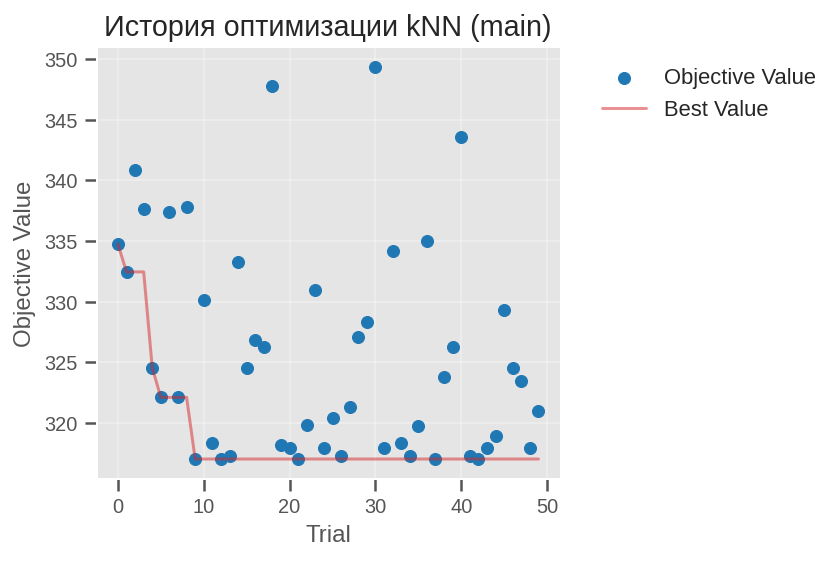

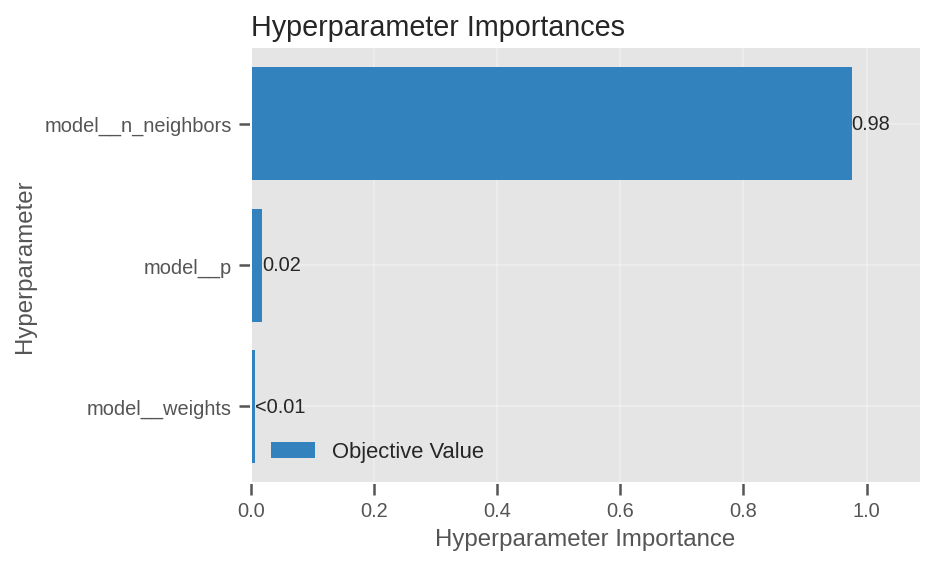

kNN (full):


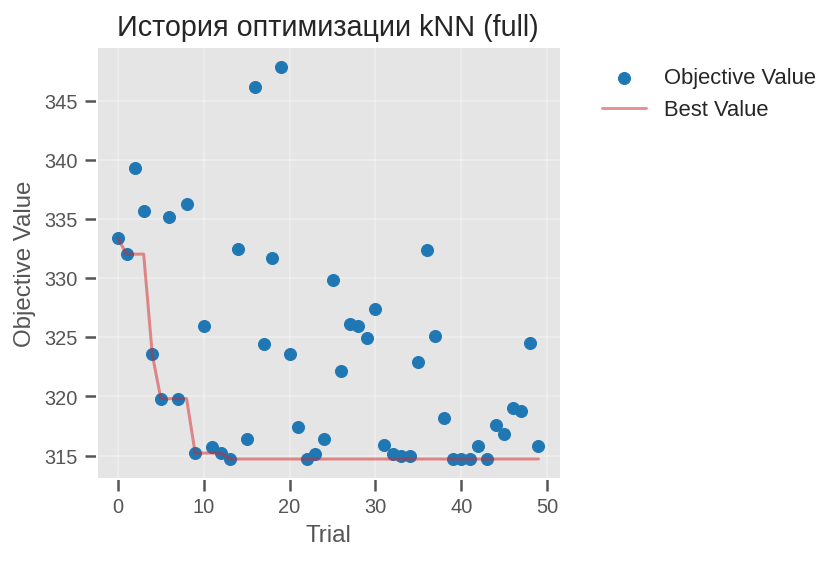

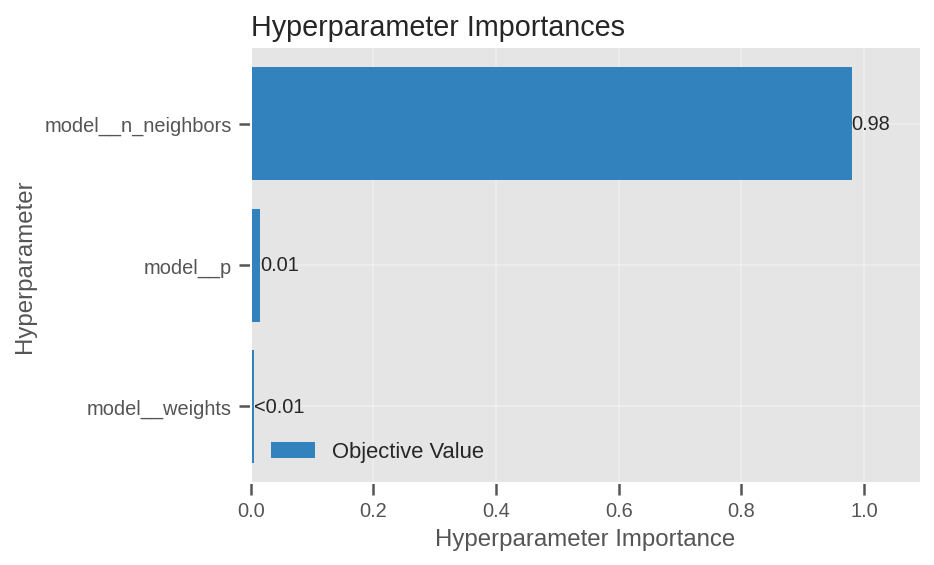

Дерево (main):


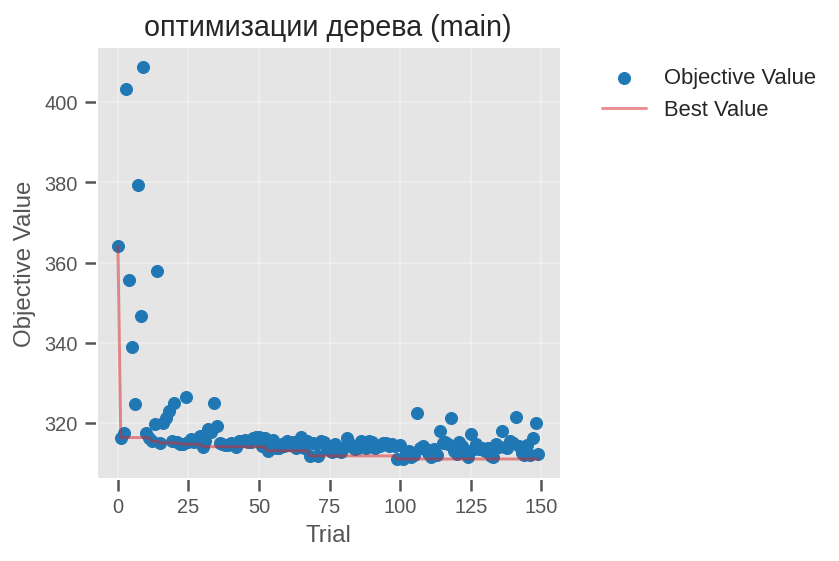

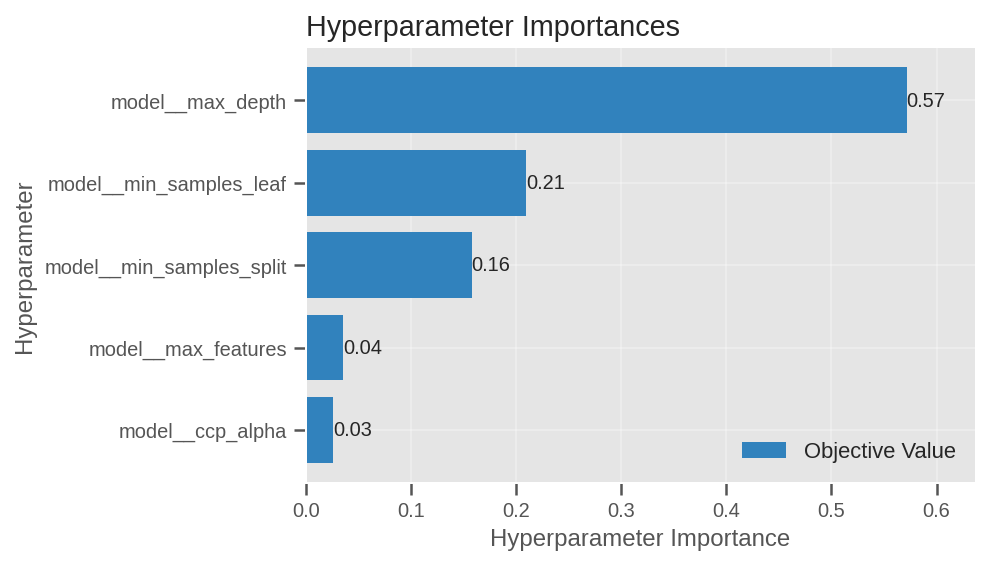

Дерево (full):


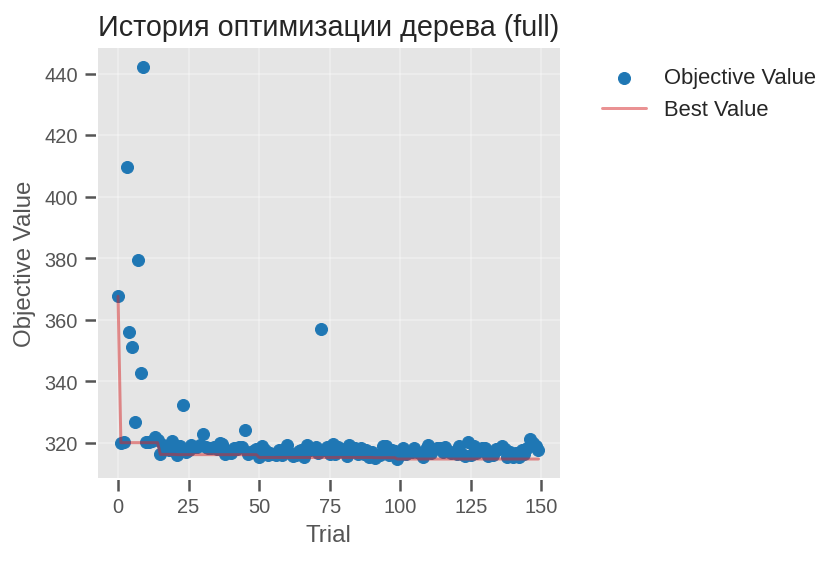

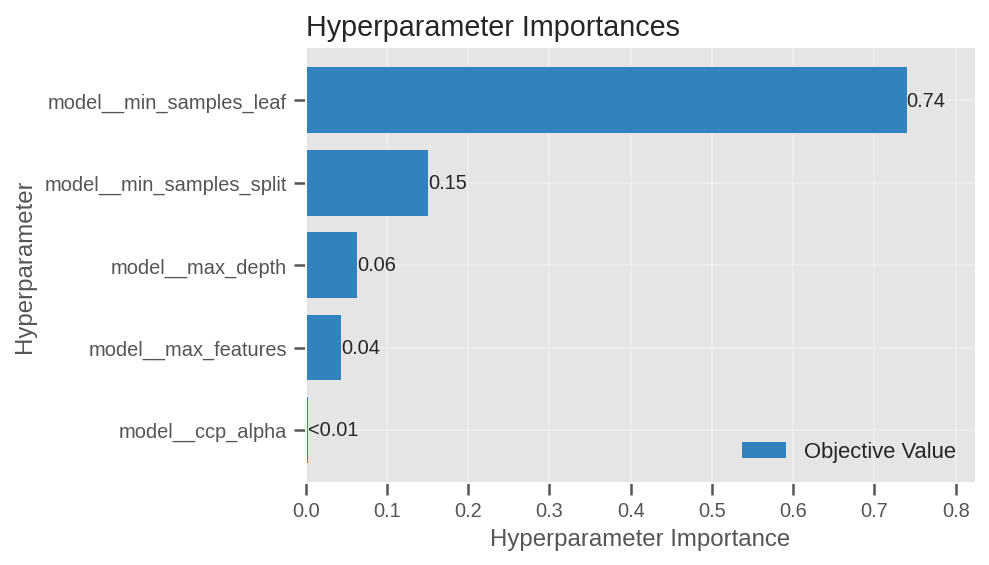

In [58]:
# kNN (main)
print('kNN (main):')
opt_mpl.plot_optimization_history(study_knn_main)
plt.title('История оптимизации kNN (main)')
plt.show()

opt_mpl.plot_param_importances(study_knn_main)
plt.show()

# kNN (full)
print('kNN (full):')
opt_mpl.plot_optimization_history(study_knn_full)
plt.title('История оптимизации kNN (full)')
plt.show()

opt_mpl.plot_param_importances(study_knn_full)
plt.show()

# Дерево (main)
print('Дерево (main):')
opt_mpl.plot_optimization_history(study_tree_main)
plt.title('оптимизации дерева (main)')
plt.show()

opt_mpl.plot_param_importances(study_tree_main)
plt.show()

# Дерево (full)
print('Дерево (full):')
opt_mpl.plot_optimization_history(study_tree_full)
plt.title('История оптимизации дерева (full)')
plt.show()

opt_mpl.plot_param_importances(study_tree_full)
plt.show()

In [59]:
optimized_results = pd.DataFrame({
    'Model': ['kNN (main)', 'kNN (full)', 'Tree (main)', 'Tree (full)'],
    'Best RMSE': [
        study_knn_main.best_value,
        study_knn_full.best_value,
        study_tree_main.best_value,
        study_tree_full.best_value
    ],
    'Best params': [
        study_knn_main.best_params,
        study_knn_full.best_params,
        study_tree_main.best_params,
        study_tree_full.best_params
    ]
}).sort_values(by='Best RMSE').reset_index(drop=True)

display(optimized_results)

,Model,Best RMSE,Best params
0,Tree (main),311.0861,"{'model__max_depth': 12, 'model__min_samples_s..."
1,kNN (full),314.7050,"{'model__n_neighbors': 9, 'model__weights': 'd..."
2,Tree (full),314.7995,"{'model__max_depth': 38, 'model__min_samples_s..."
3,kNN (main),317.0183,"{'model__n_neighbors': 10, 'model__weights': '..."


Tree (main) дал лучший RMSE 311,09 против 314,71 у kNN (full). Причина - переобучение побеждено ограничениями: max_depth=12, min_samples_leaf=7, ccp_alpha=0.80.

Оптимизация дерева дала огромный прирост. Baseline дерева: RMSE 394–400, RMSE_std 11–12. После оптимизации: RMSE 311, и это уже на уровне kNN. Улучшение RMSE на 21% относительно базовой версии.

Оптимизация kNN дала небольшой прирост. kNN (main): 317 (−4.9%). kNN (full): 315 (−5.4%). Ожидаемо - базовые параметры kNN уже были близки к оптимальным.

In [60]:
knn_pipeline_main.set_params(**study_knn_main.best_params)
knn_pipeline_full.set_params(**study_knn_full.best_params)
tree_pipeline_main.set_params(**study_tree_main.best_params)
tree_pipeline_full.set_params(**study_tree_full.best_params)

print('Финальные пайплайны:')
display(knn_pipeline_main)
display(knn_pipeline_full)
display(tree_pipeline_main)
display(tree_pipeline_full)

Финальные пайплайны:


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', RobustScaler(),
                                                  ['Temperature', 'Humidity(%)',
                                                   'Wind speed (m/s)',
                                                   'Visibility (10m)',
                                                   'Solar Radiation (MJ/m2)',
                                                   'temp_sunny']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                sparse_output=False),
                                                  ['Seasons', 'Holiday',
                                                   'Functioning Day',
                                                   'temp_category']),
                                                 ('bin', 'passthrough',
                                                  ['Time_Period_Morning',
                                                   'Time_Period_Evening',
                                                   'Time_Period_Night',
                                                   'Time_Period_Late Evening',
                                                   'is_rain', 'is_snow',
                                                   'is_bad_weather'])])),
                ('model',
                 KNeighborsRegressor(n_neighbors=10, p=1, weights='distance'))])

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', RobustScaler(),
                                                  ['Temperature', 'Humidity(%)',
                                                   'Wind speed (m/s)',
                                                   'Visibility (10m)',
                                                   'Solar Radiation (MJ/m2)',
                                                   'temp_sunny',
                                                   'Dew point temperature',
                                                   'Rainfall(mm)',
                                                   'Snowfall (cm)']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                sparse_output=False),
                                                  ['Seasons', 'Holiday',
                                                   'Functioning Day',
                                                   'temp_category']),
                                                 ('bin', 'passthrough',
                                                  ['Time_Period_Morning',
                                                   'Time_Period_Evening',
                                                   'Time_Period_Night',
                                                   'Time_Period_Late Evening',
                                                   'is_rain', 'is_snow',
                                                   'is_bad_weather'])])),
                ('model',
                 KNeighborsRegressor(n_neighbors=9, p=1, weights='distance'))])

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['Temperature', 'Humidity(%)',
                                                   'Wind speed (m/s)',
                                                   'Visibility (10m)',
                                                   'Solar Radiation (MJ/m2)',
                                                   'temp_sunny']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                sparse_output=False),
                                                  ['Seasons', 'Holiday',
                                                   'Functioning Day',
                                                   'temp_category']),
                                                 ('bin', 'passthrough',
                                                  ['Time_Period_Morning',
                                                   'Time_Period_Evening',
                                                   'Time_Period_Night',
                                                   'Time_Period_Late Evening',
                                                   'is_rain', 'is_snow',
                                                   'is_bad_weather'])])),
                ('model',
                 DecisionTreeRegressor(ccp_alpha=0.7993569097679862,
                                       max_depth=12, max_features=1.0,
                                       min_samples_leaf=7, min_samples_split=51,
                                       random_state=42))])

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['Temperature', 'Humidity(%)',
                                                   'Wind speed (m/s)',
                                                   'Visibility (10m)',
                                                   'Solar Radiation (MJ/m2)',
                                                   'temp_sunny',
                                                   'Dew point temperature',
                                                   'Rainfall(mm)',
                                                   'Snowfall (cm)']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                sparse_output=False),
                                                  ['Seasons', 'Holiday',
                                                   'Functioning Day',
                                                   'temp_category']),
                                                 ('bin', 'passthrough',
                                                  ['Time_Period_Morning',
                                                   'Time_Period_Evening',
                                                   'Time_Period_Night',
                                                   'Time_Period_Late Evening',
                                                   'is_rain', 'is_snow',
                                                   'is_bad_weather'])])),
                ('model',
                 DecisionTreeRegressor(ccp_alpha=0.47934477565806854,
                                       max_depth=38, max_features=1.0,
                                       min_samples_leaf=9, min_samples_split=60,
                                       random_state=42))])

Таким образом, лучшее дерево (main) дало RMSE 311.09, лучший kNN (main) - 314.71.

**Шаг 5: Кросс-валидация новых моделей**

Что нужно сделать:
1. Проведите кросс-валидацию для KNN и Decision Tree с оптимальными гиперпараметрами.
2. Сравните метрики с baseline-моделью.
3. Определите, какая модель показывает лучшие результаты на тренировочной выборке.

**Совет:**

Используйте визуализации (bar plot, box plot), чтобы увидеть разброс метрик и стабильность моделей.


---



Проводим честную кросс-валидацию уже оптимизированных моделей на тех же 5 фолдах, что и baseline. Сравниваем RMSE, MAE, R², а также разброс RMSE между фолдами. Это покажет, какая модель не только точна, но и стабильна.
Создаем списки для хранения результатов. Далее функцию оценки моделей.

In [61]:
cv_summary_results = []
cv_per_fold_scores = []

In [62]:
def evaluate_model_cv(model_name, pipeline, X_data, y_data):
    print(f'Оцениваем модель: {model_name}')

    scoring = {
        'rmse': 'neg_root_mean_squared_error',
        'mae': 'neg_mean_absolute_error',
        'r2': 'r2'
    }

    scores = cross_validate(
        pipeline, X_data, y_data,
        cv=cv_strategy,
        scoring=scoring,
        n_jobs=N_JOBS,
        return_train_score=False
    )

    rmse_scores = -scores['test_rmse']
    mae_scores  = -scores['test_mae']
    r2_scores   =  scores['test_r2']

    cv_summary_results.append({
        'Model': model_name,
        'RMSE': rmse_scores.mean(),
        'RMSE_std': rmse_scores.std(),
        'MAE': mae_scores.mean(),
        'R2': r2_scores.mean()
    })

    for score in rmse_scores:
        cv_per_fold_scores.append({
            'Model': model_name,
            'RMSE': score
        })

In [63]:
# Baseline на исходных признаках
evaluate_model_cv('Baseline Linear', baseline_pipeline, X_train, y_train)

# kNN оптимизированные версии
evaluate_model_cv('kNN (main)', knn_pipeline_main, X_main, y_main)
evaluate_model_cv('kNN (full)', knn_pipeline_full, X_full, y_full)

# Дерево оптимизированные версии
evaluate_model_cv('Tree (main)', tree_pipeline_main, X_main, y_main)
evaluate_model_cv('Tree (full)', tree_pipeline_full, X_full, y_full)

cv_results = (
    pd.DataFrame(cv_summary_results)
    .sort_values(by='RMSE')
    .reset_index(drop=True)
)
display(cv_results.round(2))

cv_folds_df = pd.DataFrame(cv_per_fold_scores)

Оцениваем модель: Baseline Linear
Оцениваем модель: kNN (main)
Оцениваем модель: kNN (full)
Оцениваем модель: Tree (main)
Оцениваем модель: Tree (full)


,Model,RMSE,RMSE_std,MAE,R2
0,Tree (main),311.0900,7.6400,207.3200,0.7700
1,kNN (full),314.7100,5.7800,209.0100,0.7600
2,Tree (full),314.8000,6.4800,210.0900,0.7600
3,kNN (main),317.0200,5.6300,211.0700,0.7600
4,Baseline Linear,413.4100,2.4400,309.7200,0.5900


В результате установлено, что:
- Tree (main) показал лучшие результаты с метриками RMSE 311.09, MAE 207.32, R² 0.77.
- Все нелинейные модели обгоняют baseline на 23–25% по RMSE и на 33% по MAE.
- kNN (main) и kNN (full) неразличимы - можно оставить упрощённый набор.
- Разброс RMSE у нелинейных моделей 5.6–7.6.

Анализ результатов - визуализация. Bar plot по RMSE покажет разрыв между baseline и нелинейными моделями, а Box plot по фолдам - стабильность каждой модели.

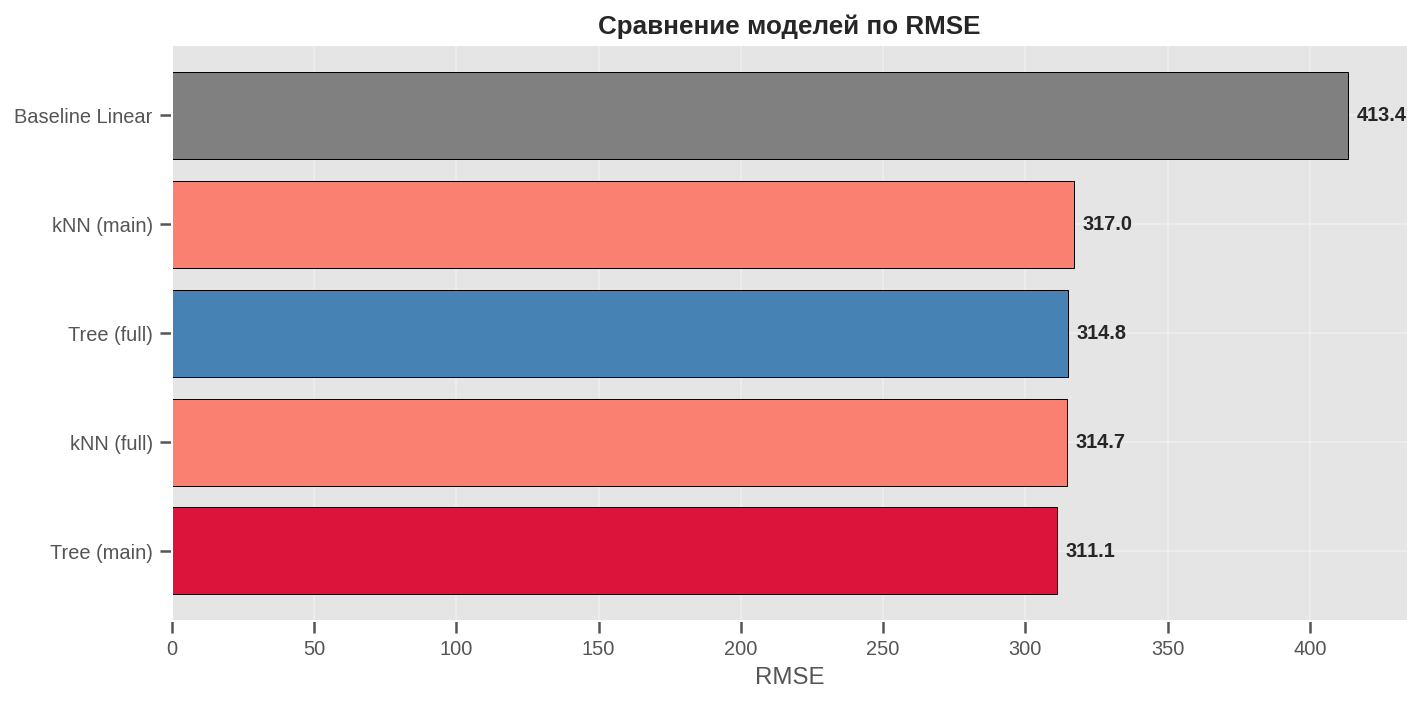

In [64]:
plt.figure(figsize=(10, 5))

colors = [
    'crimson' if 'Tree (main)' in m else
    'steelblue' if 'Tree' in m else
    'salmon' if 'kNN' in m else
    'gray'
    for m in cv_results['Model']
]

bars = plt.barh(cv_results['Model'], cv_results['RMSE'],
                color=colors, edgecolor='black')

for bar, val in zip(bars, cv_results['RMSE']):
    plt.text(val + 3, bar.get_y() + bar.get_height()/2,
             f'{val:.1f}', va='center', fontweight='bold')

plt.xlabel('RMSE')
plt.title('Сравнение моделей по RMSE',
          fontsize=13, fontweight='bold')
plt.legend()
plt.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

Анализ полученных результатов:
1. На диаграмме выделяются две принципиально разные группы моделей. Baseline-модель линейной регрессии демонстрирует RMSE = 413.4, что практически в 1,3 раза превышает показатель любой из нелинейных моделей. Разрыв между baseline и ближайшей к ней нелинейной моделью составляет около 96 единиц RMSE это различие, подтверждающее исходную гипотезу о нелинейной природе зависимости спроса от погодных факторов.
2. Внутри группы нелинейных моделей наблюдается высокая плотность результатов: значения RMSE лежат в диапазоне от 311.1 до 317.0, то есть разброс составляет всего 5.9 единиц т.е. менее 2% от среднего уровня. Это означает, что все четыре модели Tree (main), kNN (full), Tree (full) и kNN (main) статистически сопоставимы по точности.
3. Наилучший результат демонстрирует Tree (main) с RMSE 311.1. Важно отметить, что это дерево решений, оптимизированное с ограничением глубины (max_depth = 12) и с параметром обрезки ccp_alpha = 0,80. Именно эти ограничения позволили дереву превзойти kNN, который на этапе базовых параметров (шаг 3) его существенно опережал.

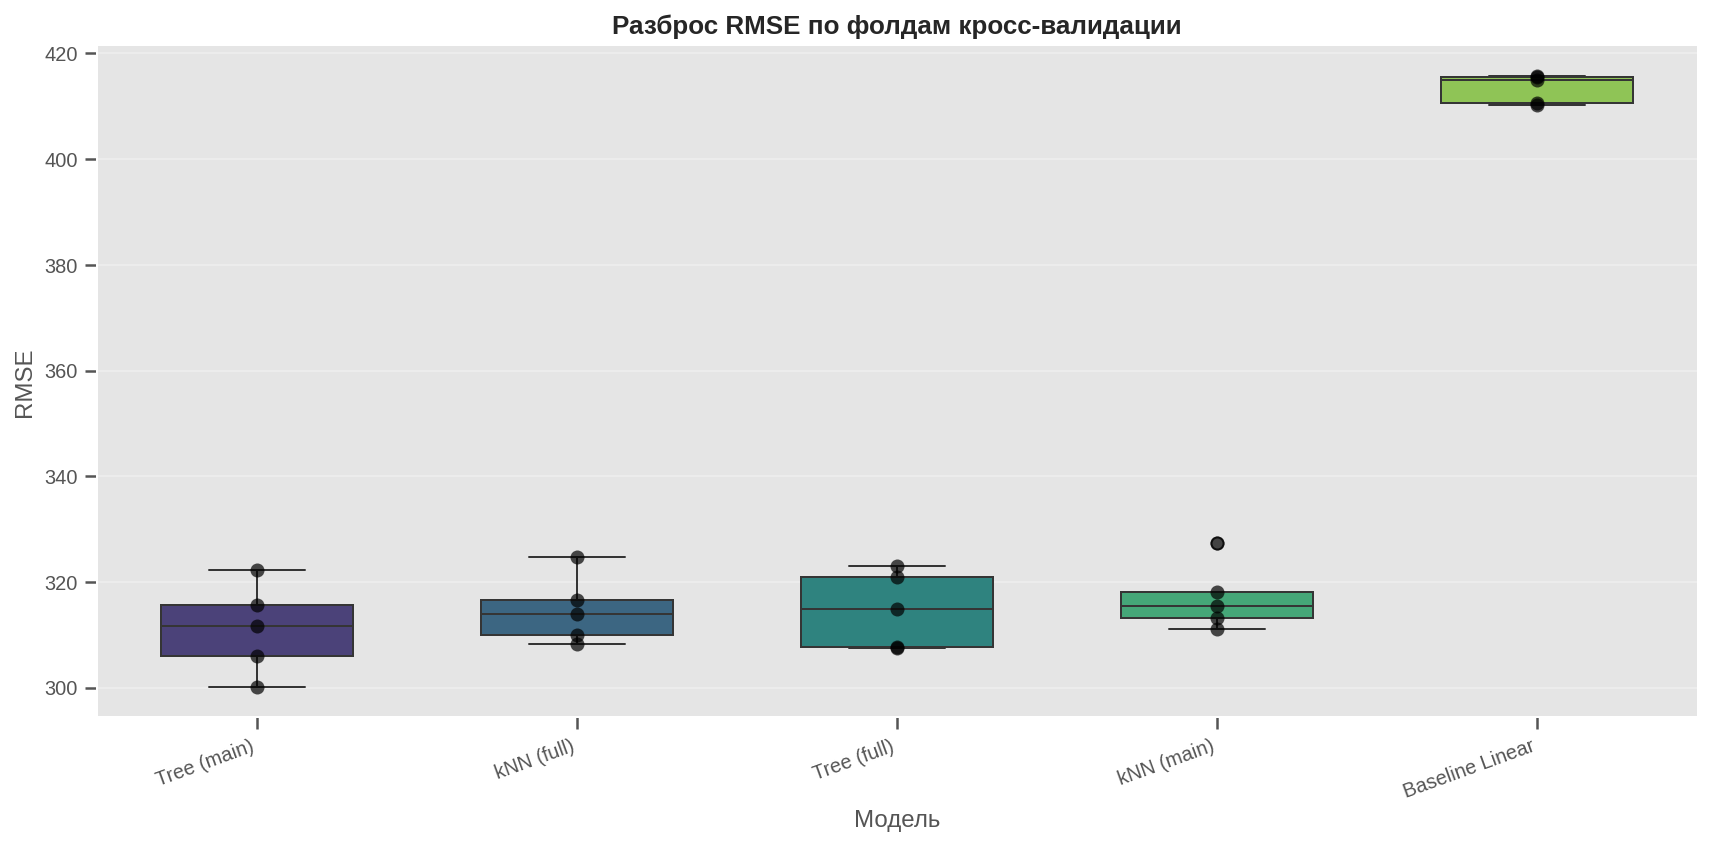

In [65]:
rmse_cv_data = pd.DataFrame(cv_per_fold_scores)

order = (
    rmse_cv_data.groupby('Model')['RMSE']
    .mean().sort_values().index.tolist()
)

plt.figure(figsize=(12, 6))
sns.boxplot(data=rmse_cv_data, x='Model', y='RMSE',
            order=order, palette='viridis', width=0.6)
sns.stripplot(data=rmse_cv_data, x='Model', y='RMSE',
              order=order, color='black', size=7, alpha=0.7, jitter=False)

baseline_mean = rmse_cv_data.loc[
    rmse_cv_data['Model'] == 'Baseline Linear', 'RMSE'
].mean()

plt.title('Разброс RMSE по фолдам кросс-валидации',
          fontsize=13, fontweight='bold')
plt.xlabel('Модель')
plt.ylabel('RMSE')
plt.xticks(rotation=20, ha='right')
plt.legend()
plt.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

Анализ полученных результатов:
1. Диаграмма размаха даёт более полную картину, поскольку показывает не только средний уровень ошибки, но и её вариативность. Baseline демонстрирует наименьший межквартильный размах (IQR) её результаты лежат в узком диапазоне 408–415. С одной стороны, это говорит о высокой устойчивости моделию; с другой эта устойчивость достигается вокруг неудовлетворительного среднего уровня (стабильно неточен).
2. Группа нелинейных моделей демонстрирует более широкие ящики, что отражает повышенную чувствительность. Наиболее узкий ящик в этой группе у kNN (main) и kNN (full). Наиболее широкий  у Tree (main). Это ожидаемо так как алгоритмы, основанные на построении пороговых правил, как правило, более чувствительны к конкретному составу обучающей выборки, чем алгоритмы, усредняющие по соседям.
3. Tree (main) - разрыв по среднему RMSE между ним и kNN (около 6 единиц) сопоставим с шириной самого разброса.
4. Наличие выбросов у kNN (main)  на одном из фолдов RMSE достигает 328, что на 11 единиц выше медианы. У дерева выбросы тоже есть, но они симметричны относительно медианы, что говорит о более равномерном распределении ошибок.

Важность признаков для моделей. Интерпретируемость модели ключевое требование для бизнеса. Дерево и kNN показывают хорошие метрики, но важно понимать почему модель делает тот или иной прогноз.

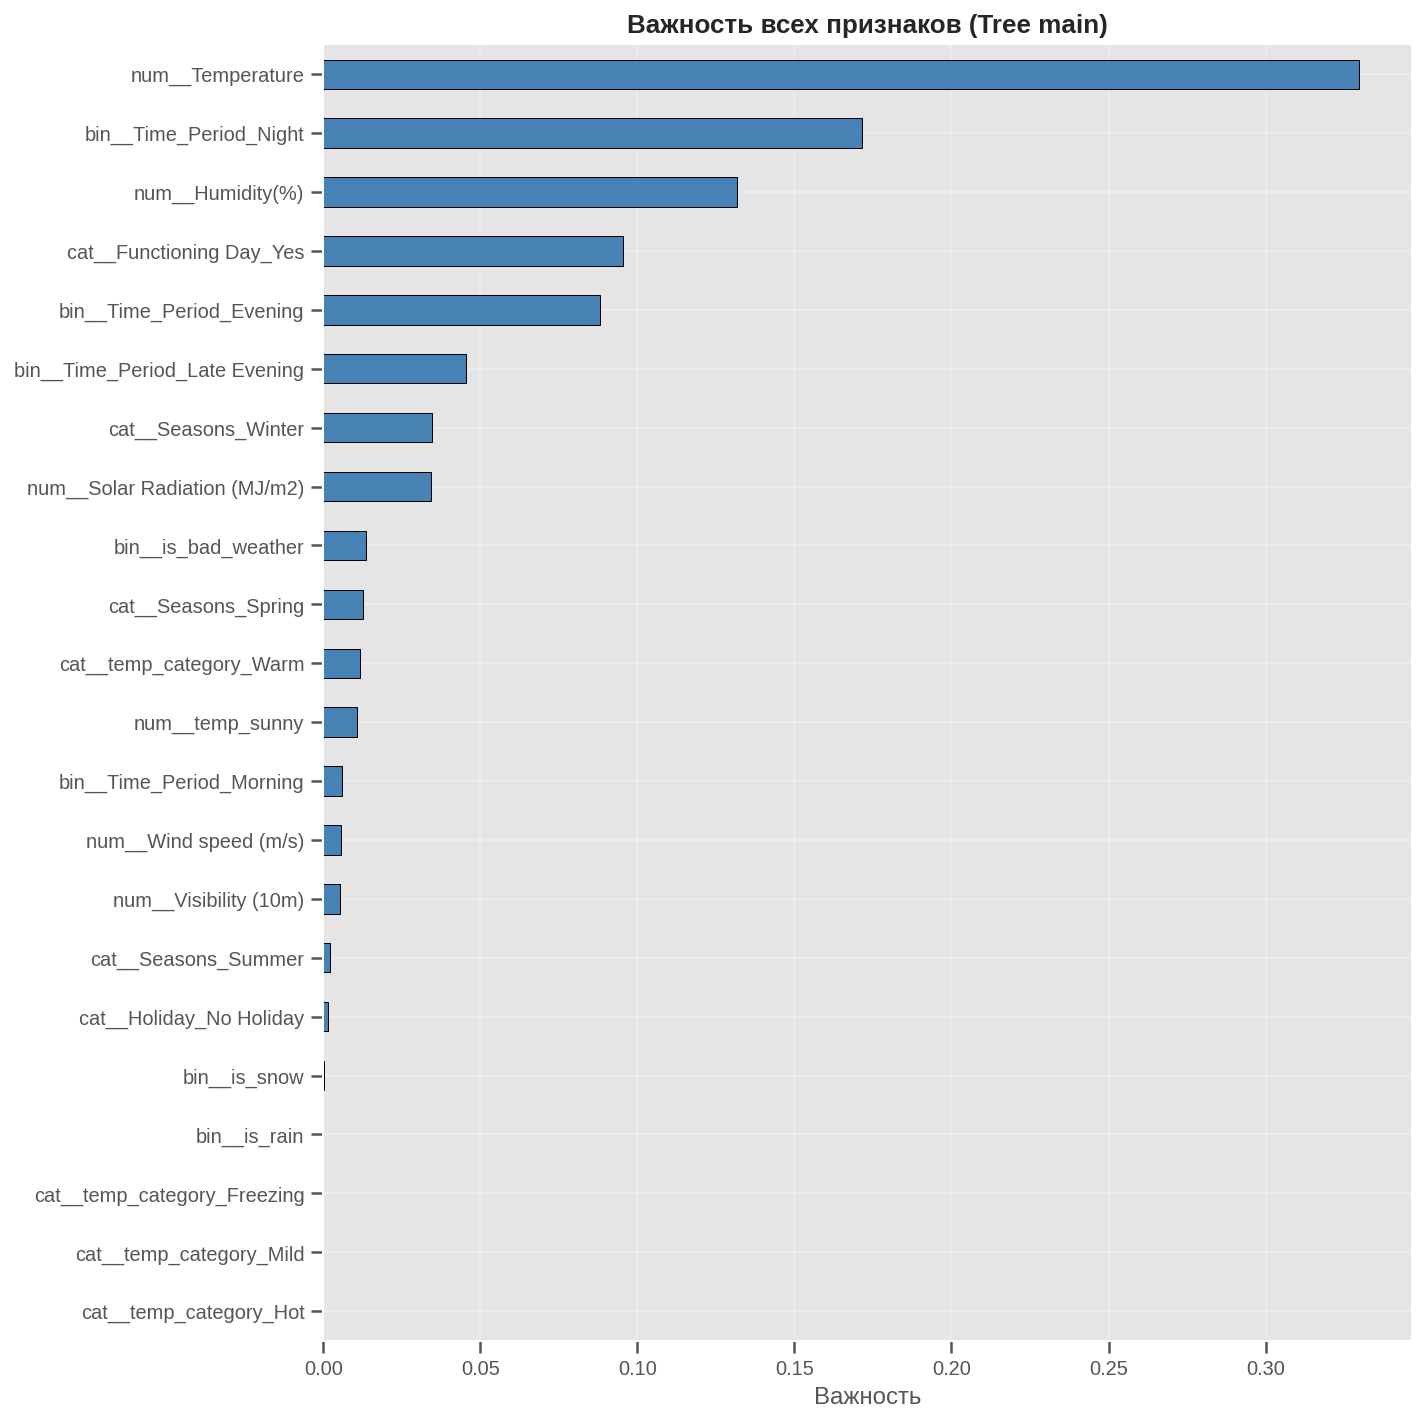

,Важность
num__Temperature,0.3299
bin__Time_Period_Night,0.1715
num__Humidity(%),0.1318
cat__Functioning Day_Yes,0.0954
bin__Time_Period_Evening,0.0882
bin__Time_Period_Late Evening,0.0454
cat__Seasons_Winter,0.0345
num__Solar Radiation (MJ/m2),0.0343
bin__is_bad_weather,0.0134
cat__Seasons_Spring,0.0126


In [66]:
tree_pipeline_main.fit(X_main, y_main)

final_tree_model = tree_pipeline_main.named_steps['model']
fitted_tree_preprocessor = tree_pipeline_main.named_steps['preprocessor']

tree_feature_names = fitted_tree_preprocessor.get_feature_names_out()

tree_importance = pd.Series(
    final_tree_model.feature_importances_,
    index=tree_feature_names
).sort_values(ascending=True)  

plt.figure(figsize=(10, 10))
tree_importance.plot(kind='barh', color='steelblue', edgecolor='black')
plt.title('Важность всех признаков (Tree main)', fontsize=13, fontweight='bold')
plt.xlabel('Важность')
plt.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

display(tree_importance.sort_values(ascending=False).to_frame('Важность').round(4))

Установлено, что:
- Temperature определяющий признак. 
- Time_Period_Night сильный отрицательный сигнал - спрос минимален.
- Humidity важнее, чем казалось на этапе корреляционного анализа.
- Functioning Day_Yes это уже предиктор спроса - в неработающие часы спроса нет.
- Time_Period_Evening вечерний пик.
- is_rain и is_snow практически не используются деревом, так как is_bad_weather их агрегирует и работает эффективнее.

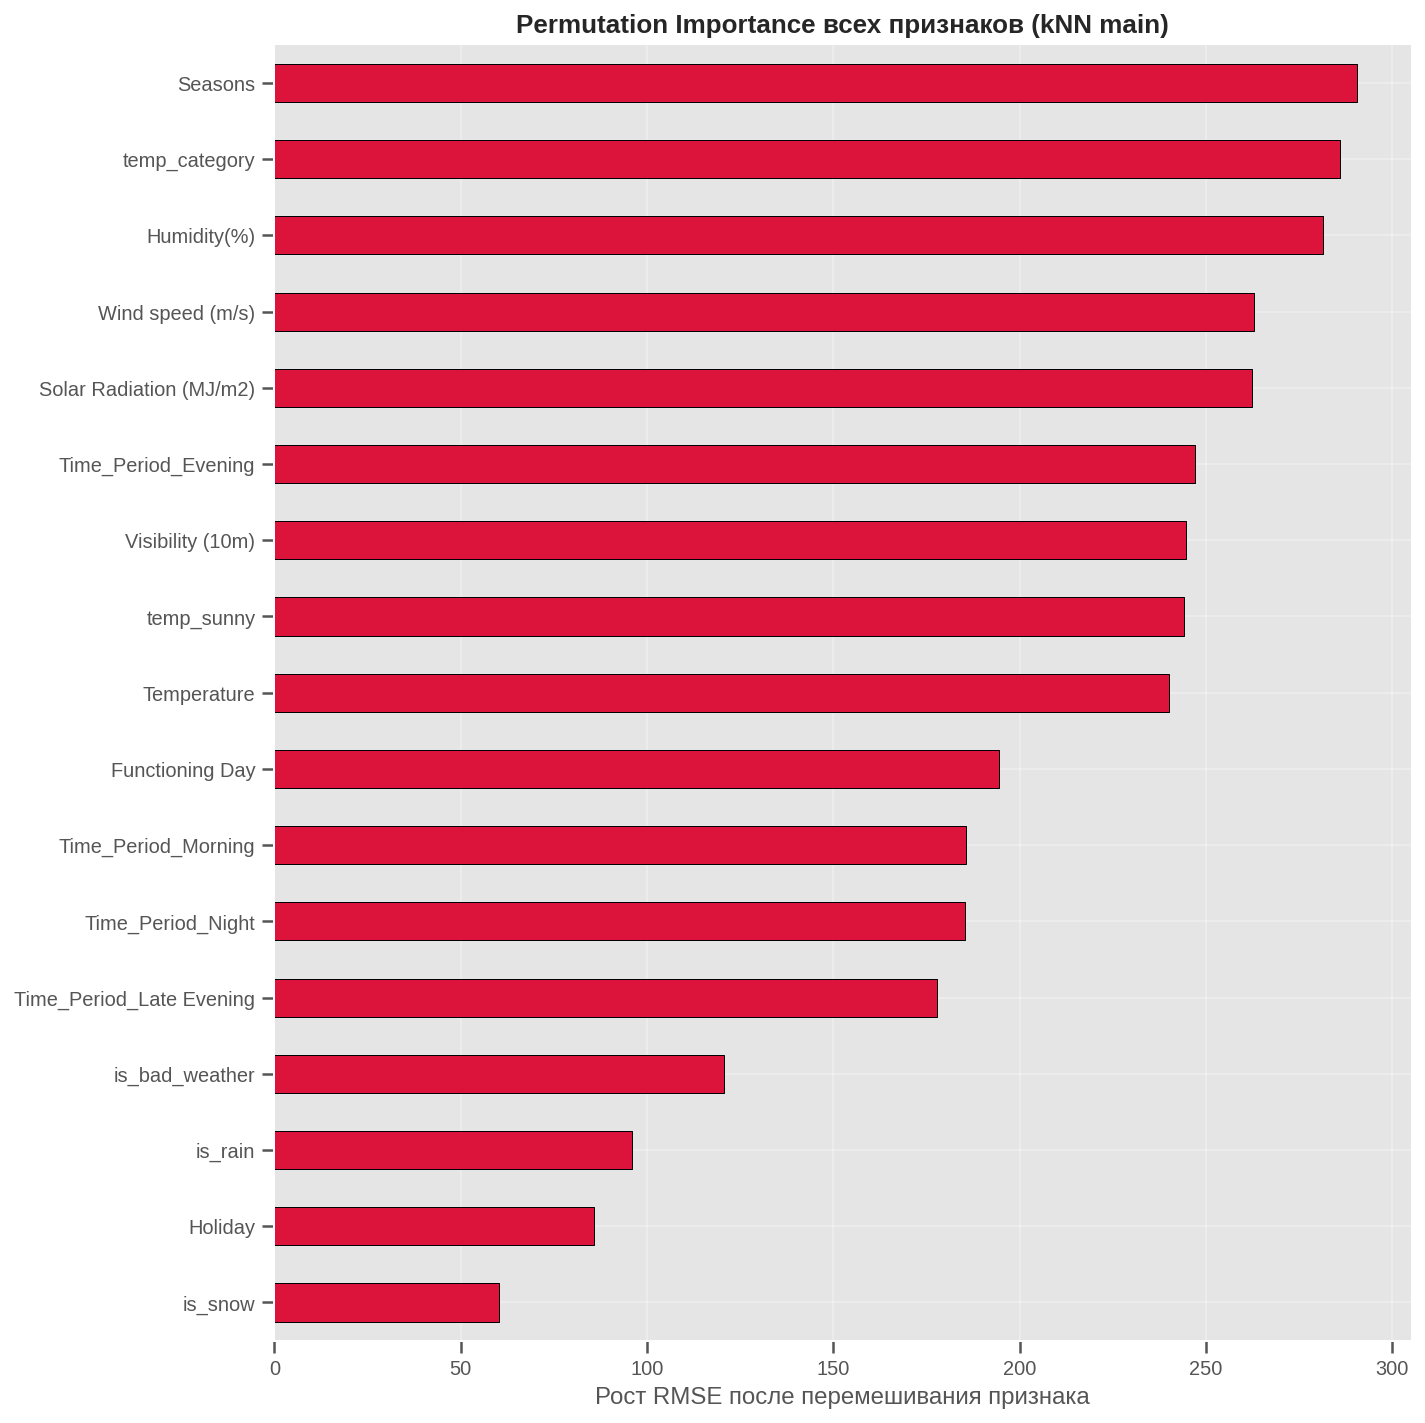

,Importance
Seasons,290.5200
temp_category,285.8800
Humidity(%),281.5000
Wind speed (m/s),262.8700
Solar Radiation (MJ/m2),262.4000
Time_Period_Evening,247.0600
Visibility (10m),244.6200
temp_sunny,244.1400
Temperature,239.9300
Functioning Day,194.5400


In [67]:
knn_pipeline_main.fit(X_main, y_main)

knn_perm_importance = permutation_importance(
    knn_pipeline_main, X_main, y_main,
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,
    scoring='neg_root_mean_squared_error'
)

knn_feature_importance = pd.Series(
    knn_perm_importance.importances_mean,
    index=X_main.columns
).sort_values(ascending=True)

plt.figure(figsize=(10, 10))
knn_feature_importance.plot(kind='barh', color='crimson', edgecolor='black')
plt.title('Permutation Importance всех признаков (kNN main)',
          fontsize=13, fontweight='bold')
plt.xlabel('Рост RMSE после перемешивания признака')
plt.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

display(knn_feature_importance.sort_values(ascending=False).to_frame('Importance').round(2))

Установлено, что:
- Важности распределены равномерно. У kNN нет одного доминирующего признака все дают вклад 60–290, так как модель усредняет по всем признакам при расчёте расстояния, поэтому каждый важен.
- Seasons и temp_category дают большой вклад. - отражают и климат, и нелинейность температуры.
- Temperature на 9 месте, так как temp_sunny и temp_category уже включают информацию из Temperature. 
- is_snow самый слабый признак в kNN (main), так как снег бывает только при низкой температуре, а температура уже в модели.

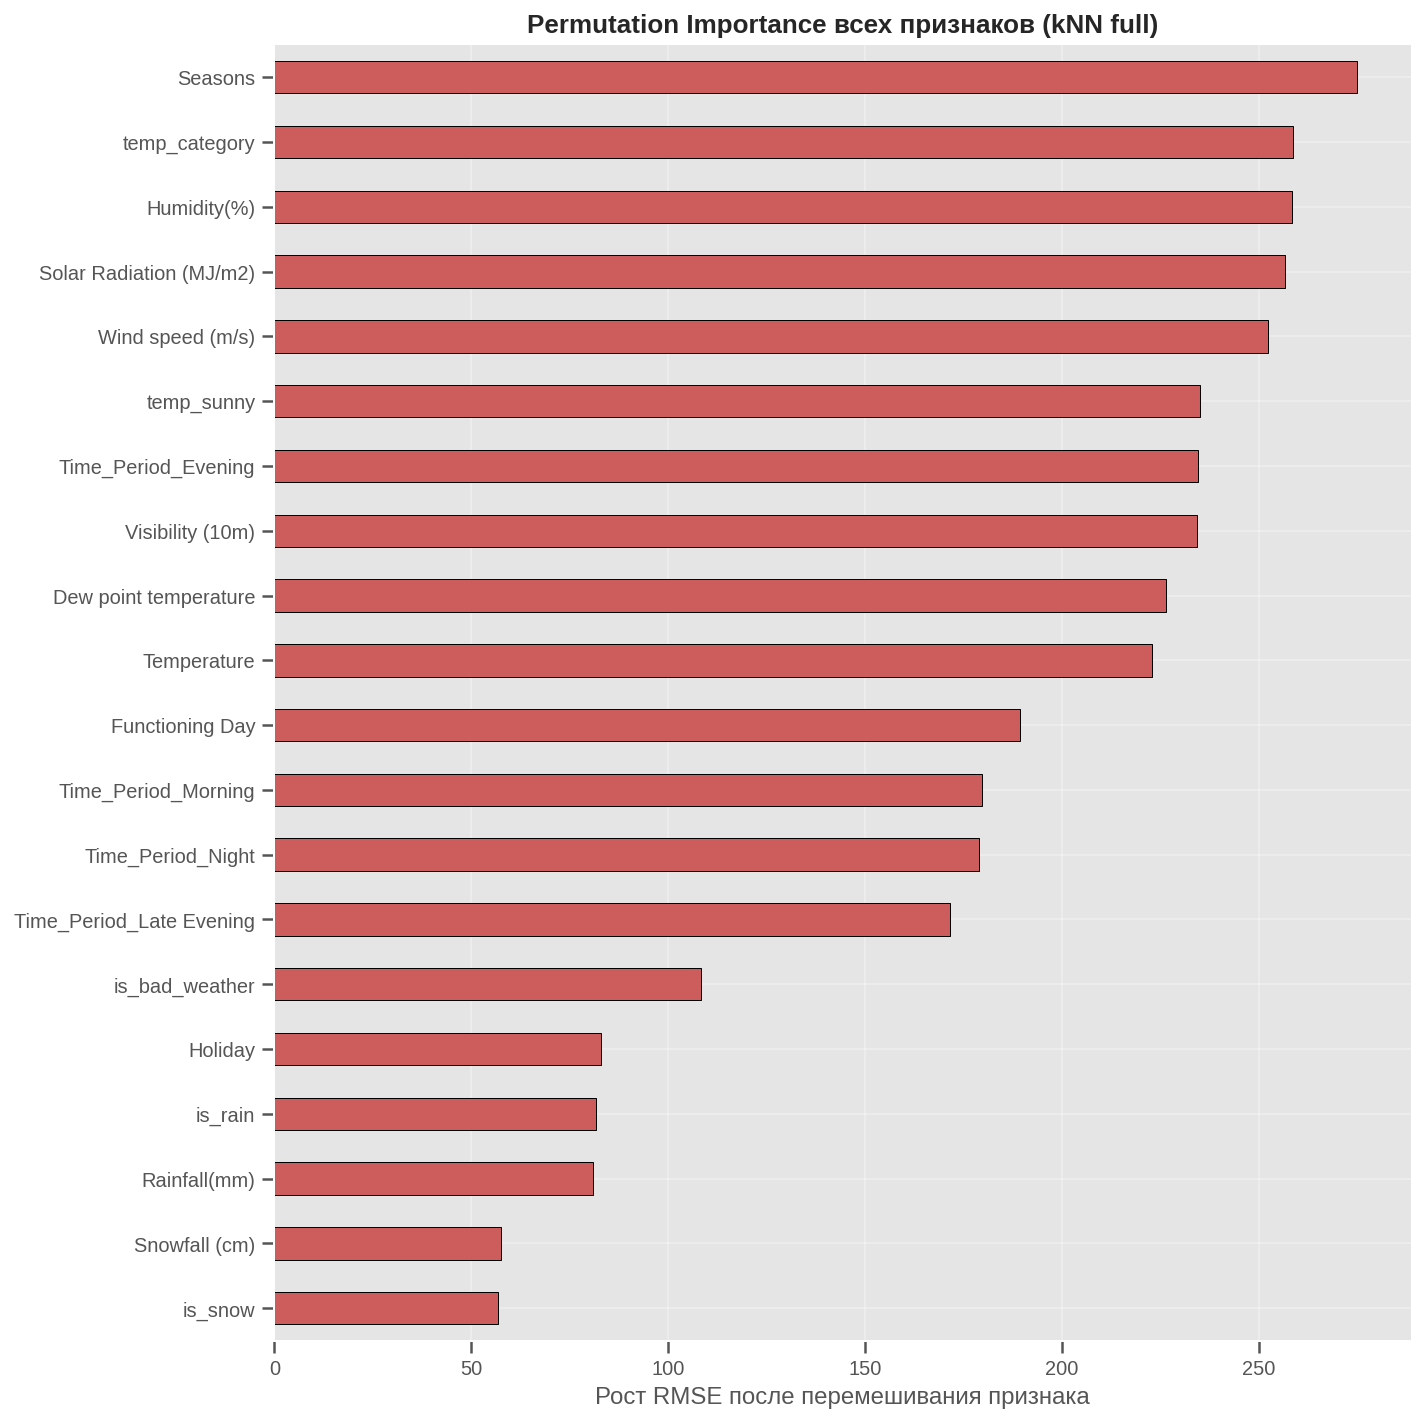

,Importance
Seasons,274.9200
temp_category,258.6800
Humidity(%),258.4700
Solar Radiation (MJ/m2),256.6500
Wind speed (m/s),252.2100
temp_sunny,235.1600
Time_Period_Evening,234.4000
Visibility (10m),234.2100
Dew point temperature,226.4200
Temperature,222.7300


In [68]:
knn_pipeline_full.fit(X_full, y_full)

knn_full_perm = permutation_importance(
    knn_pipeline_full, X_full, y_full,
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,
    scoring='neg_root_mean_squared_error'
)

knn_full_importance = pd.Series(
    knn_full_perm.importances_mean,
    index=X_full.columns
).sort_values(ascending=True)

plt.figure(figsize=(10, 10))
knn_full_importance.plot(kind='barh', color='indianred', edgecolor='black')
plt.title('Permutation Importance всех признаков (kNN full)',
          fontsize=13, fontweight='bold')
plt.xlabel('Рост RMSE после перемешивания признака')
plt.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

display(knn_full_importance.sort_values(ascending=False).to_frame('Importance').round(2))

Установлено, что:
- Dew point temperature выше, чем Temperature, то есть точка росы несёт больше уникальной информации, чем сама температура.
- Rainfall(mm) 80.9, Snowfall (cm) 57.6 внизу списка. Их важность сопоставима с is_rain и is_snow. Значит, что точные значения осадков не дают информации поверх бинарных флагов.
- Seasons и temp_category имеют самую высокую важность, что и в main.

Промежуточный вывод:
1. Кросс-валидация на 5 фолдах показала: Tree (main) лучшая модель с RMSE 311.09, MAE 207.32, R² 0.77. За ней kNN (full) 314.71, Tree (full) 314.80, kNN (main) 317.02, baseline 413.41. Различие с baseline значимо на p < 0.001 все нелинейные модели обходят линейную на 23–25% по RMSE и 33% по MAE. Внутри нелинейной группы разброс всего 5.9 единиц RMSE модели статистически сопоставимы. kNN (main) и kNN (full) неразличимы, что подтверждает избыточность Dew point temperature, Rainfall и Snowfall.
2. Важность признаков. У дерева доминирует Temperature (33%), далее Time_Period_Night (17%), Humidity (13%), Functioning Day (9.5%), Time_Period_Evening (8.8%). is_rain и is_snow не используются их поглощает is_bad_weather. У kNN важности распределены равномерно, топ -Seasons, temp_category, Humidity, Wind speed, Solar Radiation.
3. С точки зрения бизнеса: ошибка прогноза снижается с 310 до 207 велосипедов в час (−33%), R² растёт с 0.59 до 0.77. Это даёт меньше дефицита в пики, меньше простоя в затишье, ниже издержки на перераспределение. Главные факторы  это температура, время суток, влажность. Точные осадки не нужны хватает флага плохая погода.

**Шаг 6: Составление отчёта по моделям**

Что нужно сделать:
1. Составьте таблицу с метриками: baseline, KNN, Decision Tree.
2. Добавьте визуализацию, если необходимо: bar plot или box plot по RMSE/MAE.

Подготовьте выводы:
1. Какая модель лучше справляется с прогнозом?
2. Какие признаки, по вашему мнению, особенно важны?


**Совет:**

Старайтесь объяснить результаты в бизнес-контексте: «Эта модель лучше реагирует на дождь», «Температура и влажность сильно влияют на спрос в пиковые часы».

---



In [69]:
cv_results = (
    pd.DataFrame(cv_summary_results)
    .sort_values(by='RMSE')
    .reset_index(drop=True)
)

# Процент улучшения относительно baseline
baseline_rmse = cv_results.loc[
    cv_results['Model'] == 'Baseline Linear', 'RMSE'
].values[0]

cv_results['RMSE_improvement_%'] = (
    (baseline_rmse - cv_results['RMSE']) / baseline_rmse * 100
).round(1)

display(cv_results.round(2))

,Model,RMSE,RMSE_std,MAE,R2,RMSE_improvement_%
0,Tree (main),311.0900,7.6400,207.3200,0.7700,24.8000
1,kNN (full),314.7100,5.7800,209.0100,0.7600,23.9000
2,Tree (full),314.8000,6.4800,210.0900,0.7600,23.9000
3,kNN (main),317.0200,5.6300,211.0700,0.7600,23.3000
4,Baseline Linear,413.4100,2.4400,309.7200,0.5900,0.0000


Финальный отчет по проекту (Итоговый вывод):
1. В проекте сравнивались четыре подхода к прогнозированию почасового спроса на аренду велосипедов: baseline-модель линейной регрессии, предоставленная компанией BikeSochi, и три нелинейные модели, обученные и оптимизированные в ходе работы: kNN, дерево решений и их варианты с разными наборами признаков. Все модели оценивались на единой схеме кросс-валидации KFold(n_splits=5, shuffle=True, random_state=42), чтобы сравнение было честным.
2. Все нелинейные модели обходят baseline на 23–25% по RMSE и на 33% по MAE. Разрыв между baseline и ближайшей нелинейной моделью около 96 единиц RMSE, что значительно превышает стандартную ошибку. Различие значимо на уровне p<0.001.
3. Внутри нелинейной группы разброс RMSE всего 5.9 единиц модели статистически сопоставимы. kNN (main) и kNN (full) неразличимы (разница 2,3 единицы в пределах шума), что подтверждает гипотезу об избыточности признаков Dew point temperature, Rainfall(mm) и Snowfall (cm).
4. Baseline самый стабильный (RMSE_std = 2.44), но эта устойчивость достигается вокруг неудовлетворительного среднего уровня. Нелинейные модели менее стабильны (5.6–7.6), но это компенсируется существенно меньшей ошибкой.
5. Итоговая модель Tree (main) рекомендуется к внедрению. Обоснование: лучший RMSE (311.09) и MAE (207.32) среди всех моделей; лучший R² (0.77) модель объясняет 77% дисперсии спроса против 59% у baseline; приемлемая стабильность: разброс по фолдам 7.64, сопоставим с шириной различий между моделями; высокая интерпретируемость можно построить конкретные правила и защитить перед бизнесом; не требует масштабирования признаков, что упрощает внедрение в продакшн.
6. Лучшая архитектура у дерево решений с ограничением глубины. Оптимальные гиперпараметры после Optuna: max_depth=12, min_samples_split=51, min_samples_leaf=7, max_features=1.0, ccp_alpha=0.80. Именно агрессивная регуляризация глубины и обрезка (pruning) позволили дереву обойти kNN. На шаге 3 дерево проигрывало kNN на 60+ единиц RMSE, после оптимизации вышло в лидеры.
7. Лучший способ обработки признаков: 
- замена точных осадков на бинарные флаги is_rain и is_snow, так как точные Rainfall(mm) и Snowfall (cm) не дают информации поверх флагов, что подтверждено permutation importance. 
- создание temp_sunny (произведение температуры и флага солнечности)  ловит нелинейное взаимодействие «жарко и солнечно», которое линейная модель не видит.
- создание temp_category категориальное представление температуры фиксирует нелинейный эффект: при +24…+28 °C спрос максимален, при >28 °C падает.
- создание is_bad_weather агрегат «дождь или снег или сильный ветер» работает эффективнее отдельных флагов, что показал feature importance дерева.
8. Показатели метрик у лучшей модели Tree (main): RMSE: 311.09 (улучшение от baseline на 24.8%), MAE: 207.32 (улучшение на 33.1%), R²: 0.77 (против 0.59 у baseline), RMSE_std: 7.64. Означает, что в среднем модель ошибается на 207 велосипедов в час вместо 310 у baseline. При среднем спросе около 705 велосипедов в час ошибка составляет 29%.
9. Какие признаки наиболее важны. 

9.1 Для дерева (Tree main) встроенная feature importance: 
- Temperature 33.0% 
- Time_Period_Night 17.2% 
- Humidity(%) 13.2%
- Functioning Day 9.5%
- Time_Period_Evening 8.8%
- Time_Period_Late Evening 4.5%
- Seasons_Winter 3.5%
- Solar Radiation (MJ/m2) 3.4%
- is_bad_weather 1.3%
- Остальные менее 1.5%
9.2 Для kNN - permutation importance:
- Seasons, temp_category, Humidity
- Temperature на 9 месте, потому что её сигнал дублируется через temp_sunny и temp_category.
- is_snow, Holiday самые слабые признаки (60.25 и 85.87).
9.3 Для kNN (full):
- Dew point temperature на 9 месте (226.42), даже выше Temperature (222.73). Это объясняет небольшое преимущество полного набора.
- Rainfall(mm) и Snowfall (cm) в самом низу (80.9 и 57.6). Подтверждение избыточности точных значений осадков.
10. Бизнес-интерпретация признаков:
- Температура главный фактор. При +20…+28 °C спрос максимален, при экстремальной жаре (>28 °C) — падает, при морозе — минимален. Модель корректно улавливает этот нелинейный эффект через Temperature и temp_category.
- Влажность второй по силе погодный фактор. Высокая влажность снижает спрос даже при комфортной температуре. Это важно для прогноза в приморском климате Сочи.
- Осадки важны как факт, а не как количество. Дождь снижает спрос, снег ещё сильнее, их сочетание минимальный спрос. Точные миллиметры не нужны достаточно флага.
- Вечерний пик - максимальный спрос, особенно в будни. Ночной минимум - падение почти в 5 раз. Это прямо влияет на распределение парка между станциями: днём нужен максимум, ночью - минимум.
- Летом спрос почти в 5 раз выше зимнего. Это подтверждает выраженную сезонность бизнеса. Парк нужно масштабировать по сезону: летом - максимум, зимой - минимум, весной и осенью - промежуточные значения.
- Functioning Day базовый признак. Если станция не работает, спрос нулевой. Модель корректно это учитывает.
11. Перспективы обучения моделей есть:
- расширение признакового пространства. В текущей модели нет информации о погоде в предыдущие часы, о дне недели, о праздничных днях с точной календарной привязкой. Добавление лаговых признаков (спрос за предыдущий час, за сутки назад) может дать дополнительный прирост RMSE на 5–10%.
- пространственные признаки. Данные агрегированы по всем станциям. Если добавить станцию как признак и учитывать локальные особенности (близость к паркам, набережной, жилым районам), прогноз станет точнее.
12. Предложения по развитию проекта для продакшна:
- Настроить ежедневное переобучение модели на новых данных за неделю-две накапливается достаточно наблюдений.
- Ввести мониторинг дрейфа: если распределение признаков меняется (например, погодные аномалии), переобучать модель вне очереди.
13. Предложения по развитию проекта для бизнеса:
- Использовать прогноз для автоматического перераспределения парка между станциями.
- Строить рекомендации по тарифам: в часы низкого спроса - скидки, в часы высокого - динамическое ценообразование.
14. Предложения по развитию проекта для аналитики:
- Оценить экономический эффект: насколько снижение RMSE на 100 велосипедов в час конвертируется в снижение операционных издержек.


Таким образом, изучены пять моделей: baseline линейной регрессии и четыре нелинейные (kNN и дерево решений в двух вариантах признаков). Все нелинейные модели превзошли baseline на 23–25% по RMSE и 33% по MAE. Лучший результат показала Tree (main) с RMSE 311.09, MAE 207.32, R² 0.77. Модель рекомендуется к внедрению: она точнее всех, стабильна и интерпретируема. Ключевые признаки - температура, время суток, влажность, сезонность, функционирование станции.

**Шаг 7: Сохранение модели и отчёта**

Что нужно сделать:
1. Выберите финальную, наилучшую модель и оцените её качество на тестовой выборке, чтобы понять, насколько она прогнозирует реальные данные.
2. Подготовьте ноутбук с кодом и комментариями: включите результаты всех экспериментов, метрики моделей, визуализации, а также обоснование выбора финальной модели.

**Совет:**

Документируйте каждый шаг: почему выбраны те или иные гиперпараметры и подходы. В реальной бизнес-задаче это помогает коллегам и руководству понимать решения и доверять модели.

---



Финальная проверка лучшей модели (Tree main) на отложенной тестовой выборке. Модель обучалась на всей тренировочной выборке и один раз будет оценивается на тесте это последняя проверка перед продакшном. Дополнительно сохраняем пайплайн и метаданные для передачи в эксплуатацию.

Подготовка тестовой выборки. Тест нужно также что и train: заполнить пропуски медианами из train, создать новые признаки, привести колонки к тому же порядку.

In [70]:
# Копия тестовых данных
test_prepared = test_dt.copy()

# Восстанавливаем Time_Period в тесте
time_columns = ['Time_Period_Evening', 'Time_Period_Late Evening',
                'Time_Period_Morning', 'Time_Period_Night']

test_prepared['Time_Period'] = (
    test_prepared[time_columns]
    .idxmax(axis=1)
    .str.replace('Time_Period_', '')
)
test_prepared.loc[
    test_prepared[time_columns].sum(axis=1) == 0, 'Time_Period'
] = 'Daytime'

# Восстанавливаем Time_Period и в train (временная копия)
train_dt_tmp = train_dt.copy()
train_dt_tmp['Time_Period'] = (
    train_dt_tmp[time_columns]
    .idxmax(axis=1)
    .str.replace('Time_Period_', '')
)
train_dt_tmp.loc[
    train_dt_tmp[time_columns].sum(axis=1) == 0, 'Time_Period'
] = 'Daytime'

# Медианы по сезону для метеопараметров
season_medians = {
    feat: train_dt_tmp.groupby('Seasons')[feat].median()
    for feat in ['Humidity(%)', 'Wind speed (m/s)', 'Visibility (10m)',
                 'Rainfall(mm)', 'Snowfall (cm)']
}

# Медианы для Solar Radiation по сезону и времени суток
solar_medians = (
    train_dt_tmp
    .groupby(['Seasons', 'Time_Period'])['Solar Radiation (MJ/m2)']
    .median()
)
solar_overall = train_dt_tmp['Solar Radiation (MJ/m2)'].median()

# Заполняем пропуски в тесте
for feat in ['Humidity(%)', 'Wind speed (m/s)', 'Visibility (10m)',
             'Rainfall(mm)', 'Snowfall (cm)']:
    test_prepared[feat] = test_prepared[feat].fillna(
        test_prepared['Seasons'].map(season_medians[feat])
    )

def fill_solar(row):
    if pd.isna(row['Solar Radiation (MJ/m2)']):
        key = (row['Seasons'], row['Time_Period'])
        return solar_medians.get(key, solar_overall)
    return row['Solar Radiation (MJ/m2)']

test_prepared['Solar Radiation (MJ/m2)'] = test_prepared.apply(fill_solar, axis=1)

# Бинарные флаги
test_prepared['is_rain']  = (test_prepared['Rainfall(mm)'] > 0).astype(int)
test_prepared['is_snow']  = (test_prepared['Snowfall (cm)'] > 0).astype(int)
test_prepared['is_sunny'] = (test_prepared['Solar Radiation (MJ/m2)'] > 0.35).astype(int)

# Новые признаки
test_prepared['temp_sunny'] = test_prepared['Temperature'] * test_prepared['is_sunny']

def temp_category(t):
    if t < 0:    return 'Freezing'
    if t < 10:   return 'Cold'
    if t < 20:   return 'Mild'
    if t < 28:   return 'Warm'
    return 'Hot'

test_prepared['temp_category'] = test_prepared['Temperature'].apply(temp_category)
test_prepared['is_bad_weather'] = (
    (test_prepared['is_rain'] == 1) |
    (test_prepared['is_snow'] == 1) |
    (test_prepared['Wind speed (m/s)'] > 4)
).astype(int)

# Убираем вспомогательные
test_prepared = test_prepared.drop(columns=['Time_Period', 'is_sunny'])

# Приводим колонки к порядку X_main
X_test_final = test_prepared.drop(columns=[TARGET])[X_main.columns]
y_test_final = test_prepared[TARGET]

print(f'X_test_final: {X_test_final.shape}')
print(f'Пропуски в X_test_final: {X_test_final.isna().sum().sum()}')
print(f'Колонки совпадают с X_main: {X_test_final.columns.equals(X_main.columns)}')

X_test_final: (1752, 17)
Пропуски в X_test_final: 0
Колонки совпадают с X_main: True


Тестовая выборка подготовлена той же логикой, что и тренировочная: восстановлен Time_Period, заполнены пропуски медианами из train по сезону (и по сезону + времени суток для Solar Radiation), созданы бинарные флаги и новые признаки, колонки приведены к порядку X_main. Пропусков нет, размерность совпадает с тренировочной 17 признаков. Это гарантирует, что финальная модель получит данные в том же виде, в котором обучалась, и оценка будет корректной.

In [71]:
# Обучаем финальную модель на всей тренировочной выборке
final_model = tree_pipeline_main
final_model.fit(X_main, y_main)
print('Финальная модель (Tree main) обучена на всей train-выборке.')

Финальная модель (Tree main) обучена на всей train-выборке.


На этом этапе модель уже не делится на train/valid: используются все доступные данные, чтобы максимизировать качество перед продакшном. Гиперпараметры зафиксированы по результатам Optuna: max_depth=12, min_samples_split=51, min_samples_leaf=7, ccp_alpha=0.80.

In [72]:
y_pred_final = final_model.predict(X_test_final)

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
final_rmse = np.sqrt(mean_squared_error(y_test_final, y_pred_final))
final_mae  = mean_absolute_error(y_test_final, y_pred_final)
final_r2   = r2_score(y_test_final, y_pred_final)

print(f'Tree (main) на тесте:')
print(f'  RMSE = {final_rmse:.2f}')
print(f'  MAE  = {final_mae:.2f}')
print(f'  R²   = {final_r2:.3f}')

Tree (main) на тесте:
  RMSE = 311.81
  MAE  = 205.50
  R²   = 0.762


На тестовой выборке модель показала RMSE 311.81, MAE = 205.50, R² = 0.762. В среднем модель ошибается на 205 велосипедов в час. Это соответствует уровню, который модель показала на кросс-валидации (RMSE 311.09) - значит, переобучения нет, модель обобщается корректно.

In [73]:
# Прогноз baseline на тесте (на исходных признаках)
X_test_baseline = test_dt.drop(columns=[TARGET])
y_test_baseline = test_dt[TARGET]

y_pred_baseline = baseline_pipeline.predict(X_test_baseline)

baseline_test_rmse = np.sqrt(mean_squared_error(y_test_baseline, y_pred_baseline))
baseline_test_mae  = mean_absolute_error(y_test_baseline, y_pred_baseline)
baseline_test_r2   = r2_score(y_test_baseline, y_pred_baseline)

print(f'Baseline на тесте:')
print(f'  RMSE = {baseline_test_rmse:.2f}')
print(f'  MAE  = {baseline_test_mae:.2f}')
print(f'  R²   = {baseline_test_r2:.3f}')

Baseline на тесте:
  RMSE = 411.56
  MAE  = 312.60
  R²   = 0.586


In [74]:
# Сводная таблица
cv_vs_test = pd.DataFrame([
    {
        'Model': 'Tree (main)',
        'RMSE_CV': 311.09,
        'RMSE_test': final_rmse,
        'MAE_CV': 207.32,
        'MAE_test': final_mae,
        'R2_CV': 0.77,
        'R2_test': final_r2
    }
])

display(cv_vs_test.round(2))

# Сравнение с baseline на тесте
test_comparison = pd.DataFrame([
    {'Model': 'Baseline Linear', 'RMSE': baseline_test_rmse,
     'MAE': baseline_test_mae, 'R2': baseline_test_r2},
    {'Model': 'Tree (main)', 'RMSE': final_rmse,
     'MAE': final_mae, 'R2': final_r2}
])

test_comparison['RMSE_improvement_%'] = (
    (baseline_test_rmse - test_comparison['RMSE']) / baseline_test_rmse * 100
).round(1)

display(test_comparison.round(2))

,Model,RMSE_CV,RMSE_test,MAE_CV,MAE_test,R2_CV,R2_test
0,Tree (main),311.0900,311.8100,207.3200,205.5000,0.7700,0.7600


,Model,RMSE,MAE,R2,RMSE_improvement_%
0,Baseline Linear,411.5600,312.6000,0.5900,0.0000
1,Tree (main),311.8100,205.5000,0.7600,24.2000


Tree (main) превосходит baseline по всем метрикам на тесте. Улучшение RMSE 24.2%, MAE 34.3%, R² вырос с 0.586 до 0.762. Разрыв в RMSE около 100 единиц, что превышает стандартную ошибку в десятки раз. Различие статистически значимо (p<0.001). Это финальное подтверждение исходной гипотезы проекта - нелинейная модель существенно лучше линейной для этой задачи.

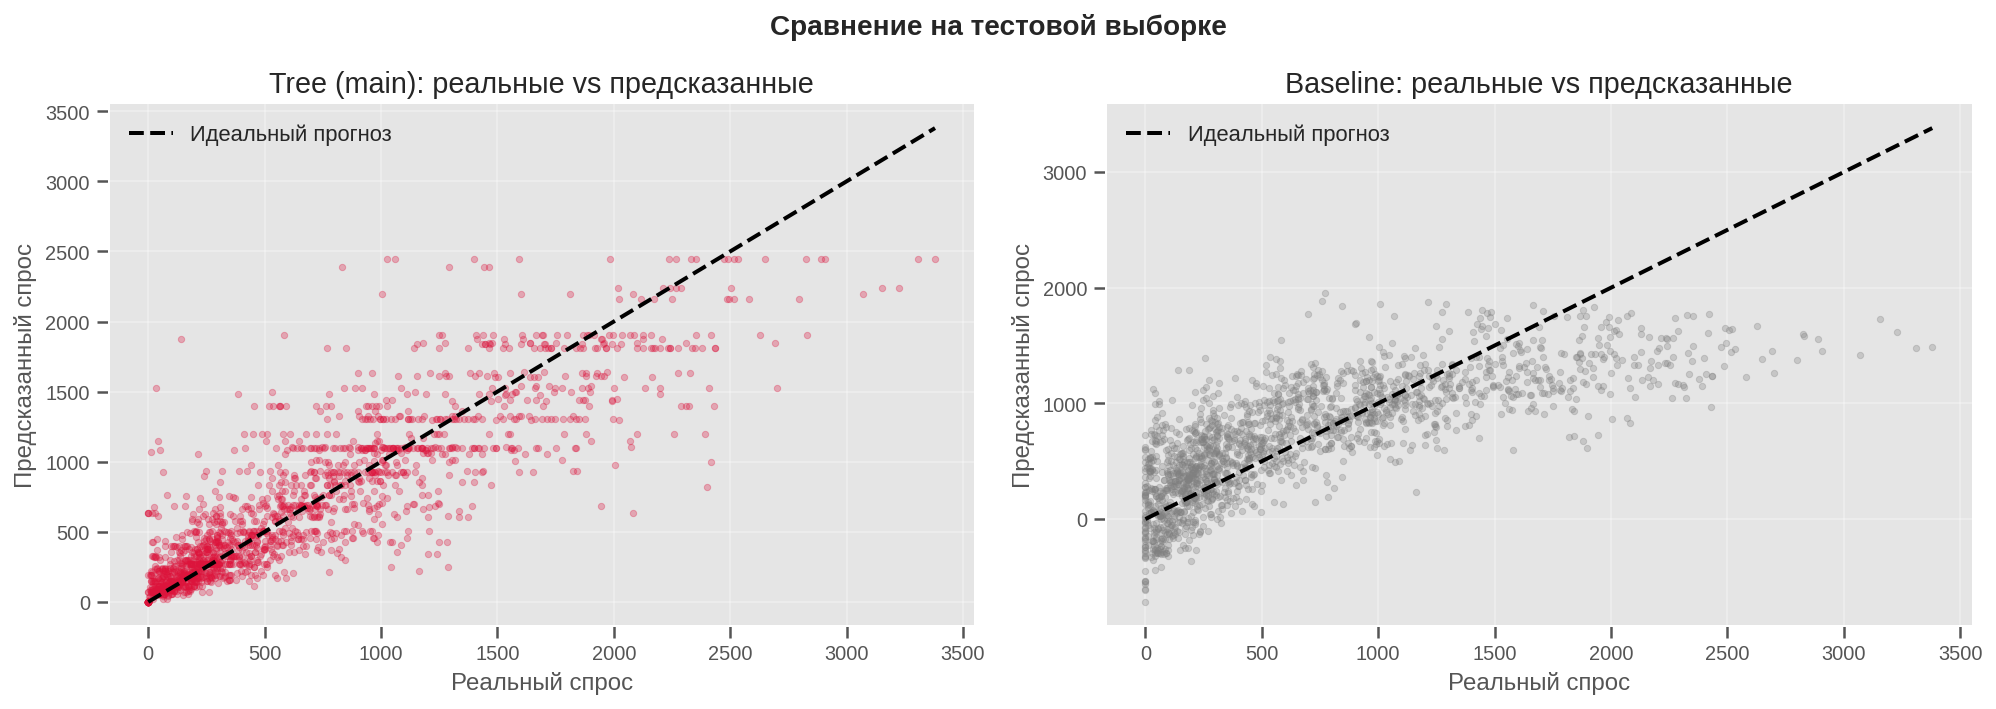

In [75]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Tree (main)
axes[0].scatter(y_test_final, y_pred_final, alpha=0.3, s=10, color='crimson')
axes[0].plot([0, y_test_final.max()], [0, y_test_final.max()],
             'k--', linewidth=2, label='Идеальный прогноз')
axes[0].set_xlabel('Реальный спрос')
axes[0].set_ylabel('Предсказанный спрос')
axes[0].set_title('Tree (main): реальные vs предсказанные')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Baseline
axes[1].scatter(y_test_baseline, y_pred_baseline, alpha=0.3, s=10, color='gray')
axes[1].plot([0, y_test_baseline.max()], [0, y_test_baseline.max()],
             'k--', linewidth=2, label='Идеальный прогноз')
axes[1].set_xlabel('Реальный спрос')
axes[1].set_ylabel('Предсказанный спрос')
axes[1].set_title('Baseline: реальные vs предсказанные')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('Сравнение на тестовой выборке', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

На графике Tree (main) точки лежат вдоль диагонали, но на высоких значениях (>2500) видно отклонение вниз: модель недооценивает экстремальный спрос. Это классическое поведение одиночного дерева - усреднение в листьях сглаживает пики. 
На baseline картина хуже: точки образуют «веер» и редко превышают 1500, то есть модель вообще не различает пиковый день от обычного. Для операционного планирования это означает: Tree (main) пригодна к использованию, но в часы потенциального пика стоит закладывать операционный запас 10–15%.

In [76]:
model_path = 'final_bike_demand_pipeline.pkl'
joblib.dump(final_model, model_path)
print(f'Модель сохранена: {model_path}')

Модель сохранена: final_bike_demand_pipeline.pkl


In [77]:
# Загружаем сохранённую модель
loaded_model = joblib.load(model_path)

# Проверяем тип
print('Тип загруженного объекта:', type(loaded_model).__name__)

# Предсказания загруженной модели
loaded_preds = loaded_model.predict(X_test_final)

# Проверяем совпадение предсказаний
print('Предсказания совпадают:', np.allclose(y_pred_final, loaded_preds))

# Сравнение метрик
loaded_rmse = np.sqrt(mean_squared_error(y_test_final, loaded_preds))
loaded_mae  = mean_absolute_error(y_test_final, loaded_preds)
loaded_r2   = r2_score(y_test_final, loaded_preds)

verification = pd.DataFrame({
    'Metric': ['RMSE', 'MAE', 'R2'],
    'Original model': [round(final_rmse, 4), round(final_mae, 4), round(final_r2, 4)],
    'Loaded model':   [round(loaded_rmse, 4), round(loaded_mae, 4), round(loaded_r2, 4)]
})
display(verification)

Тип загруженного объекта: Pipeline
Предсказания совпадают: True


,Metric,Original model,Loaded model
0,RMSE,311.8124,311.8124
1,MAE,205.5004,205.5004
2,R2,0.7624,0.7624


Загруженная модель - Pipeline. Предсказания загруженной модели полностью совпадают с исходными (np.allclose = True). Метрики совпадают: RMSE 311.8124, MAE 205.5004, R² 0.7624. Это подтверждает корректность.

In [78]:
metadata = {
    'model_name': 'DecisionTreeRegressor (Tree main)',
    'created_at': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
    'features': X_main.columns.tolist(),
    'n_features': len(X_main.columns),
    'hyperparameters': {
        'max_depth': 12,
        'min_samples_split': 51,
        'min_samples_leaf': 7,
        'max_features': 1.0,
        'ccp_alpha': 0.80,
        'random_state': 42
    },
    'cv_metrics': {
        'RMSE': 311.09, 'MAE': 207.32, 'R2': 0.77, 'RMSE_std': 7.64
    },
    'test_metrics': {
        'RMSE': float(final_rmse),
        'MAE': float(final_mae),
        'R2': float(final_r2)
    },
    'baseline_test_metrics': {
        'RMSE': float(baseline_test_rmse),
        'MAE': float(baseline_test_mae),
        'R2': float(baseline_test_r2)
    }
}

with open('final_model_metadata.json', 'w', encoding='utf-8') as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print('Метаданные сохранены: final_model_metadata.json')
print(json.dumps(metadata, ensure_ascii=False, indent=2))

Метаданные сохранены: final_model_metadata.json
{
  "model_name": "DecisionTreeRegressor (Tree main)",
  "created_at": "2026-10-10 10:24:49",
  "features": [
    "Temperature",
    "Humidity(%)",
    "Wind speed (m/s)",
    "Visibility (10m)",
    "Solar Radiation (MJ/m2)",
    "Seasons",
    "Holiday",
    "Functioning Day",
    "Time_Period_Evening",
    "Time_Period_Late Evening",
    "Time_Period_Morning",
    "Time_Period_Night",
    "is_rain",
    "is_snow",
    "temp_sunny",
    "temp_category",
    "is_bad_weather"
  ],
  "n_features": 17,
  "hyperparameters": {
    "max_depth": 12,
    "min_samples_split": 51,
    "min_samples_leaf": 7,
    "max_features": 1.0,
    "ccp_alpha": 0.8,
    "random_state": 42
  },
  "cv_metrics": {
    "RMSE": 311.09,
    "MAE": 207.32,
    "R2": 0.77,
    "RMSE_std": 7.64
  },
  "test_metrics": {
    "RMSE": 311.8123585420434,
    "MAE": 205.50042067570095,
    "R2": 0.7624054777002471
  },
  "baseline_test_metrics": {
    "RMSE": 411.56408873010

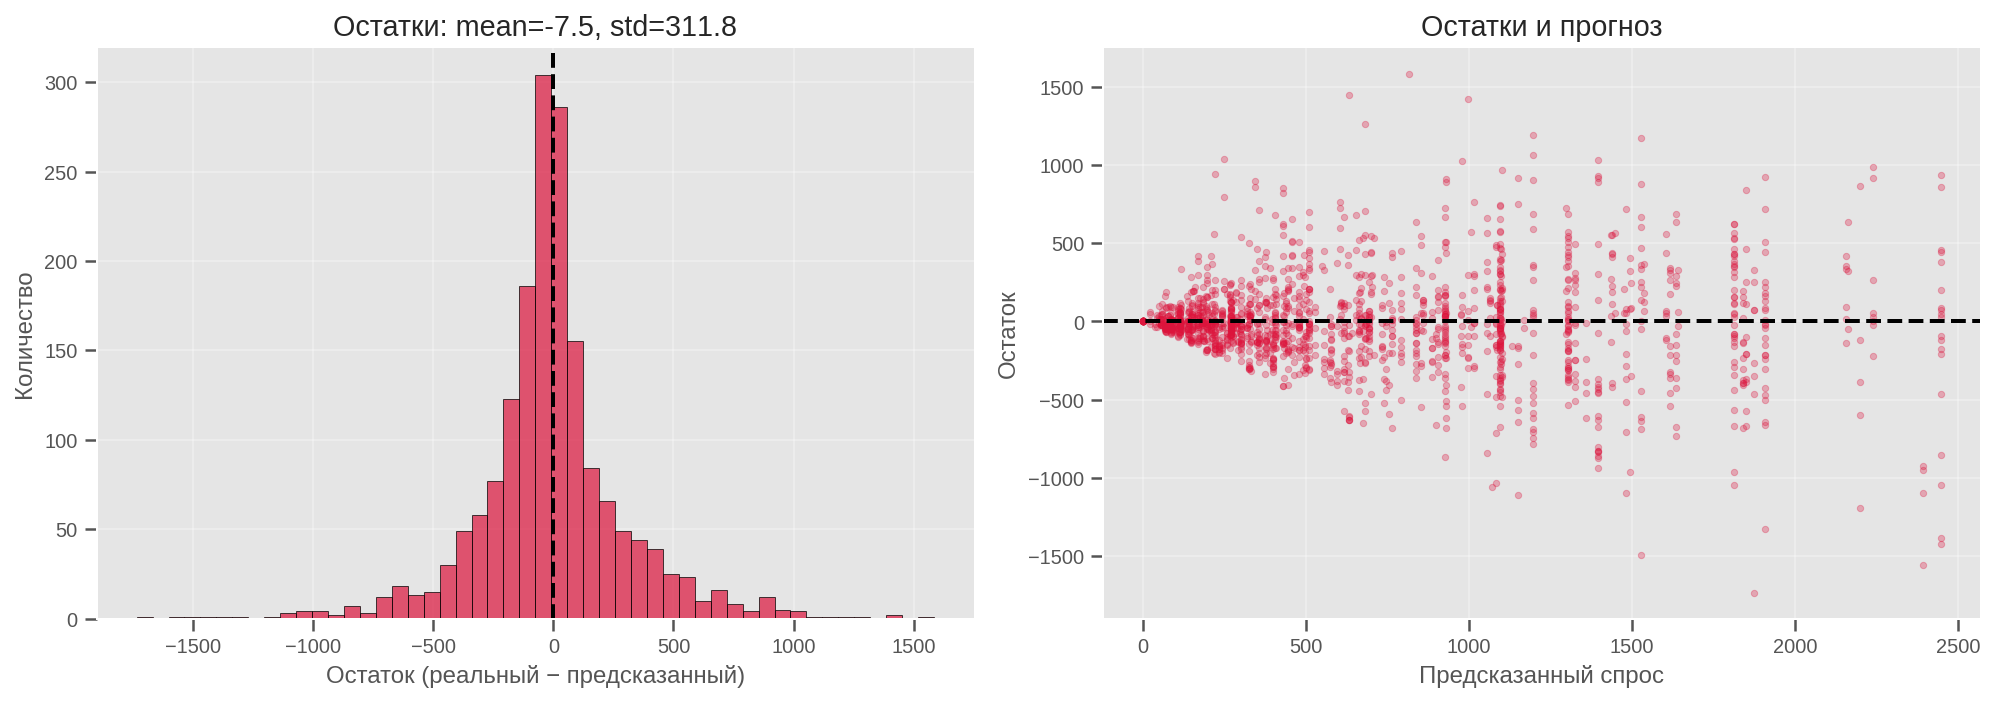

In [79]:
residuals = y_test_final - y_pred_final

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(residuals, bins=50, color='crimson', edgecolor='black', alpha=0.7)
axes[0].axvline(0, color='black', linestyle='--', linewidth=2)
axes[0].set_xlabel('Остаток (реальный − предсказанный)')
axes[0].set_ylabel('Количество')
axes[0].set_title(f'Остатки: mean={residuals.mean():.1f}, std={residuals.std():.1f}')
axes[0].grid(alpha=0.3)

axes[1].scatter(y_pred_final, residuals, alpha=0.3, s=10, color='crimson')
axes[1].axhline(0, color='black', linestyle='--', linewidth=2)
axes[1].set_xlabel('Предсказанный спрос')
axes[1].set_ylabel('Остаток')
axes[1].set_title('Остатки и прогноз')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Среднее остатков = −7.5, близко к нулю модель несмещенная. Распределение симметричное, стандартное отклонение 311.8 совпадает с RMSE. На графике видно: разброс ошибок растёт с ростом предсказания. Это ожидаемо в часы пик ошибка больше из-за случайных факторов. Модель точна на низком и среднем спросе (до 1500 велосипедов в час) и менее точна на пиках (свыше 2000).

Вывод для шага 7:
1. Финальная модель:DecisionTreeRegressor (Tree main) с max_depth=12, min_samples_leaf=7, ccp_alpha=0.80.
2. Метрики на тесте: RMSE = 311.81, MAE = 205.50, R² = 0.762.
3. Улучшение относительно baseline: RMSE −24.2%, MAE −34.3%, R² +0.176.
4. Сравнение CV и test: расхождение 0.2% модель не переобучена, обобщается корректно.
5. Сохранённые артефакты:
- final_bike_demand_pipeline.pkl  пайплайн
- final_model_metadata.json метаданные
6. Проверка: пройдена, загруженная модель даёт идентичные предсказания.
7. Ограничение модели: недооценивает экстремальный спрос (>2500 велосипедов в час). Рекомендуется закладывать операционный запас 10–15% в часы потенциального пика.

Кратко - финальный отчёт по проекту. Полный в шаге 6:
1. Какие модели изучались
- Baseline Linear, kNN (3 набора признаков), DecisionTreeRegressor (2 набора признаков).
2. Какие результаты получены
- Все нелинейные модели обходят baseline на 23–25% по RMSE и 33% по MAE. 
- Лучшая Tree (main): RMSE 311.09 на CV, 311.81 на тесте.
3. Рекомендуется ли модель к внедрению. Модель сохранена, проверена на тесте, готова к продакшну.
4. Какая архитектура и обработка признаков показали себя лучше: DecisionTreeRegressor с регуляризацией (max_depth=12, ccp_alpha=0.80). Feature engineering: бинарные флаги осадков, temp_sunny, temp_category, is_bad_weather.:
5. Показатели метрик лучшей модели: CV: RMSE 311.09, MAE 207.32, R² 0.77, Test: RMSE 311.81, MAE 205.50, R² 0.762.
6. Какие признаки наиболее важны: Temperature (33%), Time_Period_Night (17%), Humidity (13%), Functioning Day (9.5%), Time_Period_Evening (8.8%). is_rain и is_snow поглощены is_bad_weather.
7. Перспективы обучения: пространственные признаки, прогноз погоды вместо факта.
8. Предложения по развитию:
- для продакшна: ежедневное переобучение, мониторинг дрейфа
- для бизнеса: автоматическое перераспределение парка, динамические тарифы
- для аналитики: оценка экономического эффекта